**Требования к отчётам**

1. Ответы оформляются в соответствующих полях после заданий;
2. **Описание:** какие функции оптимизируются; как генерируются данные или какие датасеты используются (размер $m \times n$, плотность или разреженность матрицы); на каком компьютере (CPU, RAM); какие методы и с какими параметрами запускались.
3. **Результаты:** графики, таблицы и т. д.
4. **Выводы:** какая зависимость наблюдается, почему, и как это согласуется с теорией из лекций.

**Важно:**
* Каждый график должен быть прокомментирован в тексте: что на нём изображено и какие выводы из него следуют.
* Оси подписаны; если на графике несколько кривых, есть легенда; линии достаточно толстые, чтобы их было хорошо видно.

# Лабораторная работа 1. Методы градиентного спуска и метод Ньютона

**Срок сдачи:** 7 ноября 23:59

**Что нужно сдать**
1. Этот ноутбук с реализованными функциями и кодом всех экспериментов. Все результаты должны воспроизводиться: если используется случайность, зафиксируйте `seed`.

Работа выполняется самостоятельно.

## План выполнения

1. Реализовать линейный поиск (`LineSearchTool.line_search`) и градиентный спуск (`gradient_descent`).
2. Вывести функцию, градиент и гессиан для определенных ниже **двух функций потерь** в матрично-векторной форме, с учётом L2-регуляризатора.
3. Реализовать функции потерь и общий оракул (п. 2.4)`LinearModelL2Oracle` (с поддержкой `np.ndarray` и `scipy.sparse.csr_matrix`).
4. Реализовать оракул  невыпуклой 2D-функции (градиент и гессиан).
5. Реализовать разностные производные (`grad_finite_diff`, `hess_finite_diff`) и с их помощью проверить все ваши оракулы.
6. Реализовать метод Ньютона (`newton`).
7. Прогнать проверочные тесты (раздел «Проверка реализации»).
8. Провести эксперименты 1–7.

In [17]:
import time
from pathlib import Path
from collections import defaultdict

import numpy as np
from numpy.linalg import LinAlgError
import scipy
import scipy.sparse
import scipy.linalg
import scipy.optimize
from scipy.special import expit, log_ndtr
import matplotlib.pyplot as plt
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print

SEED = 42
np.random.seed(SEED)

RUN_DIR = Path('.')
DATA_DIR = Path('/content/data') if Path('/content').is_dir() else Path('data')
FIGURES_DIR = RUN_DIR / 'figures'
RESULTS_DIR = RUN_DIR / 'results'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# 1. Алгоритмы

## 1.1 Методы спуска: общая схема

Рассматривается задача гладкой безусловной оптимизации $\min_{x \in \mathbb{R}^n} f(x)$. Методы спуска строят последовательность
$$x_{k+1} = x_k + \alpha_k d_k,$$
где $\alpha_k \ge 0$ — длина шага, а $d_k$ — направление спуска, т. е. $\langle \nabla f(x_k), d_k \rangle < 0$.

**Алгоритм 1. Общая схема метода спуска**

**Вход:** начальная точка $x_0$; максимальное число итераций $K$.

1. **for** $k \leftarrow 0$ **to** $K$ **do**
2. &emsp; **(Вызов оракула)** Вычислить $f(x_k)$, $\nabla f(x_k)$ и пр.
3. &emsp; **(Критерий остановки)** Если выполнен критерий остановки, то выход.
4. &emsp; **(Вычисление направления)** Вычислить направление спуска $d_k$.
5. &emsp; **(Линейный поиск)** Найти подходящую длину шага $\alpha_k$.
6. &emsp; **(Обновление)** $x_{k+1} \leftarrow x_k + \alpha_k d_k$.
7. **end for**

**Выход:** последняя вычисленная точка $x_k$.

## 1.2 Критерий остановки

Если оптимальное значение $f^*$ неизвестно, используют критерий по норме градиента $\|\nabla f(x_k)\|_2^2 < \tilde\varepsilon$. Квадрат здесь ставят потому, что для «хороших» функций (например, сильно выпуклых с липшицевым градиентом) невязка $f(x_k) - f^*$ имеет тот же порядок, что и $\|\nabla f(x_k)\|_2^2$, а не $\|\nabla f(x_k)\|_2$: если $\|\nabla f(x_k)\|_2 \sim 10^{-5}$, то $f(x_k) - f^* \sim 10^{-10}$.

Чтобы критерий не зависел от масштаба функции (не менялся при переходе от $f$ к $tf$, $t > 0$), используется относительный вариант:
$$\|\nabla f(x_k)\|_2^2 \le \varepsilon \, \|\nabla f(x_0)\|_2^2, \qquad \varepsilon \in (0, 1). \tag{1}$$

**Во всех методах этой работы используйте критерий (1).**

## 1.3 Линейный поиск

Обозначим $\phi_k(\alpha) := f(x_k + \alpha d_k)$, тогда $\phi_k'(\alpha) = \langle \nabla f(x_k + \alpha d_k), d_k \rangle$ и $\phi_k'(0) < 0$.

**Условие Армихо:** $\phi_k(\alpha) \le \phi_k(0) + c_1 \alpha \phi_k'(0)$, где $c_1 \in (0, 0.5)$.

**Алгоритм 2. Дробление шага (бэктрекинг)**

**Вход:** функция $\phi_k$, начальный шаг $\alpha_k^{(0)}$.
1. $\alpha \leftarrow \alpha_k^{(0)}$
2. **while** $\phi_k(\alpha) > \phi_k(0) + c_1 \alpha \phi_k'(0)$ **do** $\alpha \leftarrow \alpha / 2$

**Выход:** $\alpha$.

**Адаптивный** вариант запоминает шаг $\alpha_k$ с текущей итерации и на следующей начинает дробление с $\alpha_{k+1}^{(0)} := 2\alpha_k$.

**Сильные условия Вульфа:**
$$\phi_k(\alpha) \le \phi_k(0) + c_1 \alpha \phi_k'(0), \qquad |\phi_k'(\alpha)| \le c_2 |\phi_k'(0)|, \qquad 0 < c_1 < c_2 < 1.$$

Реализовывать поиск по условиям Вульфа самостоятельно не нужно: используйте [`scipy.optimize.line_search`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize_scalar.html). Иногда эта функция не сходится и возвращает `None`. В этом случае запустите бэктрекинг по условию Армихо.

Для точного одномерного поиска (методы `'Brent'` и `'Golden'`) используйте [`scipy.optimize.minimize_scalar`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize_scalar.html).

## 1.4 Градиентный спуск

$x_{k+1} = x_k - \alpha_k \nabla f(x_k)$, т. е. $d_k = -\nabla f(x_k)$; шаг $\alpha_k$ подбирается линейным поиском.

## 1.5 Метод Ньютона

$x_{k+1} = x_k - \alpha_k [\nabla^2 f(x_k)]^{-1} \nabla f(x_k)$.

Для локальной квадратичной сходимости важно использовать единичный шаг, поэтому линейный поиск всегда сначала пробует $\alpha = 1$. В зоне квадратичной сходимости единичный шаг удовлетворяет условиям Армихо/Вульфа и принимается автоматически, а вдали от решения линейный поиск его уменьшает и тем самым обеспечивает глобальную сходимость.

Направление находится из системы $\nabla^2 f(x_k)\, d_k = -\nabla f(x_k)$. Явно обращать гессиан (`np.linalg.inv`) или использовать общий решатель (`np.linalg.solve`) не нужно. Если гессиан положительно определён, используйте разложение Холецкого ([`scipy.linalg.cho_factor`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.cho_factor.html), `scipy.linalg.cho_solve`): оно, как и
метод Гаусса, работает за $O(n^3)$, но с меньшей константой. Если матрица не положительно определена, `cho_factor` выбросит `LinAlgError`; в этом случае метод должен завершиться с сообщением `'newton_direction_error'`.

In [18]:
class LineSearchTool(object):
    """
    Line search tool for adaptively tuning the step size of the algorithm.

    method : String containing 'Wolfe', 'Armijo', 'Constant', 'Brent' or 'Golden'.
        Method of tuning step-size.
        Must be one of the following strings:
            - 'Wolfe'    -- enforce strong Wolfe conditions;
            - 'Armijo'   -- adaptive Armijo rule;
            - 'Constant' -- constant step size;
            - 'Brent'    -- Brent's method for exact line search;
            - 'Golden'   -- golden section search for exact line search.
    kwargs :
        Additional parameters of line_search method:

        If method == 'Wolfe':
            c1, c2 : Constants for strong Wolfe conditions
            alpha_0 : Starting point for the backtracking procedure
                to be used in Armijo method in case of failure of Wolfe method.
        If method == 'Armijo':
            c1 : Constant for Armijo rule
            alpha_0 : Starting point for the backtracking procedure.
        If method == 'Constant':
            c : The step size which is returned on every step.
        If method == 'Brent' or 'Golden':
            bracket : Tuple (a, b) for the initial bracket interval for minimization.
                      If not provided, will be determined automatically.
            tol : Tolerance for termination.
    """
    def __init__(self, method='Wolfe', **kwargs):
        self._method = method
        if self._method == 'Wolfe':
            self.c1 = kwargs.get('c1', 1e-4)
            self.c2 = kwargs.get('c2', 0.9)
            self.alpha_0 = kwargs.get('alpha_0', 1.0)
        elif self._method == 'Armijo':
            self.c1 = kwargs.get('c1', 1e-4)
            self.alpha_0 = kwargs.get('alpha_0', 1.0)
        elif self._method == 'Constant':
            self.c = kwargs.get('c', 1.0)
        elif self._method in ('Brent', 'Golden'):
            self.bracket = kwargs.get('bracket', None)
            self.tol = kwargs.get('tol', 1e-4)
        else:
            raise ValueError('Unknown method {}'.format(method))

    @classmethod
    def from_dict(cls, options):
        if type(options) != dict:
            raise TypeError('LineSearchTool initializer must be of type dict')
        return cls(**options)

    def to_dict(self):
        parameters = {
            'Constant': ['c'], 'Armijo': ['c1', 'alpha_0'],
            'Wolfe': ['c1', 'c2', 'alpha_0'],
            'Brent': ['bracket', 'tol'], 'Golden': ['bracket', 'tol'],
        }
        return {'method': self._method,
                **{name: getattr(self, name) for name in parameters[self._method]}}

    def line_search(self, oracle, x_k, d_k, previous_alpha=None):
        """
        Finds the step size alpha for a given starting point x_k
        and for a given search direction d_k that satisfies necessary
        conditions for phi(alpha) = oracle.func(x_k + alpha * d_k).

        Parameters
        ----------
        oracle : BaseSmoothOracle-descendant object
            Oracle with .func_directional() and .grad_directional() methods implemented for computing
            function values and its directional derivatives.
        x_k : np.array
            Starting point
        d_k : np.array
            Search direction
        previous_alpha : float or None
            Starting point to use instead of self.alpha_0 to keep the progress from
            previous steps. If None, self.alpha_0 is used as a starting point.

        Returns
        -------
        alpha : float or None if failure
            Chosen step size
        """
        if self._method == 'Constant':
            return float(self.c) if np.isfinite(self.c) and self.c > 0 else None

        def phi(alpha):
            return float(oracle.func_directional(x_k, d_k, alpha))

        def derphi(alpha):
            return float(oracle.grad_directional(x_k, d_k, alpha))

        if self._method in ('Brent', 'Golden'):
            try:
                result = scipy.optimize.minimize_scalar(
                    phi, method=self._method, bracket=self.bracket, tol=self.tol
                )
            except (ValueError, RuntimeError):
                return None
            if (result.success and np.isfinite(result.x) and result.x > 0
                    and np.isfinite(result.fun)):
                return float(result.x)
            return None

        phi_0 = phi(0.0)
        derphi_0 = derphi(0.0)
        if not np.isfinite(phi_0) or not np.isfinite(derphi_0) or derphi_0 >= 0:
            return None

        if self._method == 'Wolfe':
            alpha = scipy.optimize.line_search(
                oracle.func, oracle.grad, x_k, d_k,
                old_fval=phi_0, c1=self.c1, c2=self.c2
            )[0]
            if alpha is not None and np.isfinite(alpha) and alpha > 0:
                phi_alpha = phi(alpha)
                derphi_alpha = derphi(alpha)
                if (np.isfinite(phi_alpha) and np.isfinite(derphi_alpha)
                        and phi_alpha <= phi_0 + self.c1 * alpha * derphi_0
                        and abs(derphi_alpha) <= self.c2 * abs(derphi_0)):
                    return float(alpha)

        alpha = self.alpha_0 if previous_alpha is None else previous_alpha
        if not np.isfinite(alpha) or alpha <= 0:
            return None
        alpha = float(alpha)

        for _ in range(1000):
            if np.array_equal(x_k + alpha * d_k, x_k):
                return None
            phi_alpha = phi(alpha)
            if (np.isfinite(phi_alpha)
                    and phi_alpha <= phi_0 + self.c1 * alpha * derphi_0):
                return alpha
            alpha *= 0.5
            if alpha == 0:
                return None
        return None


def get_line_search_tool(line_search_options=None):
    if line_search_options:
        if isinstance(line_search_options, LineSearchTool):
            return line_search_options
        else:
            return LineSearchTool.from_dict(line_search_options)
    else:
        return LineSearchTool()

In [19]:
def gradient_descent(oracle, x_0, tolerance=1e-5, max_iter=10000,
                     line_search_options=None, trace=False, display=False):
    """
    Gradient descent optimization method.

    Parameters
    ----------
    oracle : BaseSmoothOracle-descendant object
        Oracle with .func(), .grad() and .hess() methods implemented for computing
        function value, its gradient and Hessian respectively.
    x_0 : np.array
        Starting point for optimization algorithm
    tolerance : float
        Epsilon value for stopping criterion (1).
    max_iter : int
        Maximum number of iterations.
    line_search_options : dict, LineSearchTool or None
        Dictionary with line search options. See LineSearchTool class for details.
    trace : bool
        If True, the progress information is appended into history dictionary during training.
        Otherwise None is returned instead of history.
    display : bool
        If True, debug information is displayed during optimization.
        Printing format is up to a student and is not checked in any way.

    Returns
    -------
    x_star : np.array
        The point found by the optimization procedure
    message : string
        'success' or the description of error:
            - 'iterations_exceeded': if after max_iter iterations of the method x_k still doesn't satisfy
                the stopping criterion.
            - 'computational_error': in case of getting Infinity or None value during the computations.
    history : dictionary of lists or None
        Dictionary containing the progress information or None if trace=False.
        Dictionary has to be organized as follows:
            - history['time'] : list of floats, containing time in seconds passed from the start of the method
            - history['func'] : list of function values f(x_k) on every step of the algorithm
            - history['grad_norm'] : list of values Euclidian norms ||g(x_k)|| of the gradient on every step of the algorithm
            - history['x'] : list of np.arrays, containing the trajectory of the algorithm. ONLY STORE IF x.size <= 2

    Example:
    --------
    >> oracle = QuadraticOracle(np.eye(5), np.arange(5))
    >> x_opt, message, history = gradient_descent(oracle, np.zeros(5), line_search_options={'method': 'Armijo', 'c1': 1e-4})
    >> print('Found optimal point: {}'.format(x_opt))
       Found optimal point: [ 0.  1.  2.  3.  4.]
    """
    history = defaultdict(list) if trace else None
    line_search_tool = get_line_search_tool(line_search_options)
    x_k = np.copy(x_0)

    start_time = time.perf_counter()
    initial_grad_norm_sq = None
    previous_alpha = None

    for iteration in range(max_iter + 1):
        if not np.all(np.isfinite(x_k)):
            return x_k, 'computational_error', history

        try:
            func_k = oracle.func(x_k)
            grad_k = oracle.grad(x_k)
            if (func_k is None or grad_k is None
                    or not np.isfinite(func_k) or not np.all(np.isfinite(grad_k))):
                return x_k, 'computational_error', history
            grad_norm_sq = float(np.dot(grad_k, grad_k))
            grad_norm = np.sqrt(grad_norm_sq) if trace or display else None
        except (FloatingPointError, OverflowError):
            return x_k, 'computational_error', history

        if not np.isfinite(grad_norm_sq):
            return x_k, 'computational_error', history
        if initial_grad_norm_sq is None:
            initial_grad_norm_sq = grad_norm_sq

        if trace:
            history['time'].append(time.perf_counter() - start_time)
            history['func'].append(float(func_k))
            history['grad_norm'].append(float(grad_norm))
            if x_k.size <= 2:
                history['x'].append(x_k.copy())
        if display:
            print('Iteration {}: f = {:.6g}, grad_norm = {:.6g}'.format(
                iteration, func_k, grad_norm
            ))

        if grad_norm_sq <= tolerance * initial_grad_norm_sq:
            return x_k, 'success', history
        if iteration == max_iter:
            return x_k, 'iterations_exceeded', history

        d_k = -grad_k
        try:
            alpha = line_search_tool.line_search(
                oracle, x_k, d_k, previous_alpha=previous_alpha
            )
            if alpha is None or not np.isfinite(alpha) or alpha <= 0:
                return x_k, 'computational_error', history
            x_next = x_k + alpha * d_k
        except (FloatingPointError, OverflowError):
            return x_k, 'computational_error', history
        if not np.all(np.isfinite(x_next)):
            return x_k, 'computational_error', history

        x_k = x_next

        previous_alpha = 2.0 * alpha

    return x_k, 'iterations_exceeded', history

In [20]:
def newton(oracle, x_0, tolerance=1e-5, max_iter=100,
           line_search_options=None, trace=False, display=False):
    """
    Newton's optimization method.

    Parameters
    ----------
    oracle : BaseSmoothOracle-descendant object
        Oracle with .func(), .grad() and .hess() methods implemented for computing
        function value, its gradient and Hessian respectively. If the Hessian
        returned by the oracle is not positive-definite, the method stops with message="newton_direction_error".
    x_0 : np.array
        Starting point for optimization algorithm
    tolerance : float
        Epsilon value for stopping criterion (1).
    max_iter : int
        Maximum number of iterations.
    line_search_options : dict, LineSearchTool or None
        Dictionary with line search options. See LineSearchTool class for details.
    trace : bool
        If True, the progress information is appended into history dictionary during training.
        Otherwise None is returned instead of history.
    display : bool
        If True, debug information is displayed during optimization.

    Returns
    -------
    x_star : np.array
        The point found by the optimization procedure
    message : string
        'success' or the description of error:
            - 'iterations_exceeded': if after max_iter iterations of the method x_k still doesn't satisfy
                the stopping criterion.
            - 'newton_direction_error': in case of failure of solving linear system with Hessian matrix (e.g. non-invertible matrix).
            - 'computational_error': in case of getting Infinity or None value during the computations.
    history : dictionary of lists or None
        Same format as in gradient_descent.

    Example:
    --------
    >> oracle = QuadraticOracle(np.eye(5), np.arange(5))
    >> x_opt, message, history = newton(oracle, np.zeros(5), line_search_options={'method': 'Constant', 'c': 1.0})
    >> print('Found optimal point: {}'.format(x_opt))
       Found optimal point: [ 0.  1.  2.  3.  4.]
    """
    history = defaultdict(list) if trace else None
    line_search_tool = get_line_search_tool(line_search_options)
    x_k = np.copy(x_0)

    start_time = time.perf_counter()
    initial_grad_norm_sq = None

    for iteration in range(max_iter + 1):
        if not np.all(np.isfinite(x_k)):
            return x_k, 'computational_error', history

        try:
            func_k = oracle.func(x_k)
            grad_k = oracle.grad(x_k)
            if (func_k is None or grad_k is None
                    or not np.isfinite(func_k) or not np.all(np.isfinite(grad_k))):
                return x_k, 'computational_error', history
            grad_norm_sq = float(np.dot(grad_k, grad_k))
            grad_norm = np.sqrt(grad_norm_sq) if trace or display else None
        except (FloatingPointError, OverflowError):
            return x_k, 'computational_error', history

        if not np.isfinite(grad_norm_sq):
            return x_k, 'computational_error', history
        if initial_grad_norm_sq is None:
            initial_grad_norm_sq = grad_norm_sq

        if trace:
            history['time'].append(time.perf_counter() - start_time)
            history['func'].append(float(func_k))
            history['grad_norm'].append(float(grad_norm))
            if x_k.size <= 2:
                history['x'].append(x_k.copy())
        if display:
            print('Iteration {}: f = {:.6g}, grad_norm = {:.6g}'.format(
                iteration, func_k, grad_norm
            ))

        if grad_norm_sq <= tolerance * initial_grad_norm_sq:
            return x_k, 'success', history
        if iteration == max_iter:
            return x_k, 'iterations_exceeded', history

        try:
            hess_k = oracle.hess(x_k)
            if hess_k is None:
                return x_k, 'computational_error', history
            if scipy.sparse.issparse(hess_k):
                hess_k = hess_k.toarray()
            if not np.all(np.isfinite(hess_k)):
                return x_k, 'computational_error', history

            factor = scipy.linalg.cho_factor(hess_k, lower=True)
            d_k = scipy.linalg.cho_solve(factor, -grad_k)
        except LinAlgError:
            return x_k, 'newton_direction_error', history
        except (FloatingPointError, OverflowError):
            return x_k, 'computational_error', history
        if not np.all(np.isfinite(d_k)):
            return x_k, 'computational_error', history

        try:
            alpha = line_search_tool.line_search(
                oracle, x_k, d_k, previous_alpha=1.0
            )
            if alpha is None or not np.isfinite(alpha) or alpha <= 0:
                return x_k, 'computational_error', history
            x_next = x_k + alpha * d_k
        except (FloatingPointError, OverflowError):
            return x_k, 'computational_error', history
        if not np.all(np.isfinite(x_next)):
            return x_k, 'computational_error', history

        x_k = x_next

    return x_k, 'iterations_exceeded', history

# 2. Модели

В работе методы исследуются на трёх типах функций:
* выпуклая квадратичная функция;
* невыпуклая тестовая 2D-функция;
* ML-оракулы для задач регрессии и классификации.



## 2.1 Минимизация эмпирического риска

Имеется обучающая выборка $((a_i, b_i))_{i=1}^m$, где $a_i \in \mathbb{R}^n$ — вектор признаков, $b_i$ — правильный ответ. Рассматриваются линейные модели: предсказание строится по скалярному произведению $z_i = \langle a_i, x \rangle$. Обозначим через $A \in \mathbb{R}^{m \times n}$ матрицу со строками $a_i^\top$. Задача минимизации эмпирического риска с L2-регуляризацией:
$$f(x) = \frac{1}{m} \sum_{i=1}^m L(b_i, \langle a_i, x \rangle) + \frac{\lambda}{2} \|x\|_2^2 \to \min_{x \in \mathbb{R}^n}. \tag{2}$$


**Регрессия:** $b_i \in \mathbb{R}$, функция потерь штрафует невязку $z_i - b_i$.

**Бинарная классификация:** $b_i \in \{-1, 1\}$, класс предсказывается как $\operatorname{sign}\langle a_i, x\rangle$. Величину $M_i = b_i \langle a_i, x \rangle$ называют **отступом** (margin): при $M_i > 0$ объект классифицирован верно. Функции потерь для классификации — убывающие функции отступа.


##  2.2.1 ML-функции потерь

Ниже приведены функции потерь для регрессии и одной задачи бинарной классификации. Для каждой модели эксперименты проводятся на двух датасетах с принципиально разными свойствами:
* **«высокий»** датасет ($m \gg n$): объектов многократно больше, чем признаков;
* **«широкий»** или разреженный датасет ($n$ велико или $n \gg m$).

Во всех формулах $z = \langle a_i, x\rangle$ — предсказание линейной модели. Полная целевая функция включает регуляризатор: $f(x) = \frac1m \sum_i L(b_i, z_i) + \frac\lambda2\|x\|_2^2$.

###
**Регрессия: Pseudo-Huber Loss.** $L(y, z) = \sqrt{1 + \left(\frac{z - y}{\delta}\right)^2}$, $y \in \mathbb{R}$ (по умолчанию $\delta = 1$). Датасеты: `mg`, `triazines`.
* *Оптимизационное свойство:* строго выпуклая и гладкая. При малых невязках ведёт себя как квадратичная функция, при больших — как линейная, поэтому вторая производная полиномиально убывает к нулю. Вдали от оптимума метод Ньютона без регуляризации может делать огромные хаотичные шаги.
* *Смысл в ML:* робастная регрессия. Ограничивает влияние выбросов на градиент, но, в отличие от MAE, остаётся гладкой, что нужно методам второго порядка.

###
**Классификация на выбор:**


1. Exponential Loss (AdaBoost).** $L(y, z) = \exp(-yz)$, $y \in \{-1, 1\}$. Датасеты: `a9a`, `gisette`.
* *Оптимизационное свойство:* экспоненциально штрафует неверные ответы. Без аккуратного линейного поиска градиент и гессиан могут переполнить `float64`.
* *Смысл в ML:* лежит в основе AdaBoost. Очень агрессивно штрафует неверно классифицированные объекты, заставляя модель фокусироваться на самых «сложных» примерах, и поэтому чувствительна к ошибкам разметки.

2. Logistic Loss.** $L(y, z) = \ln(1 + \exp(-yz))$, $y \in \{-1, 1\}$. Датасеты: `phishing`, `real-sim`.
* *Оптимизационное свойство:* вычислительно стабильна только при реализации через `np.logaddexp(0, -yz)`. При линейной разделимости выборки ($yz \to \infty$) гессиан функции потерь обнуляется, и система Ньютона остаётся разрешимой только благодаря $\lambda I$.
* *Смысл в ML:* предсказывает не только класс, но и откалиброванную вероятность (через сигмоиду). Следует из метода максимального правдоподобия для распределения Бернулли.



## 2.2.2 Невыпуклые тестовые функции

Реализуйте градиент и гессиан функции Розенброка: $f(x, y) = (1 - x)^2 + 100(y - x^2)^2$. Формулы выведите аналитически и запишите в отчёт.

**Ваш ответ**:

Рассмотрим функцию Розенброка
$$
f(x,y)=(1-x)^2+100(y-x^2)^2.
$$

**Первые производные.**

При дифференцировании по $x$ считаем $y$ постоянной:
$$
\frac{\partial f}{\partial x}
=2(1-x)(-1)+200(y-x^2)(-2x)
=2(x-1)-400x(y-x^2).
$$
При дифференцировании по $y$ первое слагаемое не зависит от $y$, поэтому
$$
\frac{\partial f}{\partial y}=200(y-x^2).
$$
Следовательно:
$$
\boxed{
\nabla f(x,y)=
\begin{pmatrix}
2(x-1)-400x(y-x^2)\\
200(y-x^2)
\end{pmatrix}.
}
$$

**Вторые производные.**

$$
\frac{\partial^2 f}{\partial x^2}
=2-400\bigl((y-x^2)+x(-2x)\bigr)
=2-400y+1200x^2.
$$
Смешанные производные равны:
$$
\frac{\partial}{\partial y}\left(\frac{\partial f}{\partial x}\right)
=-400x,
\qquad
\frac{\partial}{\partial x}\left(\frac{\partial f}{\partial y}\right)
=200(-2x)=-400x.
$$
Наконец:
$$
\frac{\partial^2 f}{\partial y^2}=200.
$$
Таким образом, гессиан имеет вид:
$$
\boxed{
\nabla^2f(x,y)=
\begin{pmatrix}
2-400y+1200x^2 & -400x\\
-400x & 200
\end{pmatrix}.
}
$$
Функция $f$ — полином, поэтому её вторые производные непрерывны.
По теореме Шварца смешанные производные совпадают.

In [21]:
class BaseSmoothOracle(object):
    """
    Base class for implementation of oracles.
    """
    def func(self, x):
        """
        Computes the value of function at point x.
        """
        raise NotImplementedError('Func oracle is not implemented.')

    def grad(self, x):
        """
        Computes the gradient at point x.
        """
        raise NotImplementedError('Grad oracle is not implemented.')

    def hess(self, x):
        """
        Computes the Hessian matrix at point x.
        """
        raise NotImplementedError('Hessian oracle is not implemented.')

    def func_directional(self, x, d, alpha):
        """
        Computes phi(alpha) = f(x + alpha*d).
        """
        return np.squeeze(self.func(x + alpha * d))

    def grad_directional(self, x, d, alpha):
        """
        Computes phi'(alpha) = (f(x + alpha*d))'_{alpha}
        """
        return np.squeeze(self.grad(x + alpha * d).dot(d))


class QuadraticOracle(BaseSmoothOracle):
    """
    Oracle for quadratic function:
       func(x) = 1/2 x^TAx - b^Tx.
    A can be a dense np.ndarray or any scipy.sparse matrix (e.g. scipy.sparse.diags).
    """

    def __init__(self, A, b):
        if scipy.sparse.issparse(A):
            is_symmetric = abs((A - A.T).tocsr()).max() <= 1e-10
        else:
            is_symmetric = np.allclose(A, A.T)
        if not is_symmetric:
            raise ValueError('A should be a symmetric matrix.')
        self.A = A
        self.b = b

    def func(self, x):
        return 0.5 * np.dot(self.A.dot(x), x) - self.b.dot(x)

    def grad(self, x):
        return self.A.dot(x) - self.b

    def hess(self, x):
        return self.A

In [22]:
class RosenbrockOracle(BaseSmoothOracle):
    def func(self, p):
        x, y = p
        return (1 - x) ** 2 + 100 * (y - x ** 2) ** 2

    def grad(self, p):
        x, y = p
        return np.array([
            2 * (x - 1) - 400 * x * (y - x ** 2),
            200 * (y - x ** 2)
        ])

    def hess(self, p):
        x, y = p
        return np.array([
            [2 - 400 * y + 1200 * x ** 2, -400 * x],
            [-400 * x, 200]
        ])



## 2.3 Задание: матричное дифференцирование

Для **обеих функций потерь Вами выбраных функций** запишите:
1. функцию $f(x)$ из (2) в матрично-векторной форме;
2. градиент $\nabla f(x)$;
3. гессиан $\nabla^2 f(x)$.

Формулы должны быть записаны **без явных суммирований**. Разрешены матричное сложение и умножение, умножение на скаляр, транспонирование, скалярное произведение, произведение Адамара $\odot$, применение скалярной функции поэлементно, а также стандартные матрицы и векторы: $I_n$, $0_{m \times n}$, $0_n$, $\mathbf{1}_n = (1, \dots, 1)$.

**Ваш ответ**:

Выбраны Pseudo-Huber для регрессии и Logistic для бинарной классификации.
Пусть $A\in\mathbb{R}^{m\times n}$, $x\in\mathbb{R}^n$,
$b\in\mathbb{R}^m$, $z=Ax$, $\lambda\geq 0$.
Все скалярные функции и степени векторов ниже применяются поэлементно; $\odot$ обозначает произведение Адамара.
Для $v\in\mathbb{R}^m$ введём диагональную матрицу
$$
\operatorname{Diag}(v)=I_m\odot(v\mathbf{1}_m^\top).
$$

**Общая схема дифференцирования.**

Обозначим через $\ell(b,z)$ вектор значений потерь, а через
$v=\partial\ell/\partial z$ и $w=\partial^2\ell/\partial z^2$ — векторы первых и вторых производных по предсказаниям.
Тогда
$$
f(x)=\frac{1}{m}\mathbf{1}_m^\top\ell(b,Ax)
     +\frac{\lambda}{2}x^\top x.
$$
Поскольку $dz=A\,dx$:
$$
df=\frac{1}{m}v^\top A\,dx+\lambda x^\top dx,
\qquad
dv=\operatorname{Diag}(w)A\,dx.
$$
Следовательно
$$
\nabla f(x)=\frac{1}{m}A^\top v+\lambda x,
\qquad
\nabla^2 f(x)=\frac{1}{m}A^\top\operatorname{Diag}(w)A+\lambda I_n.
$$

**1. Pseudo-Huber.**

$$
L(y,z)=\sqrt{1+\left(\frac{z-y}{\delta}\right)^2},
\qquad \delta>0.
$$
Производные по скалярному предсказанию $z$:
$$
\frac{\partial L}{\partial z}
=\frac{z-y}{\delta^2\sqrt{1+((z-y)/\delta)^2}},
\qquad
\frac{\partial^2 L}{\partial z^2}
=\frac{1}{\delta^2\left(1+((z-y)/\delta)^2\right)^{3/2}}.
$$
Векторы невязок и масштабов:
$$
r=Ax-b,
\qquad
u=\mathbf{1}_m+\frac{1}{\delta^2}(r\odot r).
$$
Подставляя производные в общую схему, получаем:
$$
\boxed{
f(x)
=\frac{1}{m}\mathbf{1}_m^\top u^{1/2}
 +\frac{\lambda}{2}x^\top x
}
$$
$$
\boxed{
\nabla f(x)
=\frac{1}{m\delta^2}A^\top\left(r\odot u^{-1/2}\right)
 +\lambda x
}
$$
$$
\boxed{
\nabla^2 f(x)
=\frac{1}{m\delta^2}A^\top\operatorname{Diag}(u^{-3/2})A
 +\lambda I_n
}
$$
Формулы верны для любого $\delta>0$; по умолчанию $\delta=1$.

**2. Logistic.**

Для $y\in\{-1,1\}$
$$
L(y,z)=\ln(1+e^{-yz}).
$$
Положим $\sigma(t)=(1+e^{-t})^{-1}$; тогда:
$$
\frac{\partial L}{\partial z}=-y\,\sigma(-yz),
\qquad
\frac{\partial^2 L}{\partial z^2}
=y^2\sigma(-yz)\bigl(1-\sigma(-yz)\bigr).
$$
Введём вектор отступов и вектор значений сигмоиды:
$$
t=b\odot(Ax),
\qquad
p=\sigma(-t).
$$
Так как $b\odot b=\mathbf{1}_m$, окончательные формулы:
$$
\boxed{
f(x)
=\frac{1}{m}\mathbf{1}_m^\top
 \ln\!\left(\mathbf{1}_m+\exp(-t)\right)
 +\frac{\lambda}{2}x^\top x
}
$$
$$
\boxed{
\nabla f(x)
=-\frac{1}{m}A^\top(b\odot p)+\lambda x
}
$$
$$
\boxed{
\nabla^2 f(x)
=\frac{1}{m}A^\top
 \operatorname{Diag}\!\left(p\odot(\mathbf{1}_m-p)\right)A
 +\lambda I_n
}
$$

Для обеих выбранных функций потерь диагональные веса гессиана неотрицательны, поэтому
$f$ выпукла (из критерия выпуклости). При $\lambda>0$ для любого $h\in\mathbb{R}^n$
$$
h^\top\nabla^2f(x)h\geq\lambda\|h\|_2^2,
$$
следовательно, функция $\lambda$-сильно выпукла.

## 2.4 Оракулы
**Оракул** - это абстрактный интерфейс, который предоставляет информацию о целевой функции в запрошенной точке по требованию алгоритма оптимизации.

Для целевой функции $ f: \mathbb{R}^n \rightarrow \mathbb{R} $ оракул реализует отображения:
- $ \text{func}(x) \mapsto f(x) $
- $ \text{grad}(x) \mapsto \nabla f(x) $
- $ \text{hess}(x) \mapsto \nabla^2 f(x) $


Ниже даны базовый класс оракула и готовый оракул квадратичной функции $f(x) = \frac12\langle Ax, x\rangle - \langle b, x\rangle$, $A \in \mathbb{S}^n_{++}$.

Для ML-моделей используется один общий оракул `LinearModelL2Oracle`, в который передаётся объект функции потерь. Функция потерь задаётся тремя векторизованными методами: значение $L(b, z)$, производные $\partial L / \partial z$ и $\partial^2 L / \partial z^2$ (поэлементно по векторам $b, z \in \mathbb{R}^m$).

**Нужно реализовать:**
* классы двух функций потерь **вашего пакета** (остальные можно не трогать);
* методы `func`, `grad`, `hess` класса `LinearModelL2Oracle`;
* функцию `create_linear_model_oracle`.

**Требования:**
* Реализация должна быть полностью векторизованной: никаких циклов `for` по объектам или признакам.
* Код должен работать как с плотными матрицами `np.ndarray`, так и с разреженными `scipy.sparse.csr_matrix`.
* Код должен быть численно устойчивым при любых, даже очень плохих, значениях $x$. Нельзя напрямую вычислять выражения вида $\exp(-b_i\langle a_i, x\rangle)$, если они могут переполниться. Используйте устойчивые функции: `np.logaddexp` для $\ln(1 + e^{t})$, `scipy.special.expit` для $1/(1 + e^{-t})$, `scipy.special.log_ndtr` для $\ln \Phi(t)$, а также аккуратное клиппирование (`np.clip`), где это оправдано. Для функций, которые растут экспоненциально по смыслу (Exponential, Poisson), опишите в отчёте, как вы обрабатываете переполнение.

In [23]:
class Loss(object):
    """
    Pointwise loss function L(b, z) for a linear model, z = <a_i, x>.
    All methods take numpy arrays b, z of the same shape (m,) and return arrays of shape (m,).
    """
    name = None
    task = None

    def value(self, b, z):
        """L(b_i, z_i) for every i."""
        raise NotImplementedError

    def deriv(self, b, z):
        """dL/dz (b_i, z_i) for every i."""
        raise NotImplementedError

    def deriv2(self, b, z):
        """d^2L/dz^2 (b_i, z_i) for every i."""
        raise NotImplementedError



class ExponentialLoss(Loss):
    """L(y, z) = exp(-y z), y in {-1, 1}."""
    name, task = 'exponential', 'classification'



class LogisticLoss(Loss):
    """L(y, z) = ln(1 + exp(-y z)), y in {-1, 1}."""
    name, task = 'logistic', 'classification'

    def value(self, b, z):
        return np.logaddexp(0.0, -b * z)

    def deriv(self, b, z):
        return -b * expit(-b * z)

    def deriv2(self, b, z):
        margin = b * z
        return b * b * expit(-margin) * expit(margin)


class PseudoHuberLoss(Loss):
    """L(y, z) = sqrt(1 + ((z - y) / delta)^2)."""
    name, task = 'pseudohuber', 'regression'

    def __init__(self, delta=1.0):
        if not np.isfinite(delta) or delta <= 0:
            raise ValueError('delta must be finite and positive')
        self.delta = delta

    def _residual_scale(self, b, z):
        with np.errstate(over='ignore'):
            residual = np.asarray(z) - np.asarray(b)
            scale = np.hypot(residual, self.delta)
        return residual, scale

    def _overflow_factors(self, b, z, residual):
        base = np.maximum(np.where(np.isfinite(residual), np.abs(residual),
                                    np.maximum(np.abs(z), np.abs(b))), self.delta)
        with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
            scaled_residual = np.where(np.isfinite(residual), residual / base,
                                       np.asarray(z) / base - np.asarray(b) / base)
            scaled_delta = self.delta / base
        return scaled_residual, scaled_delta, np.hypot(scaled_residual, scaled_delta)

    def value(self, b, z):
        residual, scale = self._residual_scale(b, z)
        with np.errstate(over='ignore'):
            direct = scale / self.delta
        finite = np.isfinite(scale)
        if np.all(finite):
            return direct
        _, scaled_delta, scaled_norm = self._overflow_factors(b, z, residual)
        with np.errstate(over='ignore', divide='ignore'):
            scaled_value = scaled_norm / scaled_delta
        return np.where(finite, direct, scaled_value)

    def deriv(self, b, z):
        residual, scale = self._residual_scale(b, z)
        if np.all(np.isfinite(scale)):
            return (residual / scale) / self.delta
        scaled_residual, _, scaled_norm = self._overflow_factors(b, z, residual)
        with np.errstate(over='ignore', invalid='ignore'):
            direct = (residual / scale) / self.delta
            scaled_derivative = (scaled_residual / scaled_norm) / self.delta
        return np.where(np.isfinite(scale), direct, scaled_derivative)

    def deriv2(self, b, z):
        _, scale = self._residual_scale(b, z)
        return ((self.delta / scale) / scale) / scale



LOSSES = {cls.name: cls for cls in [ExponentialLoss, LogisticLoss,
                                    PseudoHuberLoss]}

In [24]:
class LinearModelL2Oracle(BaseSmoothOracle):
    """
    Oracle for L2-regularized empirical risk of a linear model:
         func(x) = 1/m sum_i L(b_i, a_i^T x) + regcoef / 2 ||x||_2^2.

    For a user-friendly interface use create_linear_model_oracle().

    Parameters
    ----------
        matvec_Ax : function
            Computes matrix-vector product Ax, where x is a vector of size n.
        matvec_ATx : function
            Computes matrix-vector product A^Tx, where x is a vector of size m.
        matmat_ATsA : function
            Computes matrix-matrix-matrix product A^T * Diag(s) * A (returns a dense n x n np.ndarray).
        b : np.array
            Targets / labels.
        regcoef : float
            Regularization coefficient lambda.
        loss : Loss
            Pointwise loss function.
    """
    def __init__(self, matvec_Ax, matvec_ATx, matmat_ATsA, b, regcoef, loss):
        self.matvec_Ax = matvec_Ax
        self.matvec_ATx = matvec_ATx
        self.matmat_ATsA = matmat_ATsA
        self.b = b
        self.regcoef = regcoef
        self.loss = loss

    def func(self, x):
        z = self.matvec_Ax(x)
        losses = self.loss.value(self.b, z)
        value = np.sum(losses / self.b.size)
        if self.regcoef != 0:
            value += np.dot(0.5 * x, self.regcoef * x)
        return value

    def grad(self, x):
        z = self.matvec_Ax(x)
        deriv = self.loss.deriv(self.b, z)
        return self.matvec_ATx(deriv / self.b.size) + self.regcoef * x

    def hess(self, x):
        z = self.matvec_Ax(x)
        weights = self.loss.deriv2(self.b, z) / self.b.size
        hessian = self.matmat_ATsA(weights)
        np.fill_diagonal(hessian, hessian.diagonal() + self.regcoef)
        return hessian


def create_linear_model_oracle(A, b, regcoef, loss):
    """
    Auxiliary function for creating linear model oracles.
    A : np.ndarray or scipy.sparse.csr_matrix of shape (m, n)
    loss : Loss instance or its name from LOSSES (e.g. 'logistic')
    """
    if isinstance(loss, str):
        loss = LOSSES[loss]()

    matvec_Ax = lambda x: A @ x
    matvec_ATx = lambda x: A.T @ x

    def matmat_ATsA(s):
        if scipy.sparse.issparse(A):
            return (A.T @ A.multiply(s[:, np.newaxis])).toarray()
        return A.T @ (s[:, np.newaxis] * A)

    oracle = LinearModelL2Oracle(matvec_Ax, matvec_ATx, matmat_ATsA, b, regcoef, loss)
    squared_features = None

    def diagonal_hessian(x):
        nonlocal squared_features
        if squared_features is None:
            squared_features = A.multiply(A).tocsr() if scipy.sparse.issparse(A) else np.square(A)
        weights = loss.deriv2(b, matvec_Ax(x)) / b.size
        return np.asarray(squared_features.T @ weights).reshape(-1) + regcoef

    oracle.hess_diag = diagonal_hessian
    return oracle

## 2.5 Проверка реализации

Ниже — минимальные автоматические проверки. Они не гарантируют корректность, но ловят самые частые ошибки. Укажите в `MY_LOSSES` и `MY_2D` свой вариант и добейтесь, чтобы все проверки проходили.

In [25]:
MY_LOSSES = ['pseudohuber', 'logistic']
MY_2D = RosenbrockOracle()


def _random_problem(task, m=40, n=6, seed=0):
    rng = np.random.RandomState(seed)
    A = rng.randn(m, n)
    if task == 'classification':
        b = np.sign(rng.randn(m))
        b[b == 0] = 1
    else:
        b = np.abs(rng.randn(m))
    return A, b


def run_checks():
    A = np.array([[3.0, 1.0], [1.0, 2.0]])
    b = np.array([1.0, -1.0])
    quad = QuadraticOracle(A, b)
    x_true = np.linalg.solve(A, b)
    for opts in [{'method': 'Wolfe'}, {'method': 'Armijo'}, {'method': 'Constant', 'c': 0.1},
                 {'method': 'Brent'}, {'method': 'Golden'}]:
        x, msg, hist = gradient_descent(quad, np.array([5.0, -3.0]), tolerance=1e-10,
                                        line_search_options=opts, trace=True)
        assert msg == 'success', (opts, msg)
        assert np.allclose(x, x_true, atol=1e-4), (opts, x)
        for key in ['time', 'func', 'grad_norm', 'x']:
            assert key in hist, key
    print('OK: gradient descent on quadratic')

    x, msg, hist = newton(quad, np.array([5.0, -3.0]),
                          line_search_options={'method': 'Constant', 'c': 1.0}, trace=True)
    assert msg == 'success' and np.allclose(x, x_true)
    assert len(hist['func']) == 2, 'Newton must take exactly 1 iteration on a quadratic'
    print('OK: Newton on quadratic')

    quad_sp = QuadraticOracle(scipy.sparse.diags([1.0, 10.0, 100.0]), np.ones(3))
    x, msg, _ = newton(quad_sp, np.zeros(3))
    assert msg == 'success' and np.allclose(x, [1.0, 0.1, 0.01])
    print('OK: Newton on sparse quadratic')

    x0 = np.array([0.3, -0.7])
    assert np.allclose(grad_finite_diff(quad.func, x0), quad.grad(x0), atol=1e-5)
    assert np.allclose(hess_finite_diff(quad.func, x0), A, atol=1e-3)
    print('OK: finite differences')

    for name in MY_LOSSES:
        loss = LOSSES[name]()
        A, b = _random_problem(loss.task)
        dense = create_linear_model_oracle(A, b, 0.1, loss)
        sparse = create_linear_model_oracle(scipy.sparse.csr_matrix(A), b, 0.1, loss)
        for seed in range(3):
            x = 0.3 * np.random.RandomState(seed).randn(A.shape[1])
            assert np.allclose(dense.grad(x), grad_finite_diff(dense.func, x), atol=1e-4), name
            assert np.allclose(dense.hess(x), hess_finite_diff(dense.func, x), atol=1e-2), name
            assert np.isclose(dense.func(x), sparse.func(x)), name
            assert np.allclose(dense.grad(x), sparse.grad(x)), name
            assert np.allclose(dense.hess(x), sparse.hess(x)), name
        with np.errstate(all='ignore'):
            val = dense.func(1e3 * np.ones(A.shape[1]))
        assert not np.isnan(val), '{}: nan for large x'.format(name)
        x, msg, _ = newton(dense, np.zeros(A.shape[1]))
        assert msg == 'success', (name, msg)
        print('OK: oracle', name)

    for p in [np.array([0.5, -1.2]), np.array([-2.0, 1.5])]:
        assert np.allclose(MY_2D.grad(p), grad_finite_diff(MY_2D.func, p), rtol=1e-3, atol=1e-3)
        assert np.allclose(MY_2D.hess(p), hess_finite_diff(MY_2D.func, p), rtol=1e-2, atol=1e-1)
    print('OK: 2D oracle', type(MY_2D).__name__)



## ДОПОЛНИТЕЛЬНО: Разностная проверка градиента и гессиана (перенесено сюда для удобства запуска)

Правильность градиента проверяется конечными разностями:
$$[\nabla f(x)]_i \approx \frac{f(x + \varepsilon_1 e_i) - f(x)}{\varepsilon_1}, \qquad \varepsilon_1 \sim \sqrt{\varepsilon_{\text{mach}}},$$
где $e_i$ — $i$-й базисный орт, а $\varepsilon_{\text{mach}} \approx 10^{-16}$ — машинная точность для `float64`. Для вторых производных:
$$[\nabla^2 f(x)]_{ij} \approx \frac{f(x + \varepsilon_2 e_i + \varepsilon_2 e_j) - f(x + \varepsilon_2 e_i) - f(x + \varepsilon_2 e_j) + f(x)}{\varepsilon_2^2}, \qquad \varepsilon_2 \sim \sqrt[3]{\varepsilon_{\text{mach}}}.$$

Реализуйте функции ниже (здесь циклы допустимы). Затем сгенерируйте небольшую модельную выборку ($A$, $b$) и сравните `grad` и `hess` **всех ваших оракулов** (две функции потерь, плотная и разреженная $A$, а также 2D-функция) с разностными аппроксимациями в нескольких случайных точках $x$. В отчёте приведите таблицу с максимальными отклонениями.

In [10]:
def grad_finite_diff(func, x, eps=1e-8):
    """
    Returns approximation of the gradient using finite differences:
        result_i := (f(x + eps * e_i) - f(x)) / eps,
        where e_i are coordinate vectors:
        e_i = (0, 0, ..., 0, 1, 0, ..., 0)
                          >> i <<
    """
    if not np.isfinite(eps) or eps <= 0:
        raise ValueError('eps must be finite and positive')
    point = np.array(x, dtype=float, copy=True)
    value = func(point)
    gradient = np.empty(point.size)
    for i in range(point.size):
        shifted = point.copy()
        shifted[i] += eps
        gradient[i] = (func(shifted) - value) / eps
    return gradient


def hess_finite_diff(func, x, eps=1e-5):
    """
    Returns approximation of the Hessian using finite differences:
        result_{ij} := (f(x + eps * e_i + eps * e_j)
                               - f(x + eps * e_i)
                               - f(x + eps * e_j)
                               + f(x)) / eps^2,
        where e_i are coordinate vectors:
        e_i = (0, 0, ..., 0, 1, 0, ..., 0)
                          >> i <<
    """
    if not np.isfinite(eps) or eps <= 0:
        raise ValueError('eps must be finite and positive')
    point = np.array(x, dtype=float, copy=True)
    value = func(point)
    shifted_values = np.empty(point.size)
    for i in range(point.size):
        shifted = point.copy()
        shifted[i] += eps
        shifted_values[i] = func(shifted)

    hessian = np.empty((point.size, point.size))
    for i in range(point.size):
        for j in range(i, point.size):
            shifted = point.copy()
            shifted[i] += eps
            shifted[j] += eps
            entry = (func(shifted) - shifted_values[i]
                     - shifted_values[j] + value) / eps ** 2
            hessian[i, j] = hessian[j, i] = entry
    return hessian

In [26]:
run_checks()

rng_checks = np.random.default_rng(SEED)
A_checks = rng_checks.normal(size=(40, 6))
b_reg_checks = rng_checks.normal(size=40)
b_cls_checks = rng_checks.choice([-1.0, 1.0], size=40)
ml_points_checks = 0.3 * rng_checks.normal(size=(3, 6))
rosen_points_checks = rng_checks.normal(size=(3, 2))
derivative_check_results = []


def record_derivative_errors(name, oracle, points):
    max_grad_error = 0.0
    max_hess_error = 0.0
    max_relative_grad = 0.0
    max_relative_hess = 0.0
    for point in points:
        grad = oracle.grad(point)
        hess = oracle.hess(point)
        grad_fd = grad_finite_diff(oracle.func, point)
        hess_fd = hess_finite_diff(oracle.func, point)
        assert np.allclose(grad, grad_fd, rtol=1e-3, atol=1e-4), name
        assert np.allclose(hess, hess_fd, rtol=1e-2, atol=1e-2), name
        max_grad_error = max(max_grad_error, np.max(np.abs(grad - grad_fd)))
        max_hess_error = max(max_hess_error, np.max(np.abs(hess - hess_fd)))
        max_relative_grad = max(max_relative_grad,
            np.max(np.abs(grad - grad_fd)) / max(np.max(np.abs(grad)), np.finfo(float).tiny))
        max_relative_hess = max(max_relative_hess,
            np.max(np.abs(hess - hess_fd)) / max(np.max(np.abs(hess)), np.finfo(float).tiny))
    derivative_check_results.append((name, max_grad_error, max_hess_error,
                                     max_relative_grad, max_relative_hess))


for loss_name in MY_LOSSES:
    loss = LOSSES[loss_name]()
    targets = b_cls_checks if loss.task == 'classification' else b_reg_checks
    for matrix_kind, matrix in [('dense', A_checks),
                                ('CSR', scipy.sparse.csr_matrix(A_checks))]:
        oracle = create_linear_model_oracle(matrix, targets, 0.1, loss)
        record_derivative_errors(loss_name + ' / ' + matrix_kind,
                                 oracle, ml_points_checks)
record_derivative_errors('Rosenbrock', MY_2D, rosen_points_checks)

derivative_check_table = pd.DataFrame(derivative_check_results, columns=[
    'oracle', 'absolute_gradient', 'absolute_hessian', 'relative_gradient', 'relative_hessian',
]).set_index('oracle')
print('Максимальные отклонения по трём точкам каждого оракула:')
display(derivative_check_table)
derivative_check_table.to_csv(FIGURES_DIR / 'derivative_checks.csv')


OK: gradient descent on quadratic
OK: Newton on quadratic
OK: Newton on sparse quadratic
OK: finite differences
OK: oracle pseudohuber
OK: oracle logistic
OK: 2D oracle RosenbrockOracle
Максимальные отклонения по трём точкам каждого оракула:


,absolute_gradient,absolute_hessian,relative_gradient,relative_hessian
oracle,,,,
pseudohuber / dense,2.571762e-08,0.000011,7.648279e-08,0.000019
pseudohuber / CSR,4.711353e-08,0.000013,1.446611e-07,0.000023
logistic / dense,1.666885e-08,0.000003,1.135146e-07,0.000010
logistic / CSR,1.892864e-08,0.000003,1.135146e-07,0.000009
Rosenbrock,9.851524e-06,0.028360,1.834821e-08,0.000023


**Вывод по разностной проверке.**

В сохранённом запуске все проверки `run_checks()` пройдены. Производные проверены
в трёх случайных точках для каждой из двух ML-моделей с плотной и CSR-матрицей,
а также для функции Розенброка. В таблице приведены максимумы абсолютных
покомпонентных отклонений по всем проверенным точкам.

Для ML-моделей максимальные отклонения градиента имеют порядок $10^{-8}$,
а гессиана — $10^{-6}$–$10^{-5}$. Для Розенброка они составили примерно
$9.85\cdot10^{-6}$ и $2.84\cdot10^{-2}$ соответственно. Все сравнения прошли
проверку с заданными абсолютными и относительными допусками.
Большее абсолютное отклонение гессиана Розенброка следует оценивать с учётом
масштаба его элементов; само по себе оно не означает ошибку аналитической формулы.

Ненулевые отклонения ожидаемы: конечные разности содержат погрешности усечения
и округления.
Отдельные проверки согласованности плотного и разреженного оракулов также пройдены.
Результаты подтверждают корректность производных в проверенных точках.


## 2.6 Вспомогательные функции для графиков

In [27]:
from matplotlib.lines import Line2D

def experiment_plot_label(text):
    import re

    translations = {
        'GD Constant': 'ГД, постоянный шаг',
        'GD Armijo': 'ГД, Армихо', 'GD Wolfe': 'ГД, Вульф',
        'Newton Armijo': 'Ньютон, Армихо',
        'Diagonal GD': 'ГД с диагональным предобуславливанием',
        'GD': 'ГД', 'Newton': 'Ньютон',
        'Constant': 'Постоянный шаг', 'Armijo': 'Армихо',
        'Wolfe': 'Вульф', 'Brent': 'Брент', 'Golden': 'Золотое сечение',
        'quadratic': 'Квадратичная функция',
        'pseudohuber': 'Псевдо-Хьюбер', 'logistic': 'Логистическая потеря',
        'zero': 'нулевой вектор', 'ones': 'вектор единиц',
        'random': 'случайная точка',
        'synthetic_axes': 'Признаки с разными масштабами',
        'synthetic_rotated': 'Признаки после поворота',
        'Start': 'Старт', 'Minimum': 'Минимум',
        'без success': 'без сходимости', 'success': 'сходимость достигнута',
        'iterations_exceeded': 'лимит итераций',
        'computational_error': 'ошибка вычислений',
        'newton_direction_error': 'ошибка направления Ньютона',
        'skipped_memory': 'недостаточно памяти',
        'line_search_stopped': 'остановка поиска шага',
        'gradient_stagnation': 'стагнация градиента',
        'point_stagnation': 'точка не изменяется',
        'singular_hessian': 'вырожденный гессиан',
        'invalid_hessian_diagonal': 'неположительная диагональ гессиана',
        'grad': '∇', 'float32': '32 бита', 'float64': '64 бита', 'GiB': 'ГиБ',
        'symlog': 'симметричная лог. шкала',
    }
    pattern = r'(?<![\w])(' + '|'.join(
        re.escape(key) for key in sorted(translations, key=len, reverse=True)
    ) + r')(?![\w])'
    parts = re.split(r'(\$[^$]*\$)', str(text))
    for index in range(0, len(parts), 2):
        parts[index] = re.sub(pattern, lambda match: translations[match.group()], parts[index])
        parts[index] = re.sub(r'(?<![\w])lambda(?![\w])', 'λ', parts[index])
    return ''.join(parts)


def experiment_prepare_figure(fig):
    """Перевести заголовки, подписи, легенды и текстовые деления перед сохранением."""
    from matplotlib.text import Text
    from matplotlib.ticker import FixedFormatter, FuncFormatter

    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            for formatter in (axis.get_major_formatter(), axis.get_minor_formatter()):
                if isinstance(formatter, FixedFormatter):
                    formatter.seq = [experiment_plot_label(label) for label in formatter.seq]
                elif isinstance(formatter, FuncFormatter):
                    original = formatter.func
                    formatter.func = lambda value, pos, original=original: experiment_plot_label(original(value, pos))
    for artist in fig.findobj(match=Text):
        artist.set_text(experiment_plot_label(artist.get_text()))


def plot_levels(func, xrange=None, yrange=None, levels=None, num=200):
    """
    Plotting the contour lines of the function.

    Example:
    --------
    >> oracle = QuadraticOracle(np.array([[1.0, 2.0], [2.0, 5.0]]), np.zeros(2))
    >> plot_levels(oracle.func)
    """
    if xrange is None:
        xrange = [-6, 6]
    if yrange is None:
        yrange = [-5, 5]
    if levels is None:
        levels = [0, 0.25, 1, 4, 9, 16, 25]

    x = np.linspace(xrange[0], xrange[1], num)
    y = np.linspace(yrange[0], yrange[1], num)
    X, Y = np.meshgrid(x, y)
    Z = np.array([[func(np.array([xi, yi])) for xi, yi in zip(row_x, row_y)]
                  for row_x, row_y in zip(X, Y)])

    CS = plt.contour(X, Y, Z, levels=levels, colors='k', linewidths=1.0)
    plt.clabel(CS, inline=1, fontsize=8)
    plt.grid()


def plot_trajectory(func, history, fit_axis=False, label=None, color='r', marker='o'):
    """
    Plotting the trajectory of a method.
    Use after plot_levels(...).

    Example:
    --------
    >> oracle = QuadraticOracle(np.array([[1.0, 2.0], [2.0, 5.0]]), np.zeros(2))
    >> x_star, msg, history = gradient_descent(oracle, np.array([3.0, 1.5]), trace=True)
    >> plot_levels(oracle.func)
    >> plot_trajectory(oracle.func, history['x'])
    """
    x_values, y_values = zip(*history)
    plt.plot(x_values, y_values, '-' + marker, linewidth=3.0, ms=8.0,
             alpha=1.0, c=color,
             label=experiment_plot_label(label) if label is not None else None)

    if fit_axis:
        xmax, ymax = np.max(np.abs(x_values)), np.max(np.abs(y_values))
        COEF = 1.5
        plt.xlim([-xmax * COEF, xmax * COEF])
        plt.ylim([-ymax * COEF, ymax * COEF])

## 2.7 Загрузка данных LIBSVM

Датасеты скачиваются со страницы https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/ (разделы *binary* и *regression*). Файлы в формате svmlight читаются функцией `sklearn.datasets.load_svmlight_file`, которая возвращает `scipy.sparse.csr_matrix`.

Практические замечания:
* Для регрессии берите масштабированные версии файлов (`*_scale`), если они есть. Если нет (например, `cadata`), масштабируйте признаки сами (для разреженных данных: `StandardScaler(with_mean=False)`). Без этого Poisson и Exponential loss переполняются уже на первом шаге.
* Если датасет разбит на train/test, используйте train.
* Для классификации убедитесь, что метки равны $\pm 1$ (в некоторых файлах они $\{0, 1\}$ или $\{1, 2\}$).
* Метод Ньютона хранит плотный гессиан размера $n \times n$. При $n \sim 5 \cdot 10^4$ (`rcv1.binary`) это ~18 ГБ памяти, при $n \approx 2 \cdot 10^4$ (`real-sim`) ~3.5 ГБ. Если на вашей машине Ньютон на «широком» датасете не помещается в память, это тоже результат: зафиксируйте его в отчёте и объясните через оценку памяти.

In [28]:
import bz2
import shutil
from urllib.request import urlopen

dataset_sources = {
    'mg_scale.txt': ('regression/mg_scale', 1385, 6),
    'triazines_scale.txt': ('regression/triazines_scale', 186, 60),
    'phishing.txt': ('binary/phishing', 11055, 68),
    'real-sim': ('binary/real-sim.bz2', 72309, 20958),
}


def ensure_dataset_file(filename, timeout=120):
    relative_url, expected_rows, _ = dataset_sources[filename]
    destination = DATA_DIR / filename
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    if destination.is_file() and destination.stat().st_size:
        with destination.open('rb') as stream:
            cached_rows = sum(bool(line.strip()) for line in stream)
        if cached_rows == expected_rows:
            return destination
        print(f'{filename}: сохранено {cached_rows}/{expected_rows} строк; повторное скачивание.', flush=True)
    temporary = destination.with_name(destination.name + '.download')
    url = 'https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/' + relative_url
    print(f'Скачивание {filename}...', flush=True)
    try:
        with urlopen(url, timeout=timeout) as response:
            if relative_url.endswith('.bz2'):
                with bz2.BZ2File(response, 'rb') as stream, temporary.open('wb') as output:
                    shutil.copyfileobj(stream, output)
            else:
                with temporary.open('wb') as output:
                    shutil.copyfileobj(response, output)
        with temporary.open('rb') as stream:
            rows = sum(bool(line.strip()) for line in stream)
        if rows != expected_rows:
            raise ValueError(f'{filename}: получено {rows} строк вместо {expected_rows}')
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    return destination


def choose_dataset_storage(matrix, density_threshold=0.65, dense_limit_bytes=256 * 2**20):
    """Переводим небольшие почти плотные CSR в ndarray без риска большой аллокации."""
    if not scipy.sparse.issparse(matrix):
        return matrix
    matrix = matrix.tocsr()
    entries = matrix.shape[0] * matrix.shape[1]
    density = matrix.nnz / entries
    dense_bytes = entries * matrix.dtype.itemsize
    if density >= density_threshold and dense_bytes <= dense_limit_bytes:
        return matrix.toarray()
    return matrix


In [29]:
for filename in dataset_sources:
    path = ensure_dataset_file(filename)
    print(f'{filename}: {path.stat().st_size / 2**20:.2f} МиБ, {path}')


mg_scale.txt: 0.10 МиБ, /content/data/mg_scale.txt
triazines_scale.txt: 0.06 МиБ, /content/data/triazines_scale.txt
phishing.txt: 3.45 МиБ, /content/data/phishing.txt
real-sim: 86.19 МиБ, /content/data/real-sim


In [30]:
from sklearn.datasets import load_svmlight_file


def load_libsvm(path):
    A, b = load_svmlight_file(path)
    return A.tocsr(), b


A_mg, b_mg = load_libsvm(str(DATA_DIR / 'mg_scale.txt'))
A_triazines, b_triazines = load_libsvm(str(DATA_DIR / 'triazines_scale.txt'))

A_phishing, b_phishing = load_libsvm(str(DATA_DIR / 'phishing.txt'))
b_phishing = b_phishing * 2 - 1
A_real_sim, b_real_sim = load_libsvm(str(DATA_DIR / 'real-sim'))

A_mg = choose_dataset_storage(A_mg)
A_triazines = choose_dataset_storage(A_triazines)
A_phishing = choose_dataset_storage(A_phishing)
A_real_sim = choose_dataset_storage(A_real_sim)
for name, matrix in [('mg_scale', A_mg), ('triazines_scale', A_triazines),
                     ('phishing', A_phishing), ('real-sim', A_real_sim)]:
    nnz = matrix.nnz if scipy.sparse.issparse(matrix) else np.count_nonzero(matrix)
    print(f'{name}: {matrix.shape}, {type(matrix).__name__}, плотность={nnz / np.prod(matrix.shape):.6g}')


mg_scale: (1385, 6), ndarray, плотность=1
triazines_scale: (186, 60), ndarray, плотность=0.894444
phishing: (11055, 68), csr_matrix, плотность=0.441176
real-sim: (72309, 20958), csr_matrix, плотность=0.00244751


In [31]:
from pathlib import Path
import csv
import hashlib
import inspect
import json
import os
import platform
from threadpoolctl import threadpool_info, threadpool_limits

experiment_output_dir = FIGURES_DIR
experiment_cache_dir = RESULTS_DIR
experiment_output_dir.mkdir(exist_ok=True)
experiment_cache_dir.mkdir(exist_ok=True)
experiment_blas_threads = 1
experiment_cache_version = 3


def experiment_hardware():
    cpu = platform.processor() or platform.machine()
    total = available = None
    try:
        import psutil
        memory = psutil.virtual_memory()
        total, available = memory.total, memory.available
    except ImportError:
        try:
            total = os.sysconf('SC_PHYS_PAGES') * os.sysconf('SC_PAGE_SIZE')
            available = os.sysconf('SC_AVPHYS_PAGES') * os.sysconf('SC_PAGE_SIZE')
        except (ValueError, OSError, AttributeError):
            pass
    for limit_name, used_name in [
        ('/sys/fs/cgroup/memory.max', '/sys/fs/cgroup/memory.current'),
        ('/sys/fs/cgroup/memory/memory.limit_in_bytes',
         '/sys/fs/cgroup/memory/memory.usage_in_bytes'),
    ]:
        try:
            limit_path, used_path = Path(limit_name), Path(used_name)
            if not limit_path.exists() or not used_path.exists():
                continue
            limit_text = limit_path.read_text().strip()
            if not limit_text.isdigit():
                continue
            limit = int(limit_text)
            if limit <= 0 or limit >= 2**60:
                continue
            total = min(total, limit) if total is not None else limit
            free = max(0, limit - int(used_path.read_text()))
            available = min(available, free) if available is not None else free
        except (OSError, ValueError):
            continue
    return {
        'cpu': cpu, 'logical_cpus': os.cpu_count(), 'system': platform.platform(),
        'ram_bytes': total, 'available_ram_bytes': available,
        'numpy': np.__version__, 'scipy': scipy.__version__,
        'blas_threads': experiment_blas_threads,
        'blas': [{k: item.get(k) for k in ['internal_api', 'version', 'architecture']}
                 for item in threadpool_info()],
    }


experiment_machine = experiment_hardware()
print('Оборудование:', experiment_machine)


def experiment_fingerprint(A, b):
    digest = hashlib.sha256()
    digest.update(str(A.shape).encode())
    arrays = (A.data, A.indices, A.indptr, b) if scipy.sparse.issparse(A) else (A, b)
    for array in arrays:
        contiguous = np.ascontiguousarray(array)
        digest.update(contiguous.dtype.str.encode())
        digest.update(memoryview(contiguous).cast('B'))
    return digest.hexdigest()


class ExperimentCountingOracle(BaseSmoothOracle):
    """Считаем реальные func/grad/hess, в том числе внутри поиска шага."""
    def __init__(self, oracle):
        self.oracle = oracle
        self.calls = {'func': 0, 'grad': 0, 'hess': 0,
                      'func_directional': 0, 'grad_directional': 0, 'hess_diag': 0}

    def func(self, x):
        self.calls['func'] += 1
        return self.oracle.func(x)

    def grad(self, x):
        self.calls['grad'] += 1
        return self.oracle.grad(x)

    def hess(self, x):
        self.calls['hess'] += 1
        return self.oracle.hess(x)

    def hess_diag(self, x):
        self.calls['hess_diag'] += 1
        return self.oracle.hess_diag(x)

    def func_directional(self, x, d, alpha):
        self.calls['func_directional'] += 1
        return super().func_directional(x, d, alpha)

    def grad_directional(self, x, d, alpha):
        self.calls['grad_directional'] += 1
        return super().grad_directional(x, d, alpha)


def experiment_run(section, oracle, x_0, optimizer, problem, **kwargs):
    """Кэш одного запуска. Время не включает запись/чтение файлов и подготовку задачи."""
    defaults = {
        name: parameter.default
        for name, parameter in inspect.signature(optimizer).parameters.items()
        if parameter.default is not inspect.Parameter.empty
    }
    machine_key = {k: v for k, v in experiment_machine.items() if k != 'available_ram_bytes'}
    config = {
        'version': experiment_cache_version, 'problem': problem,
        'optimizer': optimizer.__name__, 'defaults': defaults, 'options': kwargs,
        'x_0': np.asarray(x_0).tolist(), 'x_0_dtype': np.asarray(x_0).dtype.str, 'hardware': machine_key,
    }
    def json_value(value):
        if isinstance(value, np.ndarray):
            return value.tolist()
        if isinstance(value, np.generic):
            return value.item()
        if isinstance(value, Path):
            return str(value)
        raise TypeError(f'Cannot serialize {type(value).__name__}')

    config_json = json.dumps(config, sort_keys=True, default=json_value)
    config = json.loads(config_json)
    signature = hashlib.sha256(config_json.encode()).hexdigest()[:20]
    folder = experiment_cache_dir / section
    folder.mkdir(exist_ok=True)
    path = folder / f'{signature}.npz'
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            result = json.loads(saved['metadata_json'].item())
            if result['config'] != config:
                raise ValueError(f'Параметры кэша не совпадают: {path}')
            result['x_opt'] = saved['x_opt'].copy()
            result['history'] = {key[len('history_'):]: saved[key].copy()
                                 for key in saved.files if key.startswith('history_')}
        result['cached'] = True
        return result

    counted = ExperimentCountingOracle(oracle)
    with threadpool_limits(limits=experiment_blas_threads):
        started = time.perf_counter()
        with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
            x_opt, message, history = optimizer(
                counted, np.asarray(x_0, dtype=(np.asarray(x_0).dtype
                        if np.asarray(x_0).dtype.kind == 'f' else float)).copy(), trace=True, **kwargs,
            )
        elapsed = time.perf_counter() - started
    result = {
        'config': config, 'message': message, 'elapsed': elapsed,
        'iterations': max(0, len(history['func']) - 1),
        'calls': counted.calls.copy(),
        'oracle_calls': sum(counted.calls[k] for k in ['func', 'grad', 'hess', 'hess_diag']),
        'cached': False,
    }
    metadata_json = json.dumps(result, sort_keys=True)
    temporary = path.with_suffix('.tmp')
    with temporary.open('wb') as stream:
        np.savez_compressed(
            stream, metadata_json=metadata_json, x_opt=x_opt,
            **{'history_' + key: np.asarray(values) for key, values in history.items()},
        )
    temporary.replace(path)
    result.update(x_opt=x_opt, history=history)
    return result


def experiment_relative_gradient(history):
    norms = np.asarray(history['grad_norm'])
    return np.zeros_like(norms) if norms[0] == 0 else (norms / norms[0]) ** 2


def experiment_save_table(name, rows):
    with (experiment_output_dir / name).open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def experiment_show_table(rows, index, columns=None, values=None, title=None):
    """Таблица для просмотра; полные исходные записи остаются в CSV."""
    frame = pd.DataFrame(rows)
    if title:
        print(title)
    if frame.empty:
        return frame
    if columns:
        table = frame.pivot_table(index=index, columns=columns, values=values,
                                  aggfunc='first', sort=False, dropna=True)
    else:
        table = frame.set_index(index)
        if values:
            table = table[values]
    display(table.round(6))
    return table


def experiment_preconditioned_gd(oracle, x_0, tolerance=1e-6, max_iter=5000,
                                 line_search_options=None, trace=False, display=False):
    """ГД с обратной диагональю гессиана; полный гессиан не формируется."""
    point = np.array(x_0, dtype=float, copy=True)
    history = defaultdict(list) if trace else None
    search = get_line_search_tool(line_search_options or {'method': 'Armijo'})
    started = time.perf_counter()
    initial_squared = None
    for iteration in range(max_iter + 1):
        value, gradient = oracle.func(point), oracle.grad(point)
        squared = float(np.dot(gradient, gradient))
        if not np.isfinite(value) or not np.isfinite(squared):
            return point, 'computational_error', history
        if initial_squared is None:
            initial_squared = squared
        if trace:
            history['time'].append(time.perf_counter() - started)
            history['func'].append(float(value))
            history['grad_norm'].append(float(np.sqrt(squared)))
            if point.size <= 2:
                history['x'].append(point.copy())
        if squared <= tolerance * initial_squared:
            return point, 'success', history
        if iteration == max_iter:
            break
        diagonal = oracle.hess_diag(point)
        if not np.all(np.isfinite(diagonal)) or np.any(diagonal <= 0):
            return point, 'invalid_hessian_diagonal', history
        direction = -gradient / diagonal
        step = search.line_search(oracle, point, direction, previous_alpha=1.0)
        if step is None or not np.isfinite(step) or step <= 0:
            return point, 'computational_error', history
        point = point + step * direction
        if display:
            print(iteration, value, np.sqrt(squared))
    return point, 'iterations_exceeded', history


Оборудование: {'cpu': 'x86_64', 'logical_cpus': 2, 'system': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'ram_bytes': 13605818368, 'available_ram_bytes': 11450372096, 'numpy': '2.4.6', 'scipy': '1.16.3', 'blas_threads': 1, 'blas': [{'internal_api': 'openblas', 'version': '0.3.31.188.0', 'architecture': 'Haswell'}, {'internal_api': 'openblas', 'version': '0.3.29.dev', 'architecture': 'Haswell'}, {'internal_api': 'openmp', 'version': None, 'architecture': None}]}


# 3. Эксперименты

Для каждого эксперимента требудется описание данных и параметров, результаты (графики, таблицы) и выводы с опорой на теорию.



## Эксперимент 1. Траектории методов на 2D-функциях

### Часть 1. Квадратичные функции (обусловленность)

Для квадратичной функции $f(x) = \frac12\langle Ax, x\rangle - \langle b, x\rangle$:
1. Задайте две двумерные квадратичные функции: хорошо обусловленную ($\kappa \approx 1$, линии уровня близки к окружностям) и плохо обусловленную ($\kappa \gg 1$, сильно вытянутые эллипсы).
2. Запустите градиентный спуск (с константным шагом, Армихо и Вульфом) и метод Ньютона из одной и той же начальной точки. Попробуйте несколько начальных точек.
3. Постройте линии уровня и наложите на них траектории методов.

### Часть 2. Невыпуклая функция

1. Постройте линии уровня на достаточно широком интервале, чтобы были видны ключевые особенности функции (овраги, седловые точки, несколько минимумов).
2. Найдите все критические точки ($\nabla f = 0$) в рассматриваемой области и определите их тип по собственным значениям гессиана.
3. Выберите 3–4 начальные точки (на дне оврага, на крутом склоне, рядом с седлом или локальным максимумом) и постройте траектории градиентного спуска и метода Ньютона.
4. **Карта бассейнов притяжения.** Задайте сетку начальных точек (например, $200 \times 200$ в квадрате $[-5, 5]^2$) и запустите метод из каждой точки. Покрасьте точку в цвет того минимума, к которому сошёлся метод. Если метод не сошёлся за отведённое число итераций, ушёл на бесконечность или завершился ошибкой, красьте в чёрный. Если метод сошёлся к седлу или локальному максимуму, используйте отдельный цвет (например, серый). Постройте карты для градиентного спуска и для метода Ньютона. Удобно использовать `plt.imshow()` или `plt.pcolormesh()`.

### Вопросы для отчёта
1. Как поведение градиентного спуска зависит от числа обусловленности $\kappa$, начальной точки и стратегии выбора шага (константная, Армихо, Вульф)?
2. Как ведёт себя метод Ньютона на квадратичной функции по сравнению с градиентным спуском? За сколько итераций он сходится и почему?
3. Сошлись ли методы к одному и тому же минимуму из разных стартовых точек? Сталкивались ли вы с ошибкой `LinAlgError` в методе Ньютона? Если да, объясните через спектр гессиана, почему в этой точке классический метод Ньютона неприменим.
4. Почему градиентный спуск почти никогда не сходится к седловым точкам, даже если стартует рядом с ними?
5. Почему «чистый» метод Ньютона может сходиться к седловым точкам и даже к локальным максимумам? Как выглядят границы бассейнов притяжения у метода Ньютона? Видна ли на них «фрактальная» структура?


In [32]:
exp1_oracles = {
    'f1': QuadraticOracle(np.diag([1.0, 1.2]), np.zeros(2)),
    'f2': QuadraticOracle(np.diag([1.0, 100.0]), np.zeros(2)),
}
exp1_starts = [
    np.array([2.0, 2.0]),
    np.array([2.0, 0.2]),
    np.array([0.2, 2.0]),
]
exp1_tolerance = 1e-8
exp1_max_iter = 10000
exp1_results = {}

for function_name, oracle in exp1_oracles.items():
    eigenvalues = np.linalg.eigvalsh(oracle.A)
    lipschitz = eigenvalues[-1]
    condition_number = lipschitz / eigenvalues[0]
    constant_step = 1 / lipschitz
    methods = {
        'GD Constant': (gradient_descent, {'method': 'Constant', 'c': constant_step}),
        'GD Armijo': (gradient_descent, {
            'method': 'Armijo', 'c1': 1e-4, 'alpha_0': 1.0,
        }),
        'GD Wolfe': (gradient_descent, {
            'method': 'Wolfe', 'c1': 1e-4, 'c2': 0.9, 'alpha_0': 1.0,
        }),
        'Newton': (newton, {'method': 'Constant', 'c': 1.0}),
    }
    print(f'\n{function_name}: K = {condition_number:g}, '
          f'постоянный шаг ГД = {constant_step:g}')
    print(f'{"x_0":<14} {"Метод":<12} {"Статус":<20} '
          f'{"Итерации":>8} {"f(x_k)":>12} {"Отн. grad^2":>12}')

    for x_0 in exp1_starts:
        for method_name, (optimizer, options) in methods.items():
            run = experiment_run(
                'exp1_quadratic', oracle, x_0, optimizer,
                problem={'function': function_name, 'A': oracle.A.tolist(), 'b': oracle.b.tolist()},
                tolerance=exp1_tolerance, max_iter=exp1_max_iter, line_search_options=options,
            )
            x_opt, message, history = run['x_opt'], run['message'], run['history']
            iterations = len(history['func']) - 1
            relative_grad_sq = (
                history['grad_norm'][-1] / history['grad_norm'][0]
            ) ** 2
            
            key = (function_name, tuple(x_0), method_name)
            exp1_results[key] = {
                'x_opt': x_opt,
                'message': message,
                'history': history,
                'iterations': iterations,
                'relative_grad_sq': relative_grad_sq,
                'line_search_options': options.copy(),
            }
            start_label = f'({x_0[0]:g}, {x_0[1]:g})'
            print(f'{start_label:<14} {method_name:<12} {message:<20} '
                  f'{iterations:>8} {history["func"][-1]:>12.3e} '
                  f'{relative_grad_sq:>12.3e}')

experiment_save_table('exp1_quadratic_runs.csv', [
    {'function': function_name, 'start': str(start), 'method': method_name,
     'status': result['message'], 'iterations': result['iterations'],
     'final_func': float(result['history']['func'][-1]),
     'relative_grad_sq': result['relative_grad_sq'],
     'options': json.dumps(result['line_search_options'], sort_keys=True)}
    for (function_name, start, method_name), result in exp1_results.items()
])



f1: K = 1.2, постоянный шаг ГД = 0.833333
x_0            Метод        Статус               Итерации       f(x_k)  Отн. grad^2
(2, 2)         GD Constant  success                     5    3.308e-08    6.778e-09
(2, 2)         GD Armijo    success                     6    9.830e-09    2.417e-09
(2, 2)         GD Wolfe     success                     6    9.830e-09    2.417e-09
(2, 2)         Newton       success                     1    0.000e+00    0.000e+00
(2, 0.2)       GD Constant  success                     6    9.188e-10    4.529e-10
(2, 0.2)       GD Armijo    success                     5    2.458e-09    1.454e-09
(2, 0.2)       GD Wolfe     success                     5    2.458e-09    1.454e-09
(2, 0.2)       Newton       success                     1    0.000e+00    0.000e+00
(0.2, 2)       GD Constant  success                     4    1.191e-08    4.106e-09
(0.2, 2)       GD Armijo    success                     6    9.830e-09    4.068e-09
(0.2, 2)       GD Wolfe     succe

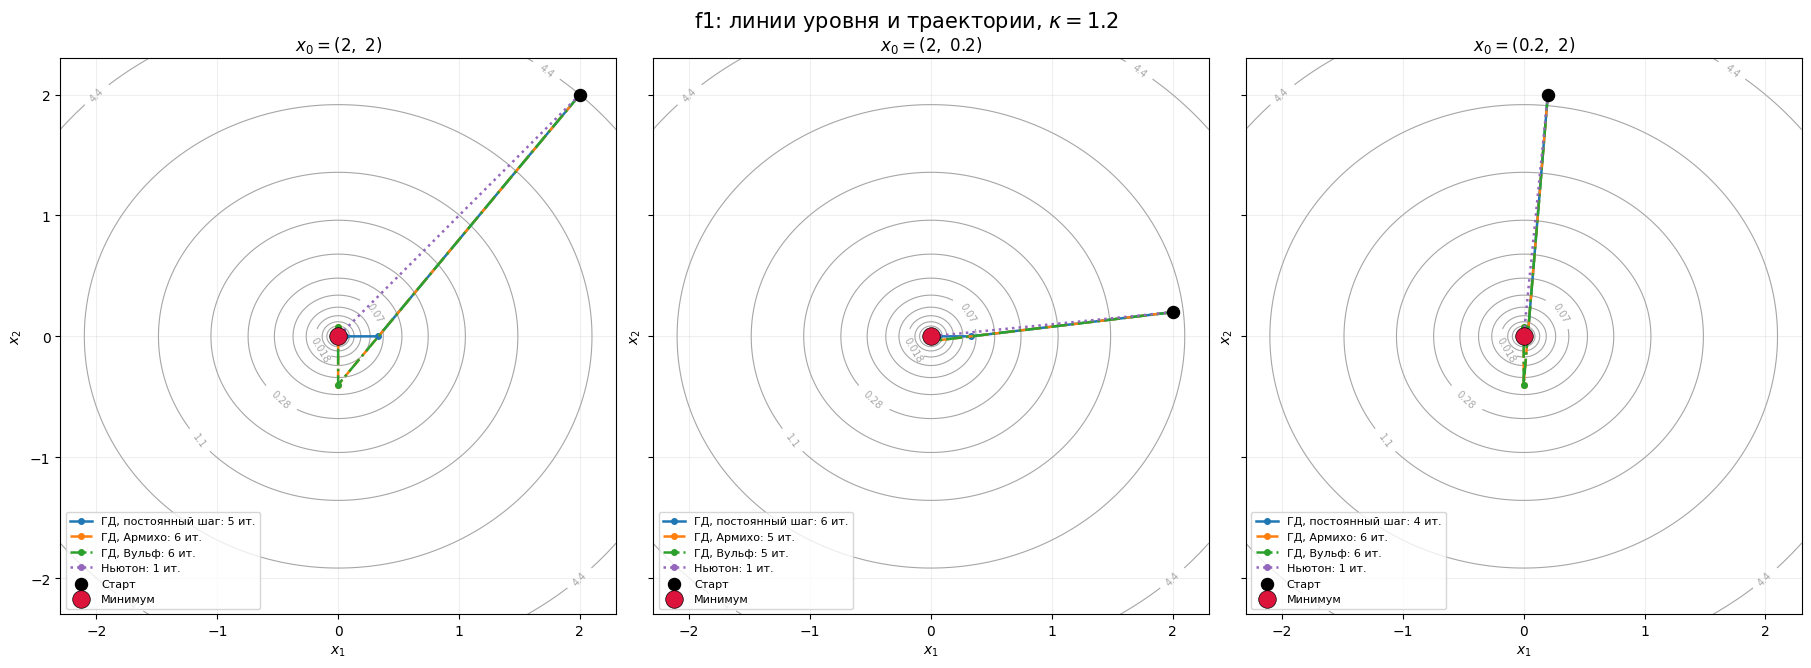

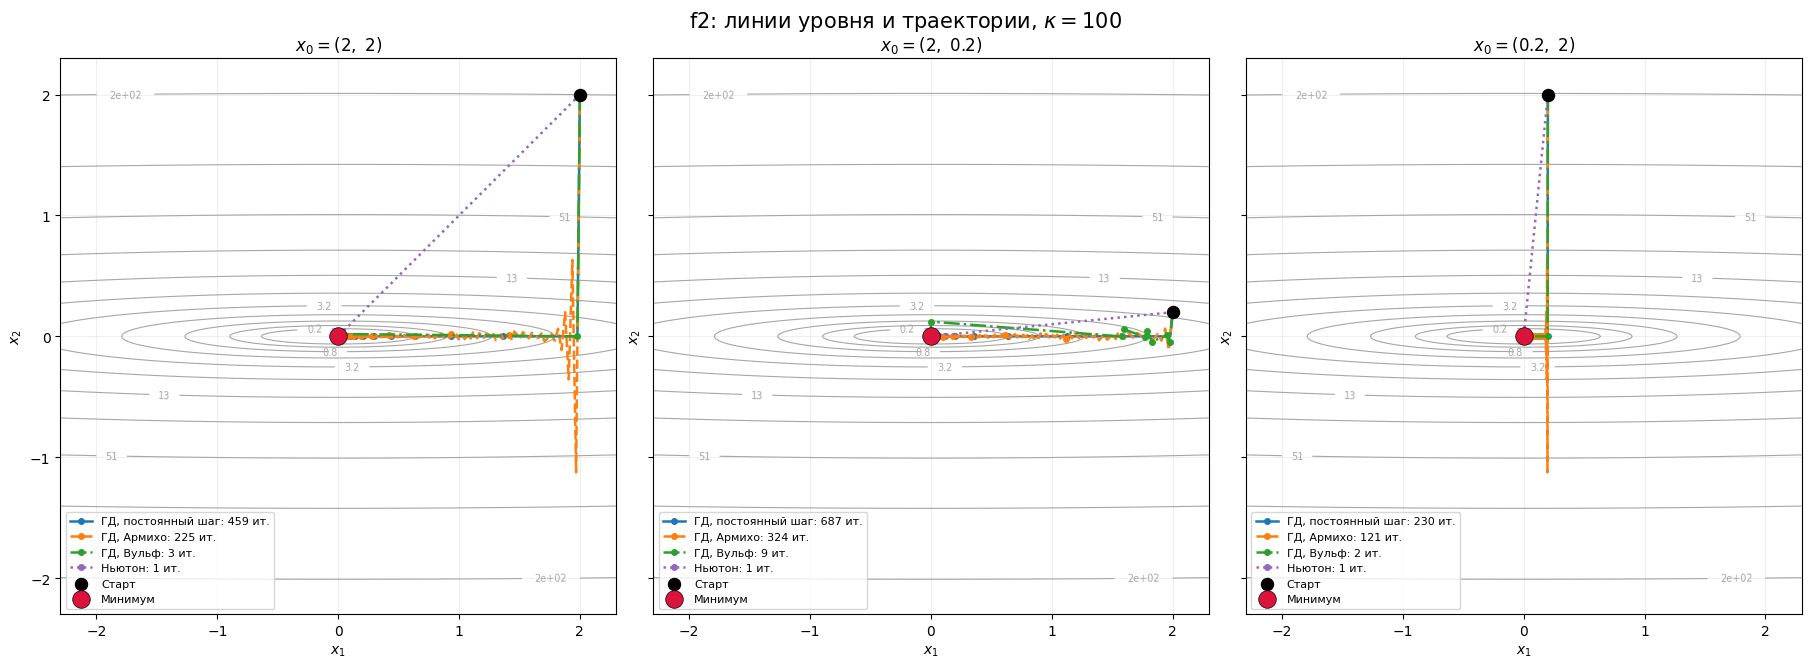

In [33]:
from pathlib import Path

exp1_output_dir = FIGURES_DIR
exp1_output_dir.mkdir(exist_ok=True)
exp1_styles = {
    'GD Constant': {'color': 'tab:blue', 'linestyle': '-', 'marker': 'o'},
    'GD Armijo': {'color': 'tab:orange', 'linestyle': '--', 'marker': 'o'},
    'GD Wolfe': {'color': 'tab:green', 'linestyle': '-.', 'marker': 'o'},
    'Newton': {'color': 'tab:purple', 'linestyle': ':', 'marker': 'o'},
}

exp1_radius = 1.15 * max(
    np.max(np.abs(result['history']['x']))
    for result in exp1_results.values()
)
exp1_axis = np.linspace(-exp1_radius, exp1_radius, 401)
exp1_grid_x, exp1_grid_y = np.meshgrid(exp1_axis, exp1_axis)
exp1_grid = np.stack((exp1_grid_x, exp1_grid_y), axis=-1)
exp1_figures = {}

for function_name, oracle in exp1_oracles.items():
    
    values = (
        0.5 * np.einsum('...i,ij,...j->...', exp1_grid, oracle.A, exp1_grid)
        - exp1_grid @ oracle.b
    )
    x_star = np.linalg.solve(oracle.A, oracle.b)
    f_star = oracle.func(x_star)
    max_start_gap = max(oracle.func(x_0) - f_star for x_0 in exp1_starts)

    levels = f_star + np.geomspace(max_start_gap * 1e-3, max_start_gap, 11)
    condition_number = np.linalg.cond(oracle.A)
    fig, axes = plt.subplots(
        1, len(exp1_starts), figsize=(18, 6.5), squeeze=False,
        sharex=True, sharey=True, constrained_layout=True,
    )
    fig.suptitle(
        f'{function_name}: линии уровня и траектории, '
        rf'$\kappa = {condition_number:g}$', fontsize=15,
    )

    for ax, x_0 in zip(axes[0], exp1_starts):
        contours = ax.contour(
            exp1_grid_x, exp1_grid_y, values, levels=levels,
            colors='0.65', linewidths=0.8, zorder=1,
        )
        ax.clabel(contours, levels=levels[::2], inline=True, fontsize=7, fmt='%.2g')
        for method_name, style in exp1_styles.items():
            result = exp1_results[(function_name, tuple(x_0), method_name)]
            trajectory = np.asarray(result['history']['x'])
            
            label = f"{method_name}: {result['iterations']} ит."
            if result['message'] != 'success':
                label += f" ({result['message']})"
            ax.plot(
                trajectory[:, 0], trajectory[:, 1], **style,
                linewidth=1.8, markersize=4, markerfacecolor='auto',
                markevery=max(1, len(trajectory) // 12),
                label=label, zorder=3,
            )
        ax.scatter(*x_0, color='black', marker='o', s=75, label='Старт', zorder=5)
        ax.scatter(*x_star, color='crimson', marker='o', s=160,
                   edgecolors='black', linewidths=0.5, label='Минимум', zorder=6)
        ax.set_title(rf'$x_0 = ({x_0[0]:g},\ {x_0[1]:g})$')
        ax.set_xlabel(r'$x_1$')
        ax.set_ylabel(r'$x_2$')
        ax.set_xlim(-exp1_radius, exp1_radius)
        ax.set_ylim(-exp1_radius, exp1_radius)
        ax.set_aspect('equal', adjustable='box')
        ax.grid(alpha=0.2)
        ax.legend(loc='lower left', fontsize=8)

    exp1_figures[function_name] = fig
    experiment_prepare_figure(fig)
    fig.savefig(exp1_output_dir / f'exp1_quadratic_{function_name}.png', dpi=180)
    plt.show()
    plt.close(fig)


Эксперимент 1, часть 1: Ваш ответ

В эксперименте рассмотрены две двумерные квадратичные функции вида

$f(x) = \frac12\langle Ax, x\rangle - \langle b, x\rangle$

**1. Хорошо обусловленная функция**
$$
f_1(x_1,x_2)=\frac12(x_1^2+1.2x_2^2),
\qquad
A_1=\begin{pmatrix}
1&0\\
0&1.2
\end{pmatrix},
\qquad
b=\begin{pmatrix}0\\0\end{pmatrix}.
$$

Её гессиан постоянен: $\nabla^2 f_1=A_1$.
Собственные значения равны $1$ и $1.2$, поэтому
$$
\kappa_1=\frac{\lambda_{\max}(A_1)}
{\lambda_{\min}(A_1)}
=\frac{1.2}{1}=1.2.
$$

Число обусловленности близко к единице. Кривизна по обоим
координатным направлениям сопоставима. Линии уровня — эллипсы,
близкие к окружностям.

**2. Плохо обусловленная функция**
$$
f_2(x_1,x_2)=\frac12(x_1^2+100x_2^2),
\qquad
A_2=\begin{pmatrix}
1&0\\
0&100
\end{pmatrix},
\qquad
b=\begin{pmatrix}0\\0\end{pmatrix}.
$$

Её гессиан равен $\nabla^2 f_2=A_2$.
Собственные значения равны $1$ и $100$, поэтому
$$
\kappa_2=\frac{\lambda_{\max}(A_2)}
{\lambda_{\min}(A_2)}
=\frac{100}{1}=100.
$$

Кривизна по направлению $x_2$ в 100 раз больше, чем
по направлению $x_1$. Линии уровня — сильно вытянутые
эллипсы.

Обе матрицы положительно определены, поэтому обе функции
строго выпуклы и имеют единственный глобальный минимум:
$$
x^*=\begin{pmatrix}0\\0\end{pmatrix},
\qquad f_1(x^*)=f_2(x^*)=0.
$$

**Параметры эксперимента.**

Использованы три начальные точки: $(2,2)$, $(2,0.2)$ и $(0.2,2)$.
Из каждой точки запущены GD с постоянным шагом $\alpha=1/L$, GD с Армихо,
GD с сильными условиями Вульфа и Ньютон с постоянным шагом $\alpha=1$.
Здесь $L=\lambda_{\max}(A)$, поэтому постоянный шаг GD равен $1/1.2$ для $f_1$
и $0.01$ для $f_2$.

Для Армихо заданы $c_1=10^{-4}$ и первый пробный шаг $1$; на следующих
итерациях GD поиск начинается с удвоенного предыдущего принятого шага.
Для Вульфа используются $c_1=10^{-4}$, $c_2=0.9$.
Лимит — $10000$ итераций, критерий остановки:
$$
\frac{\|\nabla f(x_k)\|_2^2}{\|\nabla f(x_0)\|_2^2}\leq 10^{-8}.
$$
Вычисления выполнены в `float64`. Среда запуска —
Google Colab: CPU `x86_64`, 2 логических процессора, около $12.7$ ГиБ RAM,
NumPy 2.4.6 и SciPy 1.16.3. В ноутбуке установлен `SEED = 42`;
основные квадратичные задачи заданы явно, без случайной генерации.

**Результаты.**

Все запуски завершились успешно. Число итераций указано в таблице.

| Функция | Начальная точка | GD, $1/L$ | GD, Армихо | GD, Вульф | Ньютон, $\alpha=1$ |
|---|---|---:|---:|---:|---:|
| $f_1$, $\kappa=1.2$ | $(2,2)$ | 5 | 6 | 6 | 1 |
| $f_1$, $\kappa=1.2$ | $(2,0.2)$ | 6 | 5 | 5 | 1 |
| $f_1$, $\kappa=1.2$ | $(0.2,2)$ | 4 | 6 | 6 | 1 |
| $f_2$, $\kappa=100$ | $(2,2)$ | 459 | 225 | 3 | 1 |
| $f_2$, $\kappa=100$ | $(2,0.2)$ | 687 | 324 | 9 | 1 |
| $f_2$, $\kappa=100$ | $(0.2,2)$ | 230 | 121 | 2 | 1 |

**1. Влияние обусловленности, старта и стратегии шага**

На графике $f_1$ линии уровня близки к окружностям. Все три варианта спуска
достигают заданной точности за 4–6 итераций, поэтому заметного преимущества
одной стратегии здесь нет. На графике $f_2$ видны вытянутые эллипсы;
Армихо даёт колебания поперёк оврага, а движение вдоль пологого направления
требует большого числа итераций.

Разную скорость сходимости по направлениям можно объяснить собственными значениями гессиана. Для ошибки $e_k=x_k-x^*$
и постоянного шага
$$
e_{k+1}=(I-\alpha A)e_k.
$$
В собственном направлении с собственным значением $\lambda_j$ ошибка умножается на
$1-\alpha\lambda_j$. Шаг ограничен большой кривизной, а в пологом направлении
ошибка уменьшается медленно. Например, для $f_2$ при $\alpha=0.01$
компонента по $x_2$ обнуляется первым шагом, а компонента по $x_1$
на каждой итерации умножается на $0.99$.

От начальной точки зависят составляющие ошибки по собственным направлениям.
Начальная норма градиента в относительном критерии тоже меняется:
одинаковый порог относительного уменьшения не означает одинаковой абсолютной
точности координат. Это объясняет разное число итераций из разных стартов.

На $f_2$ Армихо требует примерно вдвое меньше итераций, чем выбранный постоянный шаг.
Вульф в этих примерах достигает критерия за 2–9 итераций. Малое число итераций связано
с конкретным спектром матрицы и последовательностью найденных шагов. Такой результат
не гарантирован для произвольной плохо обусловленной функции.

**2. Ньютон на квадратичной функции**

Гессиан равен постоянной положительно определённой матрице $A$.
Квадратичная модель Ньютона здесь совпадает с самой функцией, поэтому
$$
x_{k+1}=x_k-A^{-1}(Ax_k-b)=A^{-1}b=x^*.
$$
Без учёта ошибок округления для этих квадратичных функций
достаточно не более одного полного шага ($\alpha=1$) из любой начальной точки.
В эксперименте это подтверждается для обеих функций: на каждом графике
траектория Ньютона состоит из одного перехода к минимуму. В реализации
система решается с помощью разложения Холецкого; явная обратная матрица не вычисляется.

Дополнительный рисунок с поворотом матрицы на $23$ градуса и минимумом
$(-0.75,1.25)$ показывает, что эта разница между методами сохраняется, когда собственные
направления не совпадают с координатными осями. Поворот сохраняет собственные значения
и число обусловленности. Метод Ньютона по-прежнему делает один шаг, а у GD
на плохо обусловленной задаче остаётся медленное движение вдоль оврага.

Критическая точка [1. 1.], f = 0, собственные значения = [3.99360767e-01 1.00160064e+03], тип: строгий минимум
У Розенброка нет других критических точек, седел или локальных максимумов.


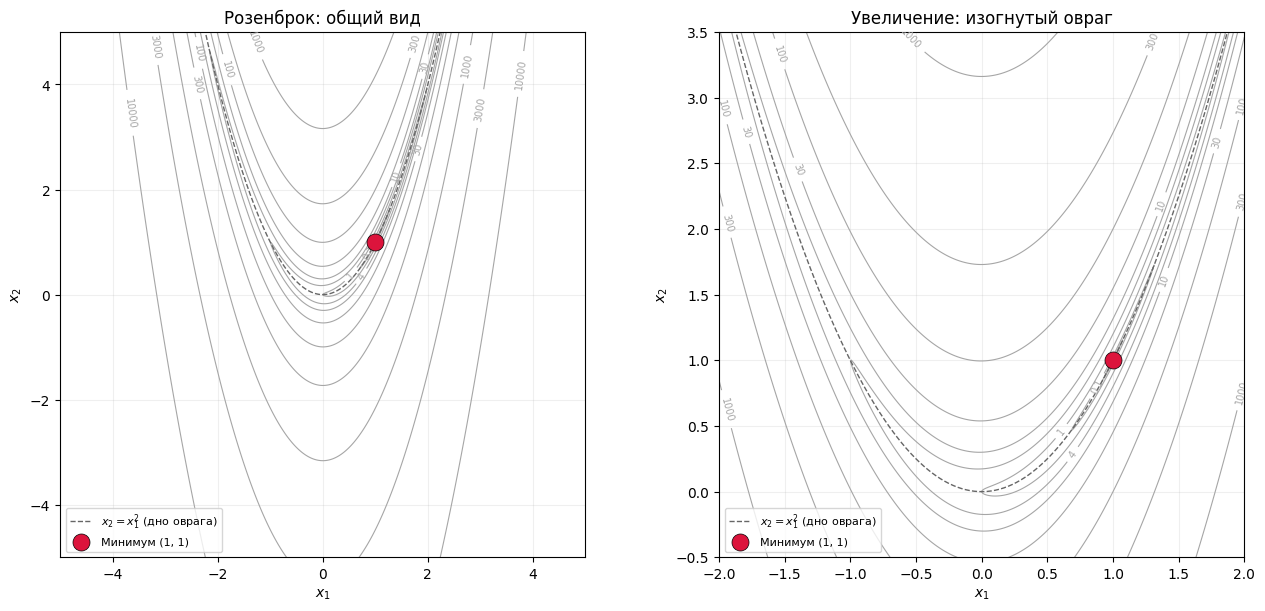

In [34]:
from pathlib import Path

exp1_rosen_oracle = RosenbrockOracle()
exp1_rosen_output_dir = FIGURES_DIR
exp1_rosen_output_dir.mkdir(exist_ok=True)
exp1_rosen_minimum = np.array([1.0, 1.0])
exp1_rosen_critical_points = [exp1_rosen_minimum.copy()]
for point in exp1_rosen_critical_points:
    spectrum = np.linalg.eigvalsh(exp1_rosen_oracle.hess(point))
    point_type = (
        'строгий минимум' if np.all(spectrum > 0)
        else 'строгий максимум' if np.all(spectrum < 0)
        else 'седловая точка' if spectrum[0] < 0 < spectrum[-1]
        else 'нужен дополнительный анализ'
    )
    print(f'Критическая точка {point}, f = {exp1_rosen_oracle.func(point):g}, '
          f'собственные значения = {spectrum}, тип: {point_type}')
print('У Розенброка нет других критических точек, седел или локальных максимумов.')


def exp1_rosen_contours(ax, x_limits, y_limits):
    """Линии уровня Розенброка на векторизованной сетке."""
    grid_x, grid_y = np.meshgrid(
        np.linspace(*x_limits, 501), np.linspace(*y_limits, 501),
    )
    values = (1 - grid_x) ** 2 + 100 * (grid_y - grid_x ** 2) ** 2
    levels = [0.01, 0.1, 1, 4, 10, 30, 100, 300, 1000, 3000, 10000, 100000]
    contours = ax.contour(grid_x, grid_y, values, levels=levels,
                          colors='0.65', linewidths=0.8)
    ax.clabel(contours, inline=True, fontsize=7, fmt='%g')
    valley_x = np.linspace(*x_limits, 501)
    ax.plot(valley_x, valley_x ** 2, '--', color='0.4', linewidth=1,
            label=r'$x_2 = x_1^2$ (дно оврага)')
    ax.scatter(*exp1_rosen_minimum, marker='o', s=150, color='crimson',
               edgecolors='black', linewidths=0.5, label='Минимум (1, 1)', zorder=6)
    ax.set(xlim=x_limits, ylim=y_limits, xlabel=r'$x_1$', ylabel=r'$x_2$')
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.2)


exp1_rosen_geometry_fig, axes = plt.subplots(
    1, 2, figsize=(13, 6), constrained_layout=True,
)
for ax, limits, title in zip(
    axes,
    [((-5, 5), (-5, 5)), ((-2, 2), (-0.5, 3.5))],
    ['Розенброк: общий вид', 'Увеличение: изогнутый овраг'],
):
    exp1_rosen_contours(ax, *limits)
    ax.set_title(title)
    ax.legend(loc='lower left', fontsize=8)
experiment_prepare_figure(exp1_rosen_geometry_fig)
exp1_rosen_geometry_fig.savefig(
    exp1_rosen_output_dir / 'exp1_rosenbrock_levels.png', dpi=180,
)
plt.show()
plt.close(exp1_rosen_geometry_fig)


Армихо: {'method': 'Armijo', 'c1': 0.0001, 'alpha_0': 1.0}, max_iter = 10000, целевая норма градиента <= 0.001

На дне оврага: x_0 = [-1.5   2.25], спектр гессиана = [1.99820144e-01 2.00180018e+03]
GD Armijo       success                  итерации =  7960, f = 1.548e-07, ||grad|| = 4.930e-04, ||x - x*|| = 8.803e-04
Newton Armijo   success                  итерации =    21, f = 3.144e-16, ||grad|| = 5.837e-07, ||x - x*|| = 2.690e-08

Рядом с дном оврага: x_0 = [-1.2  1. ], спектр гессиана = [  23.63301935 1506.36698065]
GD Armijo       success                  итерации =  6586, f = 6.209e-07, ||grad|| = 9.858e-04, ||x - x*|| = 1.762e-03
Newton Armijo   success                  итерации =    20, f = 8.517e-12, ||grad|| = 1.187e-04, ||x - x*|| = 2.727e-06

На крутом склоне: x_0 = [ 1.5 -1. ], спектр гессиана = [  80.84045397 3221.15954603]
GD Armijo       success                  итерации =  6412, f = 6.029e-07, ||grad|| = 9.922e-04, ||x - x*|| = 1.737e-03
Newton Armijo   success         

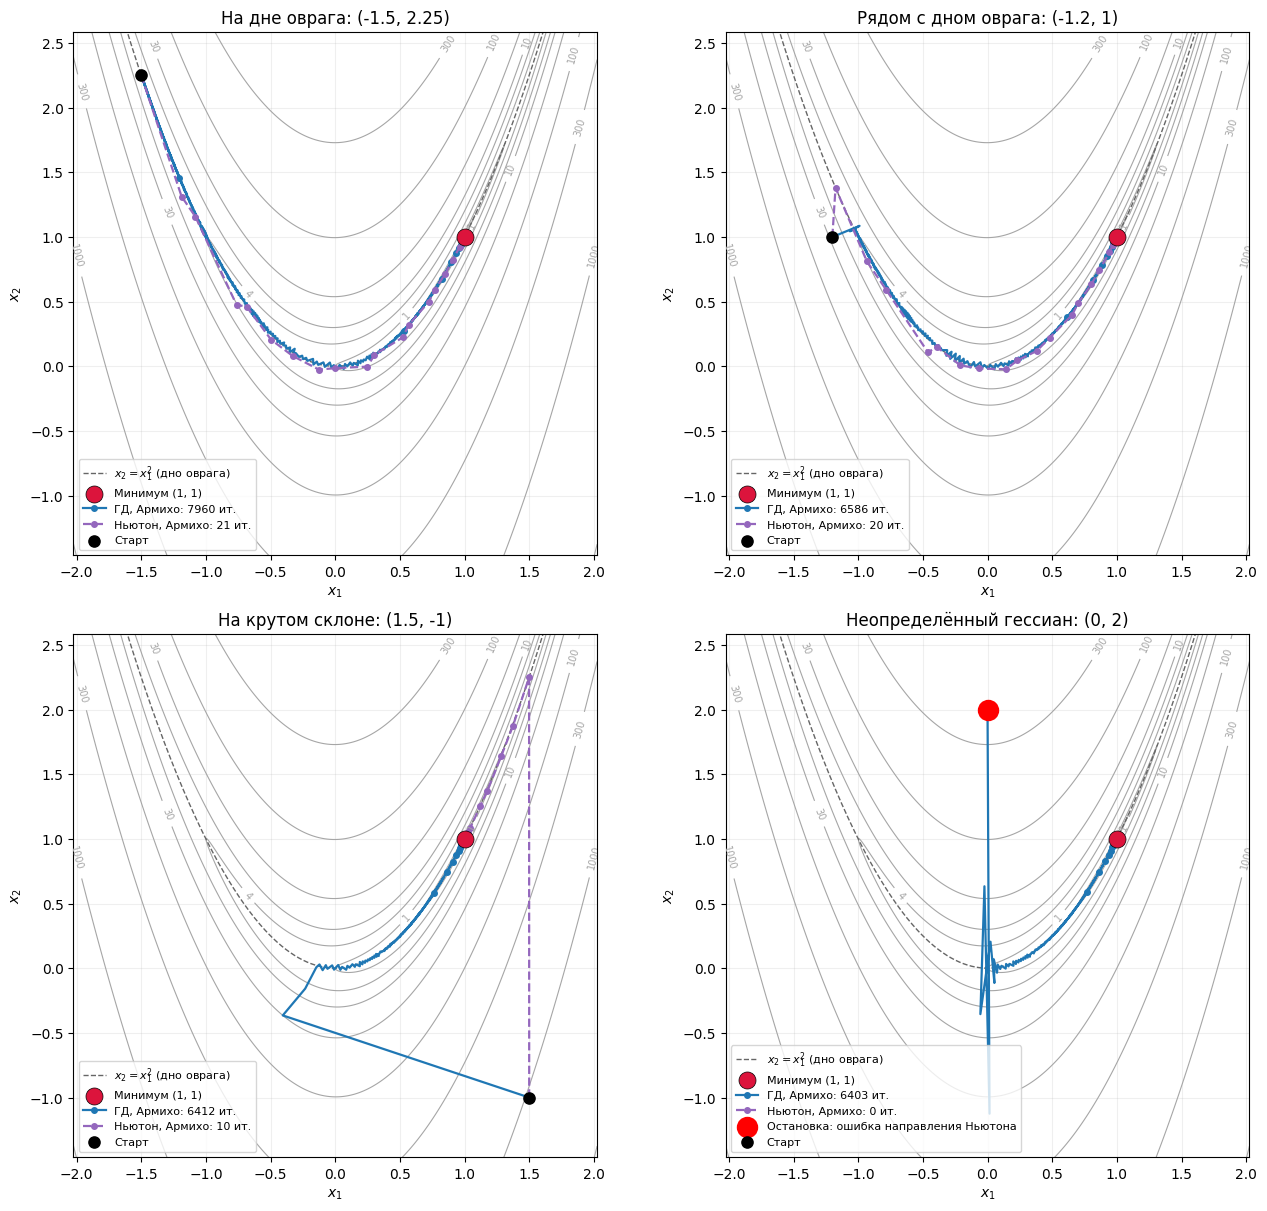

In [35]:
exp1_rosen_starts = {
    'На дне оврага': np.array([-1.5, 2.25]),
    'Рядом с дном оврага': np.array([-1.2, 1.0]),
    'На крутом склоне': np.array([1.5, -1.0]),
    'Неопределённый гессиан': np.array([0.0, 2.0]),
}
exp1_rosen_methods = {'GD Armijo': gradient_descent, 'Newton Armijo': newton}
exp1_rosen_options = {'method': 'Armijo', 'c1': 1e-4, 'alpha_0': 1.0}
exp1_rosen_relative_tolerance = 1e-8
exp1_rosen_grad_target = 1e-3
exp1_rosen_distance_target = 1e-2
exp1_rosen_max_iter = 10000


def exp1_rosen_tolerance(x_0):
    initial_grad_sq = float(np.dot(
        exp1_rosen_oracle.grad(x_0), exp1_rosen_oracle.grad(x_0),
    ))
    if initial_grad_sq == 0:
        return exp1_rosen_relative_tolerance
    return min(exp1_rosen_relative_tolerance,
               exp1_rosen_grad_target ** 2 / initial_grad_sq)


exp1_rosen_results = {}
print(f'Армихо: {exp1_rosen_options}, max_iter = {exp1_rosen_max_iter}, '
      f'целевая норма градиента <= {exp1_rosen_grad_target:g}')
for start_name, x_0 in exp1_rosen_starts.items():
    initial_spectrum = np.linalg.eigvalsh(exp1_rosen_oracle.hess(x_0))
    print(f'\n{start_name}: x_0 = {x_0}, спектр гессиана = {initial_spectrum}')
    for method_name, optimizer in exp1_rosen_methods.items():
        run = experiment_run(
            'exp1_rosenbrock', exp1_rosen_oracle, x_0, optimizer,
            problem={'function': 'Rosenbrock', 'start_name': start_name},
            tolerance=exp1_rosen_tolerance(x_0), max_iter=exp1_rosen_max_iter,
            line_search_options=exp1_rosen_options,
        )
        x_opt, message, history = run['x_opt'], run['message'], run['history']
        iterations = len(history['func']) - 1
        exp1_rosen_results[(start_name, method_name)] = {
            'x_opt': x_opt, 'message': message, 'history': history,
            'iterations': iterations,
        }
        print(f'{method_name:<15} {message:<24} итерации = {iterations:5d}, '
              f'f = {history["func"][-1]:.3e}, '
              f'||grad|| = {history["grad_norm"][-1]:.3e}, '
              f'||x - x*|| = {np.linalg.norm(x_opt - exp1_rosen_minimum):.3e}')

exp1_rosen_trajectory_fig, axes = plt.subplots(
    2, 2, figsize=(13, 12), constrained_layout=True,
)
exp1_rosen_styles = {
    'GD Armijo': {'color': 'tab:blue', 'marker': 'o', 'linestyle': '-'},
    'Newton Armijo': {'color': 'tab:purple', 'marker': 'o', 'linestyle': '--'},
}
all_points = np.vstack([
    np.asarray(result['history']['x']) for result in exp1_rosen_results.values()
] + [exp1_rosen_minimum[None, :]])
lower, upper = all_points.min(axis=0), all_points.max(axis=0)
span = max(np.max(upper - lower), 1.0)
center = 0.5 * (lower + upper)
limits = [(c - 0.6 * span, c + 0.6 * span) for c in center]
for ax, (start_name, x_0) in zip(axes.flat, exp1_rosen_starts.items()):
    exp1_rosen_contours(ax, *limits)
    for method_name, style in exp1_rosen_styles.items():
        result = exp1_rosen_results[(start_name, method_name)]
        trajectory = np.asarray(result['history']['x'])
        label = f"{method_name}: {result['iterations']} ит."
        ax.plot(trajectory[:, 0], trajectory[:, 1], **style,
                linewidth=1.6, markersize=4, markerfacecolor='auto',
                markevery=max(1, len(trajectory) // 20), label=label, zorder=3)
        if result['message'] != 'success':
            ax.scatter(*result['x_opt'], marker='o', s=180, linewidths=2,
                       color='red', zorder=7,
                       label=f"Остановка: {result['message']}")
    ax.scatter(*x_0, marker='o', color='black', s=65, label='Старт', zorder=5)
    ax.set_title(f'{start_name}: ({x_0[0]:g}, {x_0[1]:g})')
    ax.legend(loc='lower left', fontsize=8)
experiment_prepare_figure(exp1_rosen_trajectory_fig)
exp1_rosen_trajectory_fig.savefig(
    exp1_rosen_output_dir / 'exp1_rosenbrock_trajectories.png', dpi=180,
)
plt.show()
plt.close(exp1_rosen_trajectory_fig)

experiment_save_table('exp1_rosenbrock_runs.csv', [
    {'start': start_name, 'method': method_name, 'status': result['message'],
     'iterations': result['iterations'], 'final_func': float(result['history']['func'][-1]),
     'final_grad_norm': float(result['history']['grad_norm'][-1]),
     'distance_to_minimum': float(np.linalg.norm(result['x_opt'] - exp1_rosen_minimum))}
    for (start_name, method_name), result in exp1_rosen_results.items()
])


In [36]:
from collections import Counter
import hashlib
import json

def exp1_rosen_batch_func(points):
    """Значения Розенброка сразу для нескольких независимых точек."""
    x, y = points[:, 0], points[:, 1]
    return (1 - x) ** 2 + 100 * (y - x ** 2) ** 2


def exp1_rosen_batch_grad(points):
    x, y = points[:, 0], points[:, 1]
    residual = y - x ** 2
    return np.column_stack((
        2 * (x - 1) - 400 * x * residual,
        200 * residual,
    ))


def exp1_rosen_batch_solve(starts, optimizer):
    """Те же ГД/Ньютон и Армихо; независимые старты обрабатываются массивами.

    Ньютоновские системы решаются исходным разложением Холецкого SciPy.
    Истории здесь не нужны: для карты сохраняются конечные точки и статусы.
    """
    points = np.array(starts, dtype=float, copy=True)
    messages = np.full(len(points), 'iterations_exceeded', dtype='<U32')
    options = exp1_rosen_options
    if (type(exp1_rosen_oracle) is not RosenbrockOracle
            or optimizer not in (gradient_descent, newton)
            or options.get('method', 'Wolfe') != 'Armijo'):
        for i, point in enumerate(points.copy()):
            points[i], messages[i], _ = optimizer(
                exp1_rosen_oracle, point,
                tolerance=exp1_rosen_tolerance(point),
                max_iter=exp1_rosen_max_iter,
                line_search_options=options, trace=False, display=False,
            )
        return points, messages

    is_newton = optimizer is newton
    c1 = options.get('c1', 1e-4)
    initial_alpha = 1.0 if is_newton else options.get('alpha_0', 1.0)
    previous_alpha = np.full(len(points), initial_alpha, dtype=float)
    active = np.ones(len(points), dtype=bool)
    with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
        g0 = exp1_rosen_batch_grad(points)
        g0_dot = np.sum(g0 * g0, axis=1)
        tolerances = np.full(len(points), exp1_rosen_relative_tolerance)
        nonzero = g0_dot != 0
        tolerances[nonzero] = np.minimum(
            tolerances[nonzero], exp1_rosen_grad_target ** 2 / g0_dot[nonzero],
        )
        thresholds = tolerances * np.linalg.norm(g0, axis=1) ** 2
        for iteration in range(exp1_rosen_max_iter + 1):
            idx = np.flatnonzero(active)
            if not len(idx):
                break
            current = points[idx]
            values = exp1_rosen_batch_func(current)
            gradients = exp1_rosen_batch_grad(current)
            norm_sq = np.linalg.norm(gradients, axis=1) ** 2
            finite = (np.all(np.isfinite(current), axis=1)
                      & np.isfinite(values)
                      & np.all(np.isfinite(gradients), axis=1)
                      & np.isfinite(norm_sq))
            failed = idx[~finite]
            messages[failed] = 'computational_error'
            active[failed] = False
            done = finite & (norm_sq <= thresholds[idx])
            messages[idx[done]] = 'success'
            active[idx[done]] = False
            if iteration == exp1_rosen_max_iter:
                break
            advance = finite & ~done
            idx = idx[advance]
            if not len(idx):
                continue
            current = current[advance]
            values = values[advance]
            gradients = gradients[advance]
            directions = -gradients.copy()

            if is_newton:
                x, y = current[:, 0], current[:, 1]
                hessians = np.empty((len(idx), 2, 2))
                hessians[:, 0, 0] = 2 - 400 * y + 1200 * x ** 2
                hessians[:, 0, 1] = hessians[:, 1, 0] = -400 * x
                hessians[:, 1, 1] = 200
                valid_direction = np.ones(len(idx), dtype=bool)
                for j, hessian in enumerate(hessians):
                    if not np.all(np.isfinite(hessian)):
                        messages[idx[j]] = 'computational_error'
                        valid_direction[j] = False
                        continue
                    try:
                        factor = scipy.linalg.cho_factor(
                            hessian, lower=True, check_finite=False,
                        )
                        directions[j] = scipy.linalg.cho_solve(
                            factor, -gradients[j], check_finite=False,
                        )
                    except LinAlgError:
                        messages[idx[j]] = 'newton_direction_error'
                        valid_direction[j] = False
                active[idx[~valid_direction]] = False
                idx = idx[valid_direction]
                current = current[valid_direction]
                values = values[valid_direction]
                gradients = gradients[valid_direction]
                directions = directions[valid_direction]

            slopes = np.sum(gradients * directions, axis=1)
            valid = (np.all(np.isfinite(directions), axis=1)
                     & np.isfinite(slopes) & (slopes < 0))
            messages[idx[~valid]] = 'computational_error'
            active[idx[~valid]] = False
            idx = idx[valid]
            current, values = current[valid], values[valid]
            directions, slopes = directions[valid], slopes[valid]
            if not len(idx):
                continue
            alpha = np.ones(len(idx)) if is_newton else previous_alpha[idx].copy()
            valid_alpha = np.isfinite(alpha) & (alpha > 0)
            messages[idx[~valid_alpha]] = 'computational_error'
            active[idx[~valid_alpha]] = False
            pending = valid_alpha.copy()
            accepted = np.zeros(len(idx), dtype=bool)
            for _ in range(1000):
                retry = np.flatnonzero(pending)
                if not len(retry):
                    break
                trial = current[retry] + alpha[retry, None] * directions[retry]
                stagnant = np.all(trial == current[retry], axis=1)
                pending[retry[stagnant]] = False
                retry, trial = retry[~stagnant], trial[~stagnant]
                trial_values = exp1_rosen_batch_func(trial)
                ok = (np.isfinite(trial_values)
                      & (trial_values <= values[retry] + c1 * alpha[retry] * slopes[retry]))
                accepted[retry[ok]] = True
                pending[retry[ok]] = False
                alpha[retry[~ok]] *= 0.5
                pending &= np.isfinite(alpha) & (alpha > 0)
            failed = ~accepted
            messages[idx[failed]] = 'computational_error'
            active[idx[failed]] = False
            update = np.flatnonzero(accepted)
            trial = current[update] + alpha[update, None] * directions[update]
            finite_trial = np.all(np.isfinite(trial), axis=1)
            failed_idx = idx[update[~finite_trial]]
            messages[failed_idx] = 'computational_error'
            active[failed_idx] = False
            update, trial = update[finite_trial], trial[finite_trial]
            points[idx[update]] = trial
            previous_alpha[idx[update]] = 2.0 * alpha[update]
    return points, messages


exp1_rosen_grid_size = 200
exp1_rosen_batch_rows = 16
exp1_rosen_basin_axis = np.linspace(-5.0, 5.0, exp1_rosen_grid_size)
exp1_rosen_checkpoint_dir = exp1_rosen_output_dir / 'checkpoints'
exp1_rosen_checkpoint_dir.mkdir(parents=True, exist_ok=True)
exp1_rosen_basin_config = {
    'experiment_version': 1,
    'function': '(1-x1)^2 + 100*(x2-x1^2)^2',
    'grid_size': exp1_rosen_grid_size, 'bounds': [-5.0, 5.0],
    'max_iter': exp1_rosen_max_iter,
    'relative_tolerance': exp1_rosen_relative_tolerance,
    'grad_target': exp1_rosen_grad_target,
    'distance_target': exp1_rosen_distance_target,
    'line_search': exp1_rosen_options,
    'methods': list(exp1_rosen_methods),
    'numpy_version': np.__version__, 'scipy_version': scipy.__version__,
}
exp1_rosen_config_json = json.dumps(exp1_rosen_basin_config, sort_keys=True)
exp1_rosen_signature = hashlib.sha256(exp1_rosen_config_json.encode()).hexdigest()[:12]
exp1_rosen_array_fields = [
    'labels', 'messages', 'optimizer_messages', 'endpoints',
    'func_values', 'grad_norms', 'distances',
]


def exp1_rosen_save_checkpoint(path, result):
    temporary = path.with_suffix('.tmp')
    with temporary.open('wb') as stream:
        np.savez_compressed(
            stream, config_json=exp1_rosen_config_json,
            done_rows=result['done_rows'], elapsed=result['elapsed'],
            **{field: result[field] for field in exp1_rosen_array_fields},
        )
    temporary.replace(path)


exp1_rosen_basins = {}
print(f'Сетка {exp1_rosen_grid_size} x {exp1_rosen_grid_size}, квадрат [-5, 5]^2, '
      f'max_iter = {exp1_rosen_max_iter}.')
print(f'Относительная точность: {exp1_rosen_relative_tolerance:g}; '
      f'||grad|| <= {exp1_rosen_grad_target:g}; '
      f'||x - (1, 1)|| <= {exp1_rosen_distance_target:g}.')
print('Чёрный: ошибка, лимит итераций или остановка вне окрестности минимума.')
print(f'Промежуточные результаты: {exp1_rosen_checkpoint_dir.resolve()}')
print(f'Пакетный расчёт: до {exp1_rosen_batch_rows} строк за раз; старые checkpoints совместимы.')
print('При остановке внутри пакета его несохранённые строки будут пересчитаны.')
for method_name, optimizer in exp1_rosen_methods.items():
    prefix = method_name.split()[0].lower()
    checkpoint = exp1_rosen_checkpoint_dir / (
        f'rosenbrock_{prefix}_{exp1_rosen_grid_size}_{exp1_rosen_signature}.npz'
    )
    shape = (exp1_rosen_grid_size, exp1_rosen_grid_size)
    if checkpoint.exists():
        with np.load(checkpoint, allow_pickle=False) as saved:
            if saved['config_json'].item() != exp1_rosen_config_json:
                raise ValueError(f'Параметры checkpoint не совпадают: {checkpoint}')
            result = {field: saved[field].copy() for field in exp1_rosen_array_fields}
            result.update(done_rows=int(saved['done_rows']), elapsed=float(saved['elapsed']))
        if result['labels'].shape != shape or not 0 <= result['done_rows'] <= shape[0]:
            raise ValueError(f'Некорректный размер checkpoint: {checkpoint}')
        print(f"{method_name}: загружено строк {result['done_rows']}/{shape[0]}", flush=True)
    else:
        result = {
            'labels': np.zeros(shape, dtype=np.uint8),
            'messages': np.full(shape, 'pending', dtype='<U32'),
            'optimizer_messages': np.full(shape, 'pending', dtype='<U32'),
            'endpoints': np.full((*shape, 2), np.nan),
            'func_values': np.full(shape, np.nan),
            'grad_norms': np.full(shape, np.nan),
            'distances': np.full(shape, np.nan),
            'done_rows': 0, 'elapsed': 0.0,
        }
    previous_elapsed = result['elapsed']
    started = time.perf_counter()
    try:
        for first_row in range(result['done_rows'], exp1_rosen_grid_size,
                               exp1_rosen_batch_rows):
            last_row = min(first_row + exp1_rosen_batch_rows, exp1_rosen_grid_size)
            X0, Y0 = np.meshgrid(exp1_rosen_basin_axis,
                                 exp1_rosen_basin_axis[first_row:last_row])
            starts = np.column_stack((X0.ravel(), Y0.ravel()))
            endpoints, optimizer_messages = exp1_rosen_batch_solve(starts, optimizer)
            with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
                if type(exp1_rosen_oracle) is RosenbrockOracle:
                    final_values = exp1_rosen_batch_func(endpoints)
                    grad_norms = np.linalg.norm(exp1_rosen_batch_grad(endpoints), axis=1)
                else:
                    final_values = np.array([exp1_rosen_oracle.func(p) for p in endpoints])
                    grad_norms = np.array([np.linalg.norm(exp1_rosen_oracle.grad(p))
                                           for p in endpoints])
                distances = np.linalg.norm(endpoints - exp1_rosen_minimum, axis=1)
                reached = ((optimizer_messages == 'success')
                           & np.all(np.isfinite(endpoints), axis=1)
                           & (distances <= exp1_rosen_distance_target)
                           & (grad_norms <= exp1_rosen_grad_target * (1 + 1e-9)))
            messages = np.where((optimizer_messages == 'success') & ~reached,
                                'success_outside_minimum', optimizer_messages)
            block_shape = (last_row - first_row, exp1_rosen_grid_size)
            block = {
                'labels': reached.astype(np.uint8).reshape(block_shape),
                'messages': messages.reshape(block_shape),
                'optimizer_messages': optimizer_messages.reshape(block_shape),
                'endpoints': endpoints.reshape(*block_shape, 2),
                'func_values': final_values.reshape(block_shape),
                'grad_norms': grad_norms.reshape(block_shape),
                'distances': distances.reshape(block_shape),
            }
            for offset, row in enumerate(range(first_row, last_row)):
                for field in exp1_rosen_array_fields:
                    result[field][row] = block[field][offset]
                result['done_rows'] = row + 1
                result['elapsed'] = previous_elapsed + time.perf_counter() - started
                exp1_rosen_save_checkpoint(checkpoint, result)
            print(f"{method_name}: сохранено строк {last_row}/{shape[0]}, "
                  f"накопленное время {result['elapsed']:.1f} с, "
                  f"этот запуск {time.perf_counter() - started:.1f} с", flush=True)
    except KeyboardInterrupt:
        print(f"Остановлено. При повторном запуске продолжим со строки "
              f"{result['done_rows'] + 1}; завершённые строки сохранены.")
        raise
    exp1_rosen_basins[method_name] = result
    print(f"{method_name}: {dict(Counter(result['messages'].ravel().tolist()))}, "
          f"время = {result['elapsed']:.1f} с")

exp1_rosen_basin_result_path = exp1_rosen_output_dir / (
    f'exp1_rosenbrock_basins_{exp1_rosen_grid_size}_{exp1_rosen_signature}.npz'
)
np.savez_compressed(
    exp1_rosen_basin_result_path,
    config_json=exp1_rosen_config_json,
    axis=exp1_rosen_basin_axis, minimum=exp1_rosen_minimum,
    **{f'{method_name.split()[0].lower()}_{field}': result[field]
       for method_name, result in exp1_rosen_basins.items()
       for field in [*exp1_rosen_array_fields, 'elapsed', 'done_rows']},
)
print(f'Результаты сохранены: {exp1_rosen_basin_result_path.resolve()}')

experiment_save_table('exp1_rosenbrock_basin_summary.csv', [
    {'method': name, 'grid_size': exp1_rosen_grid_size, 'starts': result['labels'].size,
     'reached_minimum': int(np.count_nonzero(result['labels'])),
     'success': int(np.count_nonzero(result['messages'] == 'success')),
     'iterations_exceeded': int(np.count_nonzero(result['messages'] == 'iterations_exceeded')),
     'newton_direction_error': int(np.count_nonzero(result['messages'] == 'newton_direction_error')),
     'computational_error': int(np.count_nonzero(result['messages'] == 'computational_error')),
     'seconds': result['elapsed'], 'max_iter': exp1_rosen_max_iter,
     'grad_target': exp1_rosen_grad_target, 'distance_target': exp1_rosen_distance_target}
    for name, result in exp1_rosen_basins.items()
])


Сетка 200 x 200, квадрат [-5, 5]^2, max_iter = 10000.
Относительная точность: 1e-08; ||grad|| <= 0.001; ||x - (1, 1)|| <= 0.01.
Чёрный: ошибка, лимит итераций или остановка вне окрестности минимума.
Промежуточные результаты: /content/figures/checkpoints
Пакетный расчёт: до 16 строк за раз; старые checkpoints совместимы.
При остановке внутри пакета его несохранённые строки будут пересчитаны.
GD Armijo: загружено строк 200/200
GD Armijo: {'success': 33146, 'iterations_exceeded': 6854}, время = 285.7 с
Newton Armijo: загружено строк 200/200
Newton Armijo: {'success': 34064, 'newton_direction_error': 5936}, время = 44.6 с
Результаты сохранены: /content/figures/exp1_rosenbrock_basins_200_0cf3ea304bfc.npz


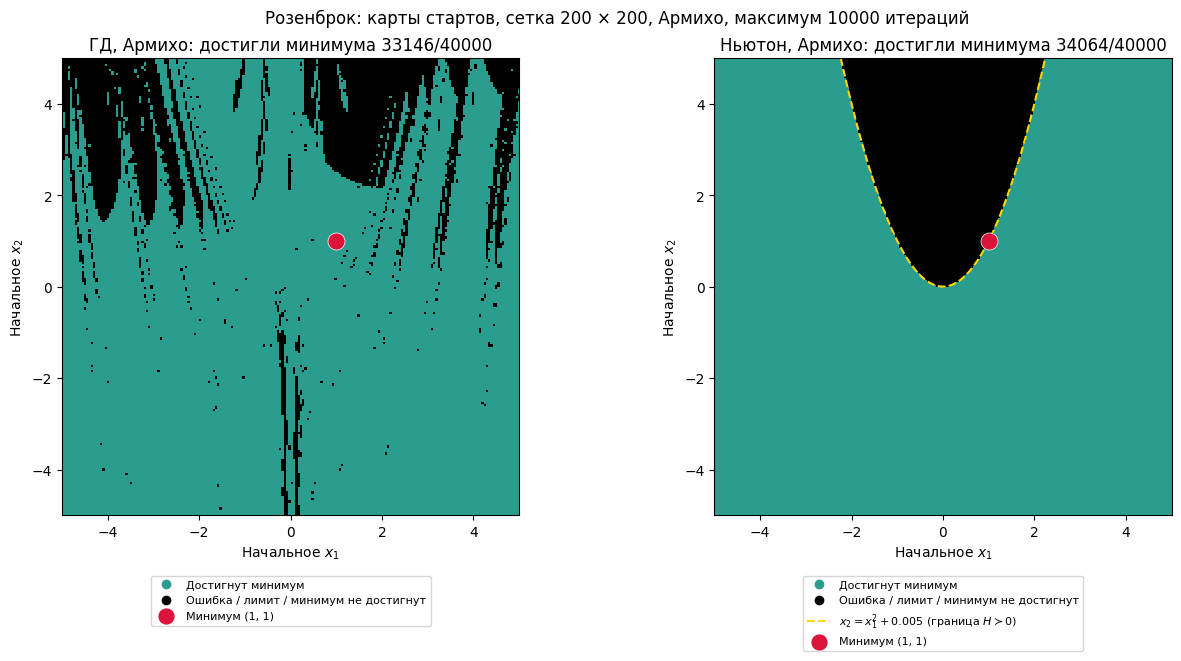

Серый цвет не используется: у этой функции нет седел и локальных максимумов.
Чёрный цвет показывает результат при заданных лимитах и реализации метода; он не доказывает невозможность сходимости при других настройках.
Карта Ньютона относится к реализации с Холецким и поиском шага Армихо.


In [37]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D

exp1_rosen_basin_fig, axes = plt.subplots(
    1, 2, figsize=(13, 6.5), constrained_layout=True,
)
colors = ListedColormap(['black', '#2a9d8f'])
norm = BoundaryNorm([-0.5, 0.5, 1.5], colors.N)
for ax, (method_name, result) in zip(axes, exp1_rosen_basins.items()):
    ax.pcolormesh(exp1_rosen_basin_axis, exp1_rosen_basin_axis,
                  result['labels'], shading='nearest', cmap=colors, norm=norm,
                  rasterized=True)
    if method_name.startswith('Newton'):
        boundary_x = np.linspace(-np.sqrt(5 - 0.005), np.sqrt(5 - 0.005), 501)
        ax.plot(boundary_x, boundary_x ** 2 + 0.005, '--', color='gold',
                linewidth=1.5, label=r'$x_2=x_1^2+0.005$ (граница $H\succ0$)')
    ax.scatter(*exp1_rosen_minimum, marker='o', s=150, color='crimson',
               edgecolors='white', linewidths=0.5, zorder=4, label='Минимум (1, 1)')
    succeeded = np.count_nonzero(result['labels'])
    total = result['labels'].size
    ax.set_title(f'{method_name}: достигли минимума {succeeded}/{total}')
    ax.set(xlim=(-5, 5), ylim=(-5, 5), xlabel=r'Начальное $x_1$',
           ylabel=r'Начальное $x_2$')
    ax.set_aspect('equal', adjustable='box')
    handles, _ = ax.get_legend_handles_labels()
    ax.legend(handles=[
        Line2D([], [], marker='o', linestyle='None', color='#2a9d8f', label='Достигнут минимум'),
        Line2D([], [], marker='o', linestyle='None', color='black', label='Ошибка / лимит / минимум не достигнут'),
        *handles,
    ], loc='upper center', bbox_to_anchor=(0.5, -0.12), fontsize=8)
exp1_rosen_basin_fig.suptitle(
    f'Розенброк: карты стартов, сетка {exp1_rosen_grid_size} × {exp1_rosen_grid_size}, '
    f'Армихо, максимум {exp1_rosen_max_iter} итераций', fontsize=12,
)
experiment_prepare_figure(exp1_rosen_basin_fig)
exp1_rosen_basin_fig.savefig(
    exp1_rosen_output_dir / 'exp1_rosenbrock_basins.png', dpi=180,
)
plt.show()
plt.close(exp1_rosen_basin_fig)
print('Серый цвет не используется: у этой функции нет седел и локальных максимумов.')
print('Чёрный цвет показывает результат при заданных лимитах и реализации метода; '
      'он не доказывает невозможность сходимости при других настройках.')
print('Карта Ньютона относится к реализации с Холецким и поиском шага Армихо.')


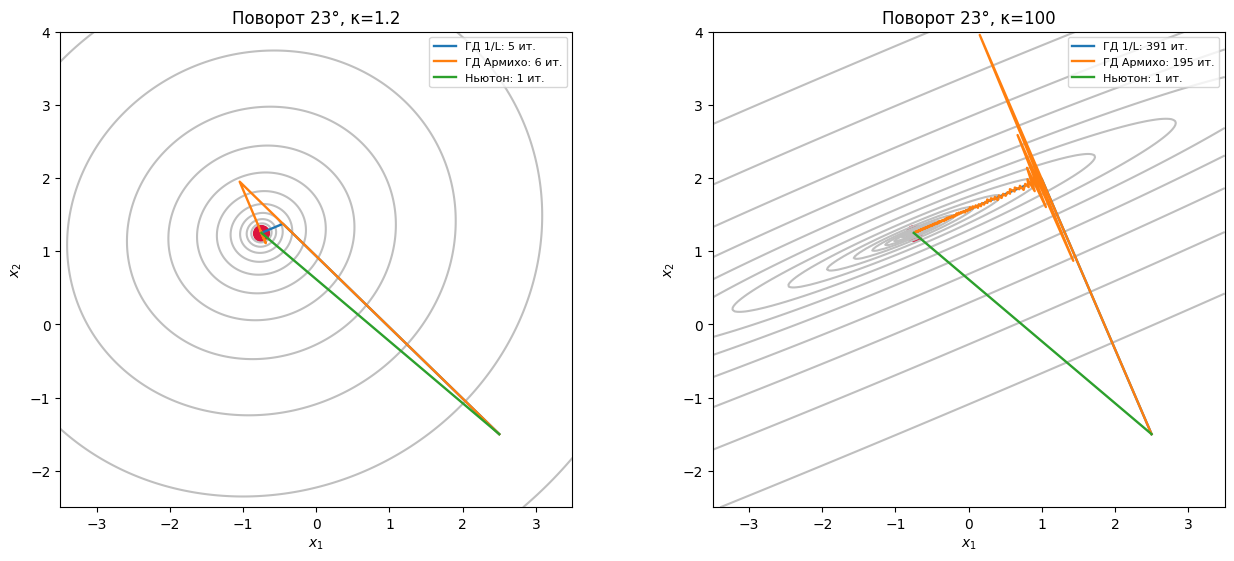

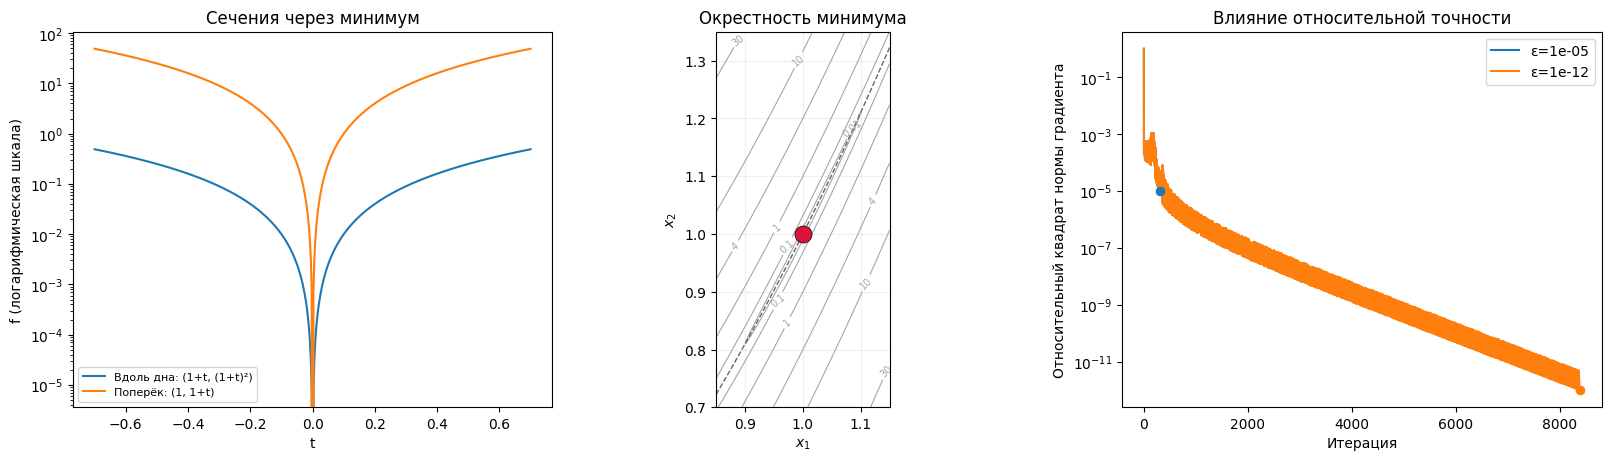

,iterations,status,distance
tolerance,,,
1.000000e-05,312,success,0.762847
1.000000e-12,8382,success,0.000410


,iterations,status,distance
tolerance,,,
1.000000e-05,312,success,0.762847
1.000000e-12,8382,success,0.000410


In [38]:
angle = np.deg2rad(23.0)
rotation = np.array([[np.cos(angle), -np.sin(angle)],
                     [np.sin(angle), np.cos(angle)]])
shifted_minimum = np.array([-0.75, 1.25])
exp1_rotated_results = {}
fig, panels = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
for ax, spectrum in zip(panels, [[1.0, 1.2], [1.0, 100.0]]):
    matrix = (rotation * spectrum) @ rotation.T
    oracle = QuadraticOracle(matrix, matrix @ shifted_minimum)
    xx, yy = np.meshgrid(np.linspace(-3.5, 3.5, 251), np.linspace(-2.5, 4.0, 251))
    displacement = np.stack((xx, yy), axis=-1) - shifted_minimum
    heights = 0.5 * np.einsum('...i,ij,...j->...', displacement, matrix, displacement)
    ax.contour(xx, yy, heights, levels=np.geomspace(.01, 300, 15), colors='0.75')
    start = np.array([2.5, -1.5])
    for label, optimizer, options in [
        ('ГД 1/L', gradient_descent, {'method':'Constant', 'c':1 / max(spectrum)}),
        ('ГД Армихо', gradient_descent, {'method':'Armijo'}),
        ('Ньютон', newton, {'method':'Constant', 'c':1.0}),
    ]:
        run = experiment_run('exp1_rotated', oracle, start, optimizer,
            problem={'fingerprint':experiment_fingerprint(matrix, oracle.b)},
            tolerance=1e-8, max_iter=10000, line_search_options=options)
        exp1_rotated_results[(max(spectrum),label)] = run
        trajectory = np.asarray(run['history']['x'])
        ax.plot(*trajectory.T, label=f"{label}: {run['iterations']} ит.", linewidth=1.7)
    ax.scatter(*shifted_minimum, marker='o', s=130, color='crimson')
    ax.set(xlabel='$x_1$', ylabel='$x_2$', title=f'Поворот 23°, κ={max(spectrum):g}')
    ax.set_aspect('equal'); ax.legend(fontsize=8)
experiment_prepare_figure(fig)
fig.savefig(FIGURES_DIR / 'exp1_rotated_quadratics.png', dpi=180)
plt.show(); plt.close(fig)

fig, panels = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
tangent = np.linspace(-.7, .7, 501)
panels[0].plot(tangent, tangent**2, label='Вдоль дна: (1+t, (1+t)²)')
panels[0].plot(tangent, 100*tangent**2, label='Поперёк: (1, 1+t)')
panels[0].set(xlabel='t', ylabel='f (логарифмическая шкала)', title='Сечения через минимум')
panels[0].set_yscale('log')
panels[0].legend(fontsize=8)
exp1_rosen_contours(panels[1], (.85, 1.15), (.7, 1.35))
panels[1].set_title('Окрестность минимума')
exp1_tolerance_demo = []
for tolerance in [1e-5, 1e-12]:
    start = np.array([-1.2, 1.0])
    run = experiment_run('exp1_tolerance', exp1_rosen_oracle, start, gradient_descent,
        problem={'function':'Rosenbrock', 'comparison':'relative_stopping'},
        tolerance=tolerance, max_iter=20000, line_search_options={'method':'Armijo'})
    exp1_rotated_results[('tolerance', tolerance)] = run
    curve = experiment_relative_gradient(run['history'])
    color = 'C0' if tolerance == 1e-5 else 'C1'
    panels[2].semilogy(curve, color=color, label=f'ε={tolerance:g}')
    panels[2].scatter(len(curve)-1, curve[-1], color=color, marker='o', s=35, zorder=4)
    exp1_tolerance_demo.append({'tolerance':tolerance, 'iterations':run['iterations'],
        'status':run['message'], 'distance':float(np.linalg.norm(run['x_opt']-exp1_rosen_minimum))})
panels[2].set(xlabel='Итерация', ylabel='Относительный квадрат нормы градиента',
              title='Влияние относительной точности'); panels[2].legend()
experiment_prepare_figure(fig)
fig.savefig(FIGURES_DIR / 'exp1_rosenbrock_sections.png', dpi=180)
plt.show(); plt.close(fig)
experiment_save_table('exp1_tolerance_comparison.csv', exp1_tolerance_demo)
experiment_show_table(exp1_tolerance_demo, index=['tolerance'],
                      values=['iterations','status','distance'])


eigen_min   eigen_max
type     x_1       x_2                             
минимум  -3.779310 -3.283186  70.714355  133.785615
седло    -3.073026 -0.081353 -39.651496   72.435248
минимум  -2.805118  3.131313  64.840373   80.550072
максимум -0.270845 -0.923039 -45.605229  -16.066020
седло    -0.127961 -1.953715 -50.610239   20.284050
          0.086678  2.884255 -31.706622   75.507609
минимум   3.000000  2.000000  25.715729   82.284271
седло     3.385154  0.073852 -14.135178   97.547878
минимум   3.584428 -1.848127  28.690677  105.418908

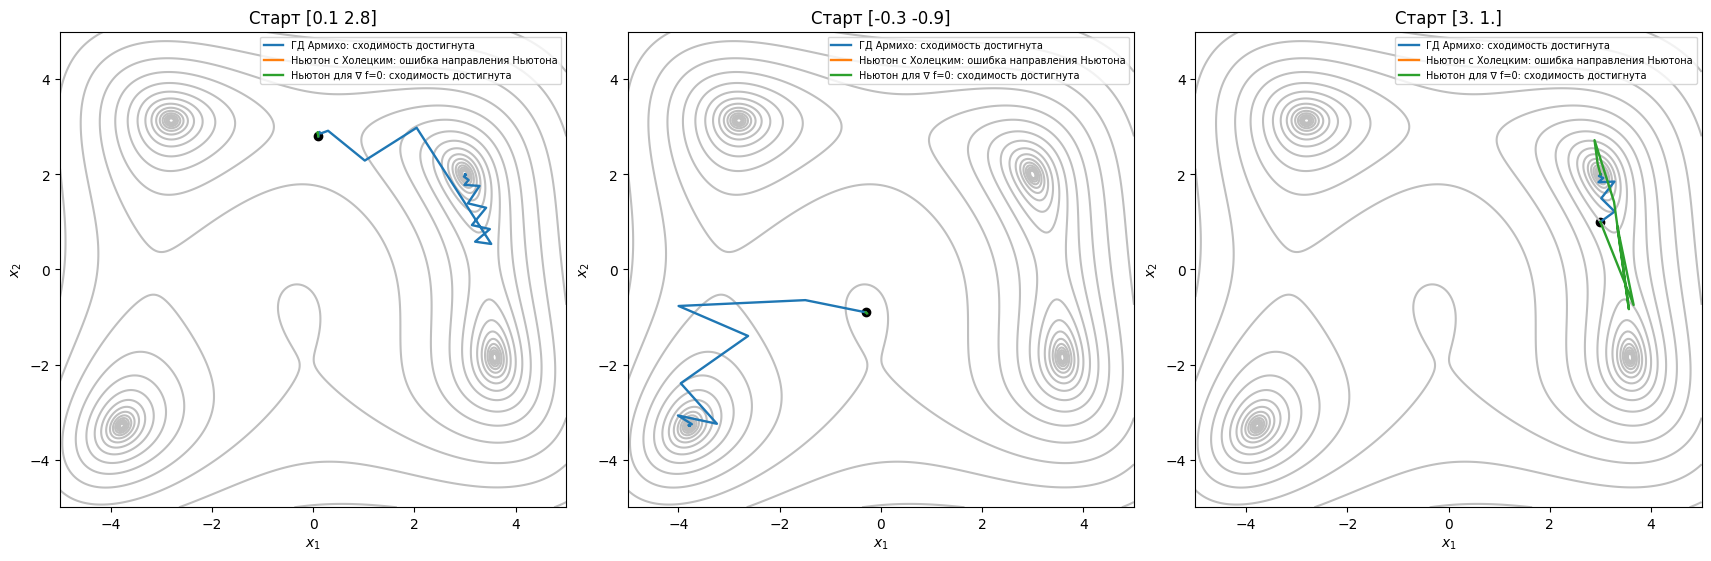

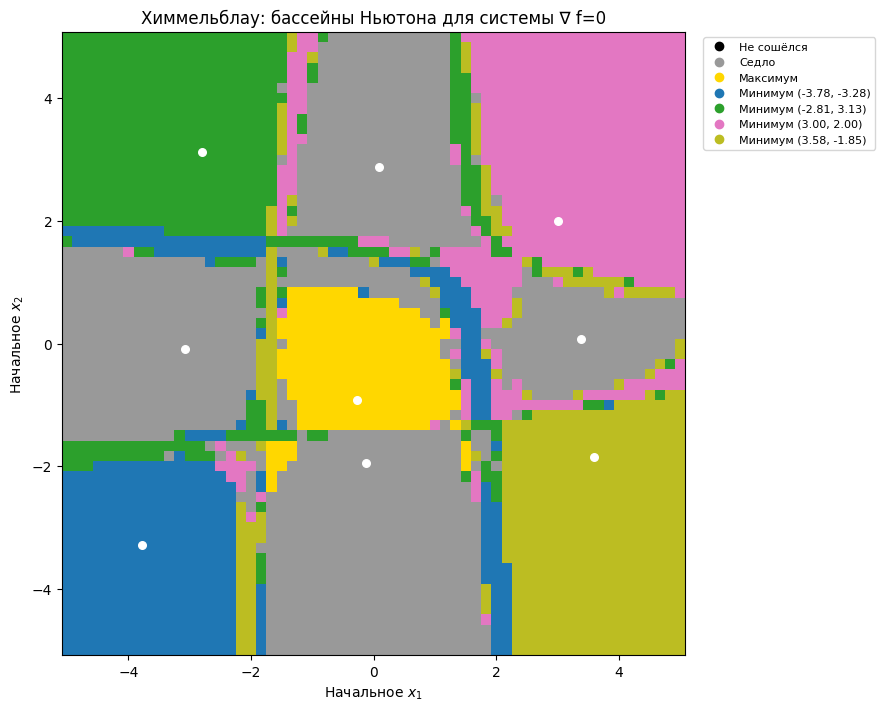

In [39]:
class HimmelblauOracle(BaseSmoothOracle):
    def func(self, point):
        u, v = point
        first, second = u*u + v - 11, u + v*v - 7
        return first*first + second*second

    def grad(self, point):
        u, v = point
        first, second = u*u + v - 11, u + v*v - 7
        return np.array([4*u*first + 2*second, 2*first + 4*v*second])

    def hess(self, point):
        u, v = point
        return np.array([[12*u*u + 4*v - 42, 4*(u+v)],
                         [4*(u+v), 4*u + 12*v*v - 26]])


def experiment_stationary_newton(oracle, x_0, tolerance=1e-12, max_iter=100,
                                  trace=False, display=False):
    """Ньютон для системы grad f=0: допускает неопределённый H и рост f."""
    point = np.array(x_0, dtype=float, copy=True)
    history = defaultdict(list) if trace else None
    started, initial_squared = time.perf_counter(), None
    for iteration in range(max_iter + 1):
        value, gradient = oracle.func(point), oracle.grad(point)
        squared = float(gradient @ gradient)
        if not np.isfinite(value) or not np.isfinite(squared):
            return point, 'computational_error', history
        if initial_squared is None:
            initial_squared = squared
        if trace:
            history['time'].append(time.perf_counter()-started)
            history['func'].append(float(value))
            history['grad_norm'].append(float(np.sqrt(squared)))
            if point.size <= 2:
                history['x'].append(point.copy())
        if squared <= tolerance*initial_squared:
            return point, 'success', history
        if iteration == max_iter:
            break
        try:
            direction = np.linalg.solve(oracle.hess(point), -gradient)
        except LinAlgError:
            return point, 'singular_hessian', history
        candidate = point + direction
        if not np.all(np.isfinite(candidate)):
            return point, 'computational_error', history
        point = candidate
    return point, 'iterations_exceeded', history


himmelblau = HimmelblauOracle()
critical = []
for u in np.linspace(-5,5,9):
    for v in np.linspace(-5,5,9):
        root = scipy.optimize.root(himmelblau.grad, [u,v], jac=himmelblau.hess)
        if np.linalg.norm(himmelblau.grad(root.x)) < 1e-6:
            if all(np.linalg.norm(root.x-found)>1e-4 for found in critical):
                critical.append(root.x)
critical = np.array(sorted(critical,key=lambda point:(point[0],point[1])))
critical_types = []
critical_rows = []
for point in critical:
    spectrum = np.linalg.eigvalsh(himmelblau.hess(point))
    kind = 'минимум' if np.all(spectrum>0) else 'максимум' if np.all(spectrum<0) else 'седло'
    critical_types.append(kind)
    critical_rows.append({'x_1':point[0],'x_2':point[1],'type':kind,
                          'eigen_min':spectrum[0],'eigen_max':spectrum[-1]})
experiment_save_table('exp1_himmelblau_critical_points.csv',critical_rows)
experiment_show_table(critical_rows,index=['type','x_1','x_2'])

exp1_himmelblau_results = {}
fig, panels = plt.subplots(1,3,figsize=(17,5.5),constrained_layout=True)
xx, yy = np.meshgrid(np.linspace(-5,5,301),np.linspace(-5,5,301))
height = (xx*xx+yy-11)**2+(xx+yy*yy-7)**2
for ax,start in zip(panels,[np.array([.1,2.8]),np.array([-.3,-.9]),np.array([3.,1.])]):
    ax.contour(xx,yy,height,levels=np.geomspace(.1,1000,17),colors='0.75')
    for name,method,kwargs in [
        ('ГД Армихо',gradient_descent,{'max_iter':10000,'line_search_options':{'method':'Armijo'}}),
        ('Ньютон с Холецким',newton,{'max_iter':100,'line_search_options':{'method':'Armijo'}}),
        ('Ньютон для grad f=0',experiment_stationary_newton,{'max_iter':100}),
    ]:
        run=experiment_run('exp1_himmelblau',himmelblau,start,method,
            problem={'function':'Himmelblau'},tolerance=1e-12,**kwargs)
        exp1_himmelblau_results[(tuple(start),name)]=run
        trajectory=np.asarray(run['history']['x'])
        ax.plot(*trajectory.T,linewidth=1.7,label=f"{name}: {run['message']}")
    ax.scatter(*start,marker='o',color='black')
    ax.set(xlim=(-5,5),ylim=(-5,5),xlabel='$x_1$',ylabel='$x_2$',title=f'Старт {start}')
    ax.legend(fontsize=7)
experiment_prepare_figure(fig)
fig.savefig(FIGURES_DIR/'exp1_himmelblau_trajectories.png',dpi=180)
plt.show();plt.close(fig)

extra_grid=np.linspace(-5,5,61)
extra_config={'version':1,'grid_size':len(extra_grid),'bounds':[-5,5],
              'absolute_grad_target':1e-6,'max_iter':100,'numpy':np.__version__,
              'scipy':scipy.__version__,'critical_points':critical.round(10).tolist()}
extra_signature=hashlib.sha256(json.dumps(extra_config,sort_keys=True).encode()).hexdigest()[:12]
extra_path=RESULTS_DIR/f'himmelblau_stationary_basins_{extra_signature}.npz'
if extra_path.exists():
    with np.load(extra_path,allow_pickle=False) as saved:
        basin_labels=saved['labels'].copy()
else:
    basin_labels=np.full((len(extra_grid),len(extra_grid)),-1,dtype=int)
    for row,v in enumerate(extra_grid):
        for col,u in enumerate(extra_grid):
            start=np.array([u,v]);g0=himmelblau.grad(start)
            tolerance=min(1e-12,1e-12/max(float(g0@g0),np.finfo(float).tiny))
            end,status,_=experiment_stationary_newton(himmelblau,start,tolerance=tolerance)
            if status=='success':
                distances=np.linalg.norm(critical-end,axis=1)
                nearest=int(np.argmin(distances))
                if distances[nearest]<1e-3:
                    basin_labels[row,col]=nearest
    temporary=extra_path.with_suffix('.tmp')
    with temporary.open('wb') as stream:
        np.savez_compressed(stream,labels=basin_labels,critical_points=critical,
                            config_json=json.dumps(extra_config,sort_keys=True))
    temporary.replace(extra_path)
fig,ax=plt.subplots(figsize=(9,7),constrained_layout=True)
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
palette=['black']+[plt.get_cmap('tab10')(i) if kind=='минимум'
                  else '0.6' if kind=='седло' else 'gold' for i,kind in enumerate(critical_types)]
cmap=ListedColormap(palette)
ax.pcolormesh(extra_grid,extra_grid,basin_labels+1,cmap=cmap,
              norm=BoundaryNorm(np.arange(len(palette)+1)-.5,len(palette)),shading='nearest')
ax.scatter(*critical.T,marker='o',color='white',s=30)
ax.set(xlabel='Начальное $x_1$',ylabel='Начальное $x_2$',
       title='Химмельблау: бассейны Ньютона для системы grad f=0',aspect='equal')
handles=[Line2D([], [], marker='o', linestyle='None', color='black',label='Не сошёлся'),Line2D([], [], marker='o', linestyle='None', color='0.6',label='Седло'),
         Line2D([], [], marker='o', linestyle='None', color='gold',label='Максимум')]
handles += [Line2D([], [], marker='o', linestyle='None', color=palette[i+1],label=f'Минимум ({p[0]:.2f}, {p[1]:.2f})')
            for i,p in enumerate(critical) if critical_types[i]=='минимум']
ax.legend(handles=handles,loc='upper left',bbox_to_anchor=(1.02,1),fontsize=8)
experiment_prepare_figure(fig)
fig.savefig(FIGURES_DIR/'exp1_himmelblau_basins.png',dpi=180)
plt.show();plt.close(fig)


Эксперимент 1, часть 2: Ваш ответ

**Функция и критические точки.**

Рассмотрена функция Розенброка
$$
f(x_1,x_2)=(1-x_1)^2+100(x_2-x_1^2)^2.
$$
Из $\partial f/\partial x_2=200(x_2-x_1^2)=0$ следует, что $x_2=x_1^2$.
После подстановки в первую компоненту градиента получаем $2(x_1-1)=0$.
Следовательно, единственная стационарная точка на всей плоскости — $(1,1)$.
Оба слагаемых функции неотрицательны и одновременно равны нулю только в этой
точке, поэтому это единственный глобальный минимум, $f^*=0$.

В минимуме
$$
H(1,1)=\begin{pmatrix}802&-400\\-400&200\end{pmatrix},
\qquad
\lambda_{\min}\approx0.39936,
\quad \lambda_{\max}\approx1001.60064.
$$
Гессиан положительно определён; его число обусловленности —
примерно $2.51\cdot10^3$.
$$
\kappa_2\bigl(H(1,1)\bigr)
=\frac{\lambda_{\max}\bigl(H(1,1)\bigr)}{\lambda_{\min}\bigl(H(1,1)\bigr)}
\approx\frac{1001.60064}{0.39936}
\approx2.51\cdot10^3.
$$
Сёдел и локальных максимумов у функции Розенброка нет.
При этом функция не выпукла на всей плоскости: например,
$H(0,2)=\operatorname{Diag}(-798,200)$ имеет собственные значения разных знаков.

На общем графике линий уровня присутствует изогнутый овраг вдоль $x_2=x_1^2$.
На увеличенном фрагменте видно, насколько узок овраг вблизи минимума.
На дополнительном рисунке построены сечения
$$
f(1+t,(1+t)^2)=t^2,\qquad f(1,1+t)=100t^2.
$$
По этим сечениям видно, как по-разному функция меняется вдоль дна и поперёк него.
Отношение этих коэффициентов не равно числу обусловленности гессиана:
кривые имеют разные параметризации, а обусловленность определяется
собственными значениями в ортонормированных направлениях.

**Параметры и траектории.**

В GD и методе Ньютона шаг выбирается по Армихо с $c_1=10^{-4}$, дроблением шага пополам
и первым пробным шагом $1$. В GD следующая попытка начинается с удвоенного
принятого шага, в методе Ньютона на каждой итерации сначала пробуется $\alpha=1$.
Лимит — $10000$ итераций. Относительный критерий дополнен абсолютным контролем:
$$
\|\nabla f(x_k)\|_2^2
\leq \min\!\left(10^{-8}\|\nabla f(x_0)\|_2^2,10^{-6}\right).
$$
Абсолютный контроль предотвращает слишком раннюю остановку из стартов с большим начальным градиентом.

| Начальная точка | Особенность старта | Итерации GD | Итерации Ньютона |
|---|---|---:|---:|
| $(-1.5,2.25)$ | На дне оврага | 7960 | 21 |
| $(-1.2,1)$ | Рядом с дном | 6586 | 20 |
| $(1.5,-1)$ | Крутой склон | 6412 | 10 |
| $(0,2)$ | Неопределённый гессиан | 6403 | Ошибка направления до первого шага |

На графиках GD быстро приближается к оврагу и затем медленно движется вдоль него.
Ньютон на трёх успешных стартах учитывает изменение кривизны и достигает
окрестности минимума за 10–21 итерацию. Все успешные траектории заканчиваются
около точки $(1,1)$. Небольшое число итераций Ньютона согласуется с теорией его локальной сходимости. Однако одного числа итераций недостаточно, чтобы подтвердить квадратичную скорость сходимости.

Сравнение запусков с разными относительными точностями из $(-1.2,1)$ показывает,
зачем контролировать остановку. При $\varepsilon=10^{-5}$ GD завершился
за 312 итераций, но расстояние до минимума осталось около $0.763$.
При $\varepsilon=10^{-12}$ потребовалось 8382 итерации, а расстояние уменьшилось
до $4.10\cdot10^{-4}$. На соответствующем графике отмечены конечные точки кривых.

**3. Ошибка Холецкого и карты стартов**

Для гессиана функции Розенброка
$$
\det H(x_1,x_2)=400+80000(x_1^2-x_2).
$$
Поскольку $H_{22}=200>0$, положительная определённость равносильна
$$
x_2<x_1^2+0.005.
$$
На границе гессиан вырожден, выше неё — неопределён.
В точке $(0,2)$ разложение Холецкого невозможно, поэтому реализация
возвращает `newton_direction_error`. Матрица здесь обратима, но
не задаёт выпуклую квадратичную модель. Условие обратимости само по себе
не гарантирует спусковость ньютоновского направления; в нашей реализации
для минимизации требуется положительная определённость.

Карты построены на сетке $200\times200$ в квадрате $[-5,5]^2$:
по $40000$ независимых стартов для каждого метода. Зелёным отмечены
запуски со статусом `success`, нормой градиента не больше $10^{-3}$
и расстоянием до $(1,1)$ не больше $0.01$. Остальные точки чёрные.

| Метод | Достигли минимума | Доля успешных | Лимит итераций | Ошибка направления | Время карты, с |
|---|---:|---:|---:|---:|---:|
| GD, Армихо | 33146 | $82.865\%$ | 6854 | 0 | 285.7 |
| Ньютон, Армихо | 34064 | $85.160\%$ | 0 | 5936 | 44.6 |

Вычисления выполнены в Colab; характеристики среды указаны в части 1.
Независимые старты карты обрабатывались пакетами до 16 строк с индивидуальными
шагами и критериями остановки.

На карте GD чёрные области имеют неровные границы. Во всех этих точках
причина — лимит $10000$ итераций; достижение лимита не означает ухода на бесконечность
или существования других минимумов. Карта отражает достижение заданной
точности за ограниченное число шагов; она не описывает полностью
асимптотический бассейн притяжения.

На карте Ньютона граница чёрной области совпадает с параболой
$x_2=x_1^2+0.005$. На сетке ровно 5936 стартов имеют начальный гессиан, который не является
положительно определённым. Это совпадает с числом ошибок направления. Остальные
34064 старта привели к минимуму. На этой карте граница выглядит как плавная кривая; признаков фрактальности не обнаружено. Серый цвет не используется,
поскольку у Розенброка нет сёдел и максимумов.

**4. Поведение около седла**

Рассмотрим стационарную точку $x_s$ с отрицательным собственным
значением $\nu$ гессиана. При фиксированном положительном шаге локальная
линеаризация GD имеет вид
$$
e_{k+1}\approx(I-\alpha H(x_s))e_k,\qquad e_k=x_k-x_s.
$$
В направлении отрицательной кривизны множитель равен
$1-\alpha\nu=1+\alpha|\nu|>1$: малое возмущение растёт, поэтому седло
отталкивает траекторию в этом направлении. Это объясняет, почему обычные
старты рядом с седлом, как правило, не приводят к нему. Исключения возможны,
например точный старт в стационарной точке. Этот локальный аргумент
не является полной теоремой об избегании всех сёдел для адаптивного Армихо.

**5. Чистый Ньютон и дополнительная функция Химмельблау**

Чтобы наблюдать сёдла и несколько минимумов, дополнительно рассмотрена
$$
F(u,v)=(u^2+v-11)^2+(u+v^2-7)^2.
$$
Численный поиск дал девять стационарных точек: четыре минимума,
четыре седла и один максимум. Тип каждой точки определён по знакам собственных
значений гессиана; координаты и спектры приведены в таблице после вычислений.

На дополнительном графике траекторий сравниваются GD, Ньютон
с Холецким и Ньютон для системы $\nabla F=0$ с единичным шагом.
Для этих траекторий задан относительный квадрат нормы градиента
не больше $10^{-12}$, лимит GD — $10000$ итераций,
обоих вариантов Ньютона — $100$.
Чистый Ньютон допускает неопределённый гессиан и не проверяет
уменьшение функции. Из $(0.1,2.8)$ он приходит к седлу около
$(0.08668,2.88425)$, а из $(-0.3,-0.9)$ — к максимуму около
$(-0.27084,-0.92304)$. GD из этих стартов приходит к минимумам;
вариант с Холецким останавливается из-за гессиана.

Чистый Ньютон ищет корень градиента. Любая стационарная
точка с невырожденным гессианом, включая седло и максимум, может его притягивать.
Для отображения $T(x)=x-H(x)^{-1}\nabla F(x)$ в такой точке
$$
T'(x_s)=I-H(x_s)^{-1}H(x_s)=0.
$$
При достаточной локальной гладкости это даёт квадратичное уменьшение ошибки
при близком старте независимо от типа стационарной точки. Это расширение идеи
локального анализа Ньютона на решение системы, а не гарантия минимизации.

Карта Химмельблау построена для чистого Ньютона на сетке $61\times61$
в квадрате $[-5,5]^2$ с лимитом $100$ итераций. При том же относительном
критерии дополнительно проверяется $\|\nabla F\|_2\leq10^{-6}$.
Для отнесения к стационарной точке также проверяется расстояние до неё:
оно должно быть меньше $10^{-3}$.
Разные минимумы имеют разные цвета,
сёдла отмечены серым, максимум — жёлтым. Видны области притяжения
неминимальных стационарных точек и сложные участки границ. Разрешения одной
сетки недостаточно для надёжного вывода о фрактальности: для этого нужны
увеличения и исследование границ на нескольких масштабах.


## Эксперимент 2. Зависимость числа итераций градиентного спуска от числа обусловленности и размерности

Исследуйте, как число итераций $T(n, \kappa)$, необходимое градиентному спуску для выполнения критерия (1), зависит от числа обусловленности $\kappa \ge 1$ и размерности $n$.

**Генерация задачи.** Возьмите диагональную матрицу $A = \mathrm{Diag}(a)$, где элементы $a$ случайны в пределах $[1, \kappa]$, причём $\min(a) = 1$, $\max(a) = \kappa$. Вектор $b$ возьмите случайным. Храните $A$ как разреженную диагональную матрицу (`scipy.sparse.diags`), тогда эксперимент работает даже при больших $n$.

**Порядок проведения.**
1. Зафиксируйте $n$. Переберите $\kappa$ по логарифмической сетке и постройте график $T(n, \kappa)$ от $\kappa$. Задача генерируется случайно, поэтому повторите эксперимент несколько раз: получится семейство кривых. Нарисуйте их одним цветом.
2. Повторите для других $n$ по логарифмической сетке ($n = 10, 100, 1000, \dots$), каждое семейство своим цветом.
3. Для сравнения проведите тот же эксперимент для метода Ньютона (хватит нескольких значений $\kappa$ и $n$).

### Вопросы для отчёта
1. Какие выводы можно сделать из полученной картинки? Сравните наблюдаемую зависимость с теоретической оценкой числа итераций градиентного спуска.
2. Зависит ли число итераций от размерности $n$ при фиксированном $\kappa$? Почему?
3. Что происходит с числом итераций метода Ньютона при росте $\kappa$? Объясните результат через формулу шага метода Ньютона для квадратичной функции.

In [40]:
exp2_dimensions = [10, 100, 1000, 10000]
exp2_kappas = np.logspace(0, 3, 10)
exp2_repeats = 5
exp2_tolerance = 1e-8
exp2_max_iter = 20000
exp2_results = {}


def exp2_problem(n, kappa, repeat):
    rng = np.random.default_rng(np.random.SeedSequence([SEED, 2, n, repeat]))
    uniform = rng.uniform(size=n)
    diagonal = 1.0 + (float(kappa) - 1.0) * uniform
    diagonal[0], diagonal[-1] = 1.0, float(kappa)
    b = rng.normal(size=n)
    A = scipy.sparse.diags(diagonal, format='csr')
    return QuadraticOracle(A, b)


for n in exp2_dimensions:
    for repeat in range(exp2_repeats):
        for kappa in exp2_kappas:
            oracle = exp2_problem(n, kappa, repeat)
            result = experiment_run(
                'exp2', oracle, np.zeros(n), gradient_descent,
                problem={'n': n, 'kappa': float(kappa), 'repeat': repeat, 'seed': SEED},
                tolerance=exp2_tolerance, max_iter=exp2_max_iter,
                line_search_options={'method': 'Constant', 'c': 1.0 / float(kappa)},
            )
            exp2_results[(n, repeat, float(kappa))] = result
        print(f'ГД: n = {n}, повтор {repeat + 1}/{exp2_repeats} завершён', flush=True)

exp2_newton_dimensions = [10, 100, 1000]
exp2_newton_kappas = [1.0, 10.0, 1000.0]
exp2_newton_results = {}
for n in exp2_newton_dimensions:
    for kappa in exp2_newton_kappas:
        for repeat in range(2):
            oracle = exp2_problem(n, kappa, repeat)
            result = experiment_run(
                'exp2', oracle, np.zeros(n), newton,
                problem={'n': n, 'kappa': kappa, 'repeat': repeat, 'seed': SEED},
                tolerance=exp2_tolerance,
                line_search_options={'method': 'Constant', 'c': 1.0},
            )
            exp2_newton_results[(n, repeat, kappa)] = result
            print(f"Ньютон: n = {n}, kappa = {kappa:g}, повтор = {repeat}, "
                  f"T = {result['iterations']}, {result['message']}")

exp2_table = [
    {'method': method, 'n': n, 'repeat': repeat, 'kappa': kappa,
     'iterations': result['iterations'], 'status': result['message'],
     'relative_grad_sq': float(experiment_relative_gradient(result['history'])[-1]),
     'seconds': result['elapsed'], 'oracle_calls': result['oracle_calls']}
    for method, results in [('GD Constant 1/L', exp2_results), ('Newton', exp2_newton_results)]
    for (n, repeat, kappa), result in results.items()
]
experiment_save_table('exp2_iterations.csv', exp2_table)
print('Статусы:', {status: sum(r['status'] == status for r in exp2_table)
                   for status in sorted({r['status'] for r in exp2_table})})

experiment_show_table(exp2_table, index=['n', 'kappa', 'repeat'], columns='method', values=['iterations', 'status'])


ГД: n = 10, повтор 1/5 завершён
ГД: n = 10, повтор 2/5 завершён
ГД: n = 10, повтор 3/5 завершён
ГД: n = 10, повтор 4/5 завершён
ГД: n = 10, повтор 5/5 завершён
ГД: n = 100, повтор 1/5 завершён
ГД: n = 100, повтор 2/5 завершён
ГД: n = 100, повтор 3/5 завершён
ГД: n = 100, повтор 4/5 завершён
ГД: n = 100, повтор 5/5 завершён
ГД: n = 1000, повтор 1/5 завершён
ГД: n = 1000, повтор 2/5 завершён
ГД: n = 1000, повтор 3/5 завершён
ГД: n = 1000, повтор 4/5 завершён
ГД: n = 1000, повтор 5/5 завершён
ГД: n = 10000, повтор 1/5 завершён
ГД: n = 10000, повтор 2/5 завершён
ГД: n = 10000, повтор 3/5 завершён
ГД: n = 10000, повтор 4/5 завершён
ГД: n = 10000, повтор 5/5 завершён
Ньютон: n = 10, kappa = 1, повтор = 0, T = 1, success
Ньютон: n = 10, kappa = 1, повтор = 1, T = 1, success
Ньютон: n = 10, kappa = 10, повтор = 0, T = 1, success
Ньютон: n = 10, kappa = 10, повтор = 1, T = 1, success
Ньютон: n = 10, kappa = 1000, повтор = 0, T = 1, success
Ньютон: n = 10, kappa = 1000, повтор = 1, T = 1, succes

iterations                 status         
method              GD Constant 1/L Newton GD Constant 1/L   Newton
n     kappa  repeat                                                
10    1.0    0                  1.0    1.0         success  success
             1                  1.0    1.0         success  success
             2                  1.0    NaN         success      NaN
             3                  1.0    NaN         success      NaN
             4                  1.0    NaN         success      NaN
...                             ...    ...             ...      ...
10000 1000.0 0               5214.0    NaN         success      NaN
             1               5136.0    NaN         success      NaN
             2               5536.0    NaN         success      NaN
             3               4512.0    NaN         success      NaN
             4               5567.0    NaN         success      NaN

[200 rows x 4 columns]

iterations                 status         
method              GD Constant 1/L Newton GD Constant 1/L   Newton
n     kappa  repeat                                                
10    1.0    0                  1.0    1.0         success  success
             1                  1.0    1.0         success  success
             2                  1.0    NaN         success      NaN
             3                  1.0    NaN         success      NaN
             4                  1.0    NaN         success      NaN
...                             ...    ...             ...      ...
10000 1000.0 0               5214.0    NaN         success      NaN
             1               5136.0    NaN         success      NaN
             2               5536.0    NaN         success      NaN
             3               4512.0    NaN         success      NaN
             4               5567.0    NaN         success      NaN

[200 rows x 4 columns]

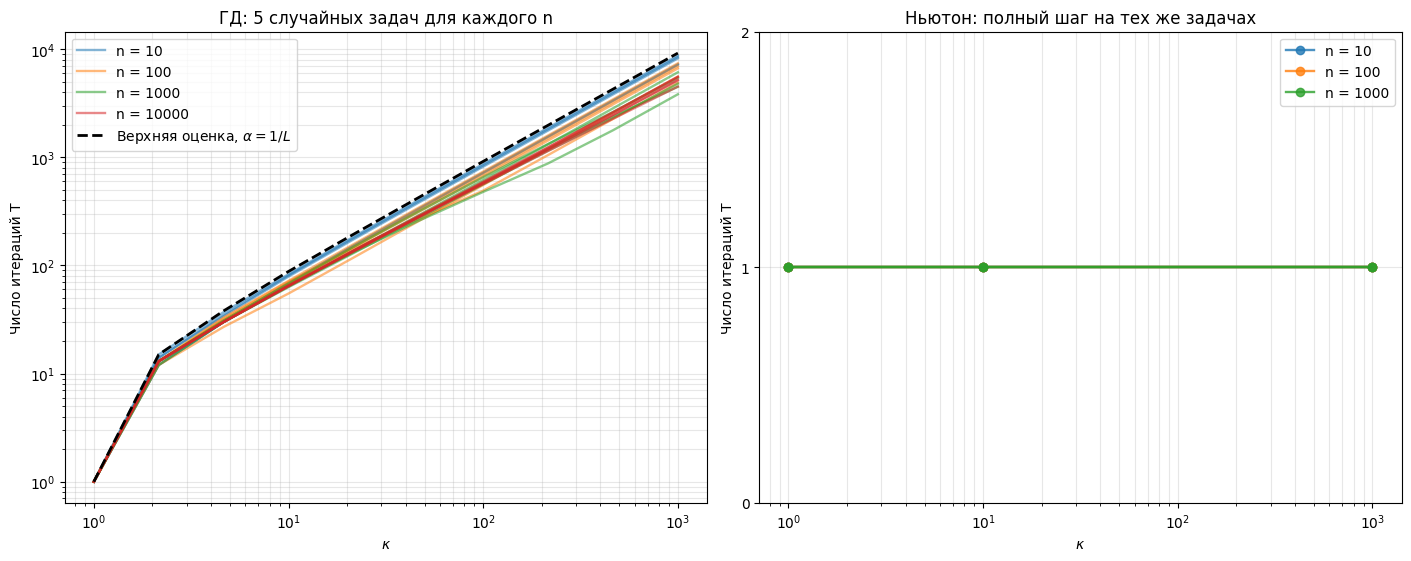

In [41]:
exp2_fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
for color_index, n in enumerate(exp2_dimensions):
    color = f'C{color_index}'
    for repeat in range(exp2_repeats):
        results = [exp2_results[(n, repeat, float(k))] for k in exp2_kappas]
        iterations = [r['iterations'] if r['message'] == 'success' else np.nan for r in results]
        axes[0].plot(exp2_kappas, iterations, color=color, alpha=0.55,
                     linewidth=1.7, label=f'n = {n}' if repeat == 0 else None)
        failed = [i for i, r in enumerate(results) if r['message'] != 'success']
        if failed:
            axes[0].scatter(exp2_kappas[failed], [results[i]['iterations'] for i in failed],
                            color='red', marker='o', s=70)
exp2_bound = np.ones_like(exp2_kappas)
mask = exp2_kappas > 1
exp2_bound[mask] = np.ceil(
    np.log(exp2_tolerance) / (2 * np.log1p(-1.0 / exp2_kappas[mask]))
)
axes[0].plot(exp2_kappas, exp2_bound, 'k--', linewidth=2,
             label=r'Верхняя оценка, $\alpha=1/L$')
axes[0].set(xscale='log', yscale='log', xlabel=r'$\kappa$',
            ylabel='Число итераций T', title=f'ГД: {exp2_repeats} случайных задач для каждого n')
axes[0].legend()
for color_index, n in enumerate(exp2_newton_dimensions):
    for repeat in range(2):
        values = [exp2_newton_results[(n, repeat, k)]['iterations'] for k in exp2_newton_kappas]
        axes[1].plot(exp2_newton_kappas, values, marker='o',
                     markersize=6, markerfacecolor='auto',
                     color=f'C{color_index}', linewidth=1.7, alpha=0.8,
                     label=f'n = {n}' if repeat == 0 else None)
axes[1].set(xscale='log', xlabel=r'$\kappa$', ylabel='Число итераций T',
            title='Ньютон: полный шаг на тех же задачах', ylim=(0, 2))
axes[1].set_yticks([0, 1, 2])
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3, which='both')
experiment_prepare_figure(exp2_fig)
exp2_fig.savefig(experiment_output_dir / 'exp2_conditioning_dimension.png', dpi=180)
plt.show()
plt.close(exp2_fig)


log_log_slope  largest_T_over_kappa
n     repeat                                     
10    0            1.007686                 8.229
      1            1.009291                 7.256
      2            1.009534                 8.736
      3            1.008411                 8.474
      4            1.007626                 7.183
100   0            0.911074                 4.879
      1            1.004505                 6.959
      2            1.003576                 5.568
      3            1.005764                 7.408
      4            0.994060                 6.651
1000  0            0.989873                 6.120
      1            0.868117                 3.830
      2            0.945937                 5.417
      3            0.940087                 4.795
      4            0.925486                 4.498
10000 0            0.952423                 5.214
      1            0.945543                 5.136
      2            0.961808                 5.536
      3            0.919681                 4.512
      4            0.965953                 5.567

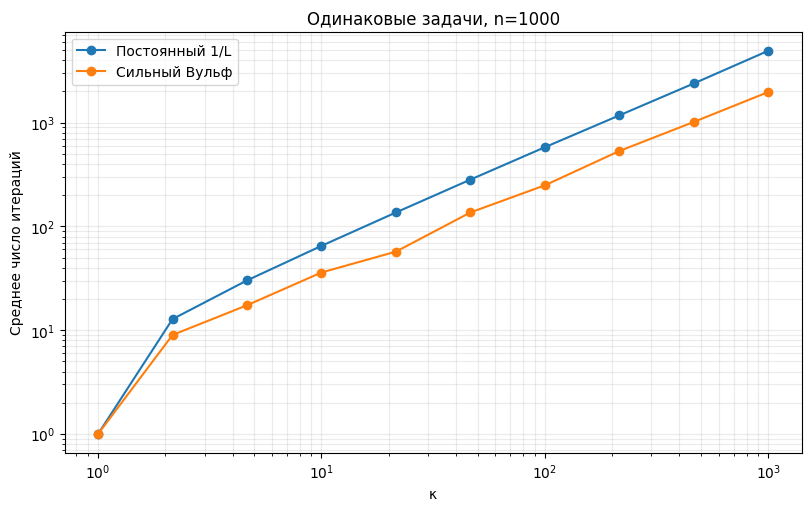

In [43]:
exp2_scaling_rows = []
for n in exp2_dimensions:
    for repeat in range(exp2_repeats):
        kappas, counts = [], []
        for kappa in exp2_kappas:
            run = exp2_results[(n, repeat, float(kappa))]
            if run['message'] == 'success' and kappa >= 10:
                kappas.append(kappa); counts.append(run['iterations'])
        slope = float(np.polyfit(np.log(kappas), np.log(counts), 1)[0]) if len(counts)>1 else np.nan
        exp2_scaling_rows.append({'n':n, 'repeat':repeat, 'log_log_slope':slope,
                                  'largest_T_over_kappa':counts[-1]/kappas[-1] if counts else np.nan})
experiment_save_table('exp2_scaling_diagnostics.csv', exp2_scaling_rows)
experiment_show_table(exp2_scaling_rows, index=['n','repeat'])

exp2_wolfe_results = {}
comparison_dimension = 1000
for repeat in range(exp2_repeats):
    for kappa in exp2_kappas:
        run = experiment_run('exp2_wolfe', exp2_problem(comparison_dimension,kappa,repeat),
            np.zeros(comparison_dimension), gradient_descent,
            problem={'n':comparison_dimension,'kappa':float(kappa),'repeat':repeat,'seed':SEED},
            tolerance=exp2_tolerance, max_iter=exp2_max_iter, line_search_options={'method':'Wolfe'})
        exp2_wolfe_results[(repeat,float(kappa))] = run
fig, ax = plt.subplots(figsize=(8,5), constrained_layout=True)
for label, get_run in [
    ('Постоянный 1/L', lambda r,k:exp2_results[(comparison_dimension,r,float(k))]),
    ('Сильный Вульф', lambda r,k:exp2_wolfe_results[(r,float(k))]),
]:
    samples = np.array([[get_run(r,k)['iterations'] if get_run(r,k)['message']=='success' else np.nan
                         for k in exp2_kappas] for r in range(exp2_repeats)])
    ax.loglog(exp2_kappas, np.nanmean(samples,axis=0), marker='o', label=label)
ax.set(xlabel='κ', ylabel='Среднее число итераций', title=f'Одинаковые задачи, n={comparison_dimension}')
ax.grid(which='both',alpha=.25); ax.legend()
experiment_prepare_figure(fig)
fig.savefig(FIGURES_DIR / 'exp2_wolfe_comparison.png',dpi=180)
plt.show(); plt.close(fig)
experiment_save_table('exp2_wolfe_comparison.csv',[
    {'repeat':r,'kappa':k,'status':run['message'],'iterations':run['iterations'],
     'seconds':run['elapsed'],'oracle_calls':run['oracle_calls']}
    for (r,k),run in exp2_wolfe_results.items()])


Эксперимент 2: Ваш ответ

**Параметры эксперимента.**

Рассмотрены квадратичные функции
$$
f(x)=\frac12\langle Ax,x\rangle-\langle b,x\rangle,
\qquad A=\operatorname{Diag}(a_1,\ldots,a_n).
$$
Элементы диагонали выбирались случайно из $[1,\kappa]$, после чего крайние
значения задавались явно: $a_1=1$, $a_n=\kappa$. Поэтому $A\succ0$,
$\mu=1$, $L=\kappa$, а число обусловленности действительно равно $\kappa$.
Компоненты $b$ имеют стандартное нормальное распределение. Матрица хранится
в формате CSR через `scipy.sparse.diags`.

Использованы размерности $n\in\{10,100,1000,10000\}$ и 10 значений
$\kappa$ по логарифмической сетке от $1$ до $1000$. Для каждой размерности
проведено пять повторов. При построении каждой кривой меняется $\kappa$, а исходные случайные числа
для диагонали и вектор $b$ остаются прежними. Между повторами они меняются. Начальная точка $x_0=0$, шаг GD
$\alpha=1/L=1/\kappa$, лимит $20000$ итераций. Критерий остановки:
$$
\frac{\|\nabla f(x_k)\|_2^2}{\|\nabla f(x_0)\|_2^2}\leq10^{-8}.
$$
Для Ньютона выбраны $n\in\{10,100,1000\}$,
$\kappa\in\{1,10,1000\}$, по два повтора и полный шаг $\alpha=1$.
Размерность ограничена, поскольку реализация формирует плотный гессиан
и использует разложение Холецкого. Вычисления выполнены в `float64`,
`SEED = 42`; среда Colab та же, что в эксперименте 1.

**Результаты.**

Все 200 запусков GD и 18 запусков Ньютона завершились успешно.
В таблице приведены среднее число итераций GD по пяти повторам
и диапазон от минимального до максимального значения.

| Размерность $n$ | $\kappa=1$ | $\kappa=10$ | $\kappa=100$ | $\kappa=1000$ |
|---|---|---|---|---|
| $10$ | 1.0 (1–1) | 76.2 (69–83) | 794.6 (716–870) | 7975.6 (7183–8736) |
| $100$ | 1.0 (1–1) | 66.8 (55–72) | 628.8 (492–738) | 6293.0 (4879–7408) |
| $1000$ | 1.0 (1–1) | 65.0 (63–68) | 580.2 (479–655) | 4932.0 (3830–6120) |
| $10000$ | 1.0 (1–1) | 64.8 (64–65) | 579.6 (568–596) | 5193.0 (4512–5567) |

**1. Зависимость от числа обусловленности и сравнение с теорией.**

При росте $\kappa$ число итераций увеличивается. На графике с логарифмическими
осями кривые при $\kappa\geq10$ близки к прямым. Оценённые наклоны лежат
примерно в диапазоне $0.87$–$1.01$, что согласуется с почти пропорциональным
ростом числа итераций при фиксированной точности.

Для этой квадратичной задачи можно вывести оценку по используемому
критерию остановки. Обозначим $g_k=Ax_k-b$. Тогда
$$
g_{k+1}=\left(I-\frac{A}{\kappa}\right)g_k,
\qquad
\frac{\|g_k\|_2^2}{\|g_0\|_2^2}
\leq\left(1-\frac1\kappa\right)^{2k}.
$$
При $\kappa>1$ для достижения относительной точности $\varepsilon$
достаточно
$$
k\geq\left\lceil
\frac{\ln\varepsilon}{2\ln(1-1/\kappa)}
\right\rceil.
$$
Для больших $\kappa$ правая часть примерно равна
$\frac{\kappa}{2}\ln(1/\varepsilon)$, то есть имеет порядок
$O(\kappa\ln(1/\varepsilon))$. При $\varepsilon=10^{-8}$ и
$\kappa=1000$ оценка даёт $9206$ итераций. Все наблюдаемые значения
лежат ниже неё. Это верхняя граница: отдельная задача может решаться быстрее.
При $\kappa=1$ матрица равна $I$, и GD с шагом $1$ достигает минимума
за одну итерацию, что подтверждается всеми повторами.

**2. Влияние размерности.**

В теоретическую верхнюю оценку $n$ явно не входит. При одинаковом $\kappa$
с ростом размерности число итераций не обязательно увеличивается.
Например, при $\kappa=1000$ среднее число шагов для $n=10000$ меньше,
чем для $n=10$, но больше, чем для $n=1000$.

При этом кривые разных размерностей не обязаны совпадать. Они зависят
от всего спектра и от распределения начального градиента по направлениям.
Поскольку $x_0=0$, для диагональной задачи имеем точную формулу
$$
\frac{\|g_k\|_2^2}{\|g_0\|_2^2}
=\frac{\sum_{i=1}^n b_i^2(1-a_i/\kappa)^{2k}}
{\sum_{i=1}^n b_i^2}.
$$
При большом $n$ на специально заданное самое пологое направление
обычно приходится меньшая доля начальной нормы градиента.
Поэтому относительный критерий может выполниться раньше.
Это свойство данной генерации задач, а не универсальное ускорение от роста $n$.
При этом затраты на одну итерацию растут: для диагональной матрицы
они имеют порядок $O(n)$.

**3. Поведение метода Ньютона.**

Во всех 18 запусках Ньютон выполнил одну итерацию независимо от $n$ и $\kappa$:
$$
x_{k+1}=x_k-A^{-1}(Ax_k-b)=A^{-1}b=x^*.
$$
Квадратичная модель совпадает с исходной функцией. Без учёта ошибок
округления из любой точки достаточно не более одного полного шага. В коде направление
находится решением системы с помощью Холецкого, без явного обращения матрицы.
Рост $\kappa$ в исследованном диапазоне не изменил число шагов.
При этом стоимость итерации и чувствительность вычислений могут зависеть
от размерности и обусловленности.

На дополнительном графике для $n=1000$ поиск по Вульфу требует в среднем
меньше итераций, чем постоянный шаг $1/L$ при $\kappa>1$.
Выигрыш относится к числу шагов: поиск длины шага требует дополнительных
вызовов оракула и не гарантирует такой же выигрыш по времени.

## Эксперимент 3. Сравнение градиентного спуска и метода Ньютона на реальных данных

Сравните градиентный спуск и метод Ньютона на обеих функциях потерь.

* Коэффициент регуляризации: $\lambda = 1/m$.
* Параметры методов — по умолчанию, начальная точка $x_0 = 0$.

Постройте графики сходимости (оба метода на одном графике):
* (a) значение функции от реального времени работы (в секундах);
* (b) относительный квадрат нормы градиента $\|\nabla f(x_k)\|_2^2 / \|\nabla f(x_0)\|_2^2$ в логарифмической шкале от реального времени работы.

В отчёте укажите размеры датасетов ($m \times n$), долю ненулевых элементов матрицы $A$ и характеристики компьютера (CPU, RAM).

### Вопросы для отчёта

0. Является ли функция выпуклой? Почему?

1. Как влияет регуляризация на градиентный спуск? Подтверждается ли это графиками?

2. Какова стоимость одной итерации и сколько памяти требует каждый метод в зависимости от $m$, $n$ (и числа ненулевых элементов матрицы $A$ для разреженных данных)? Используйте нотацию $O(\cdot)$.
3. Какой метод лучше и в каких ситуациях («высокий» датасет с $m \gg n$ против «широкого» с большим $n$)?
4. Отличается ли поведение методов на регрессионной и классификационной функциях потерь? С чем это связано?

In [44]:
exp3_datasets = {
    'mg_scale': (A_mg, b_mg, 'pseudohuber'),
    'triazines_scale': (A_triazines, b_triazines, 'pseudohuber'),
    'phishing': (A_phishing, b_phishing, 'logistic'),
    'real-sim': (A_real_sim, b_real_sim, 'logistic'),
}
exp3_results = {}
exp3_table = []
exp3_newton_memory_fraction = 0.6
for dataset_name, (A, b, loss_name) in exp3_datasets.items():
    m, n = A.shape
    if b.shape != (m,) or not np.all(np.isfinite(b)):
        raise ValueError(f'{dataset_name}: неверные целевые значения')
    if not np.all(np.isfinite(A.data if scipy.sparse.issparse(A) else A)):
        raise ValueError(f'{dataset_name}: нечисловые признаки')
    if loss_name == 'logistic' and not np.all(np.isin(b, [-1.0, 1.0])):
        raise ValueError(f'{dataset_name}: метки должны быть +/-1')
    nnz = A.nnz if scipy.sparse.issparse(A) else np.count_nonzero(A)
    density = float(nnz / (m * n))
    regcoef = 1.0 / m
    oracle = create_linear_model_oracle(A, b, regcoef, loss_name)
    problem = {'dataset': dataset_name, 'fingerprint': experiment_fingerprint(A, b),
               'loss': loss_name, 'regcoef': regcoef, 'm': m, 'n': n, 'nnz': int(nnz)}
    print(f'\n{dataset_name}: {m} x {n}, nnz = {nnz}, плотность = {density:.6g}, '
          f'loss = {loss_name}, lambda = {regcoef:.6g}', flush=True)
    for method_name, optimizer in [('GD', gradient_descent), ('Newton', newton)]:
        hessian_bytes = 8 * n * n
        estimated_peak_bytes = 6 * hessian_bytes + 32 * nnz
        memory = experiment_hardware()
        available = memory['available_ram_bytes']
        if available is None and memory['ram_bytes'] is not None:
            available = memory['ram_bytes'] // 2
        budget = None if available is None else exp3_newton_memory_fraction * available
        if method_name == 'Newton' and (budget is None or estimated_peak_bytes > budget):
            reason = (f'H = {hessian_bytes / 2**30:.2f} GiB, '
                      f'оценка пика = {estimated_peak_bytes / 2**30:.2f} GiB, '
                      f'бюджет = {budget / 2**30:.2f} GiB' if budget is not None
                      else 'не удалось определить доступную память')
            result = {'message': 'skipped_memory', 'reason': reason,
                      'iterations': None, 'elapsed': None, 'oracle_calls': None,
                      'history': None, 'calls': {}}
            print(f'{method_name}: skipped_memory; {reason}', flush=True)
        else:
            result = experiment_run('exp3', oracle, np.zeros(n), optimizer, problem)
            print(f"{method_name}: {result['message']}, T = {result['iterations']}, "
                  f"время = {result['elapsed']:.3f} с, кэш = {result['cached']}", flush=True)
        exp3_results[(dataset_name, method_name)] = result
        exp3_table.append({
            'dataset': dataset_name, 'loss': loss_name, 'method': method_name,
            'm': m, 'n': n, 'nnz': int(nnz), 'density': density, 'lambda': regcoef,
            'status': result['message'], 'iterations': result['iterations'],
            'seconds': result['elapsed'], 'oracle_calls': result['oracle_calls'],
            'milliseconds_per_iteration': (1000 * result['elapsed'] / max(1, result['iterations'])
                                           if result['elapsed'] is not None else None),
            'storage': type(A).__name__,
            'relative_grad_sq': (float(experiment_relative_gradient(result['history'])[-1])
                                 if result['history'] is not None else None),
            'reason': result.get('reason', ''),
            'dense_hessian_gib': hessian_bytes / 2**30,
            'estimated_peak_gib': estimated_peak_bytes / 2**30,
        })
experiment_save_table('exp3_real_data.csv', exp3_table)
with (experiment_output_dir / 'exp3_hardware.json').open('w', encoding='utf-8') as stream:
    json.dump(experiment_machine, stream, ensure_ascii=False, indent=2)

experiment_show_table(exp3_table, index=['dataset'], columns='method', values=['iterations', 'seconds', 'milliseconds_per_iteration', 'status'])



mg_scale: 1385 x 6, nnz = 8310, плотность = 1, loss = pseudohuber, lambda = 0.000722022
GD: success, T = 41, время = 0.050 с, кэш = True
Newton: success, T = 4, время = 0.006 с, кэш = True

triazines_scale: 186 x 60, nnz = 9982, плотность = 0.894444, loss = pseudohuber, lambda = 0.00537634
GD: success, T = 224, время = 0.205 с, кэш = True
Newton: success, T = 3, время = 0.004 с, кэш = True

phishing: 11055 x 68, nnz = 331650, плотность = 0.441176, loss = logistic, lambda = 9.04568e-05
GD: success, T = 159, время = 3.120 с, кэш = True
Newton: success, T = 4, время = 0.147 с, кэш = True

real-sim: 72309 x 20958, nnz = 3709083, плотность = 0.00244751, loss = logistic, lambda = 1.38295e-05
GD: success, T = 29, время = 7.243 с, кэш = True
Newton: skipped_memory; H = 3.27 GiB, оценка пика = 19.75 GiB, бюджет = 6.27 GiB


iterations          seconds            \
method                  GD Newton        GD    Newton   
dataset                                                 
mg_scale              41.0    4.0  0.050341  0.006295   
triazines_scale      224.0    3.0  0.205369  0.003589   
phishing             159.0    4.0  3.119677  0.147338   
real-sim              29.0    NaN  7.243443       NaN   

                milliseconds_per_iteration              status                  
method                                  GD     Newton       GD          Newton  
dataset                                                                         
mg_scale                          1.227828   1.573696  success         success  
triazines_scale                   0.916828   1.196451  success         success  
phishing                         19.620611  36.834440  success         success  
real-sim                        249.773907        NaN  success  skipped_memory

iterations          seconds            \
method                  GD Newton        GD    Newton   
dataset                                                 
mg_scale              41.0    4.0  0.050341  0.006295   
triazines_scale      224.0    3.0  0.205369  0.003589   
phishing             159.0    4.0  3.119677  0.147338   
real-sim              29.0    NaN  7.243443       NaN   

                milliseconds_per_iteration              status                  
method                                  GD     Newton       GD          Newton  
dataset                                                                         
mg_scale                          1.227828   1.573696  success         success  
triazines_scale                   0.916828   1.196451  success         success  
phishing                         19.620611  36.834440  success         success  
real-sim                        249.773907        NaN  success  skipped_memory

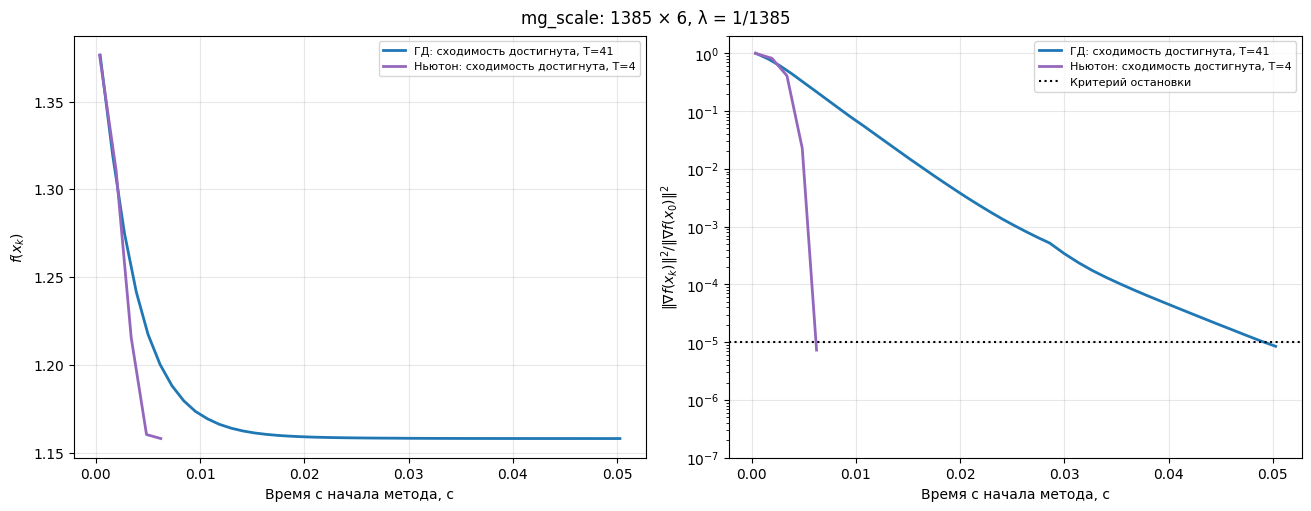

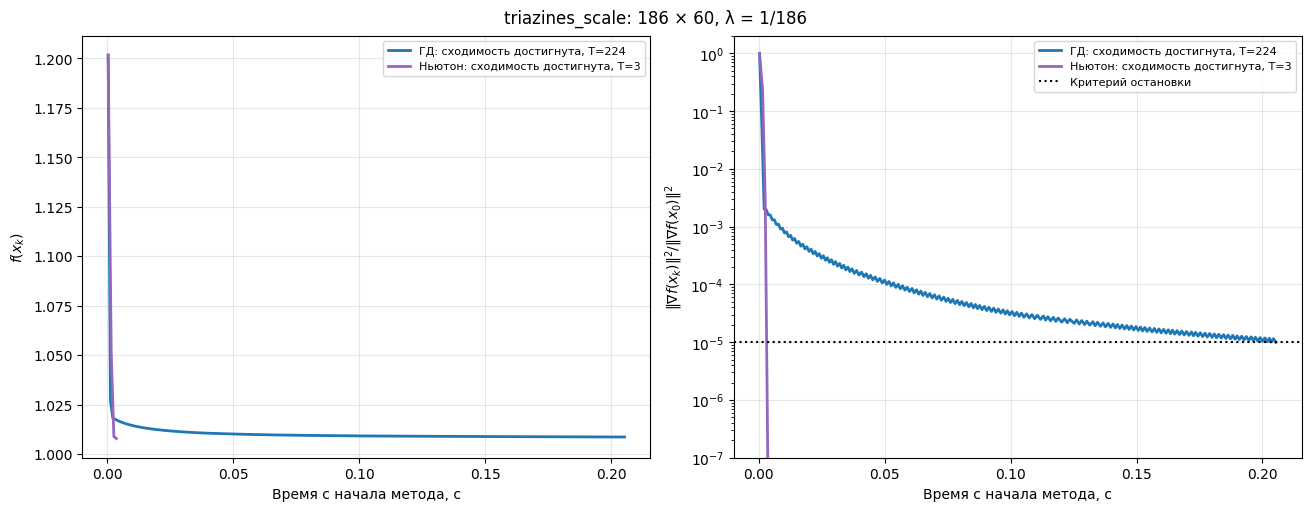

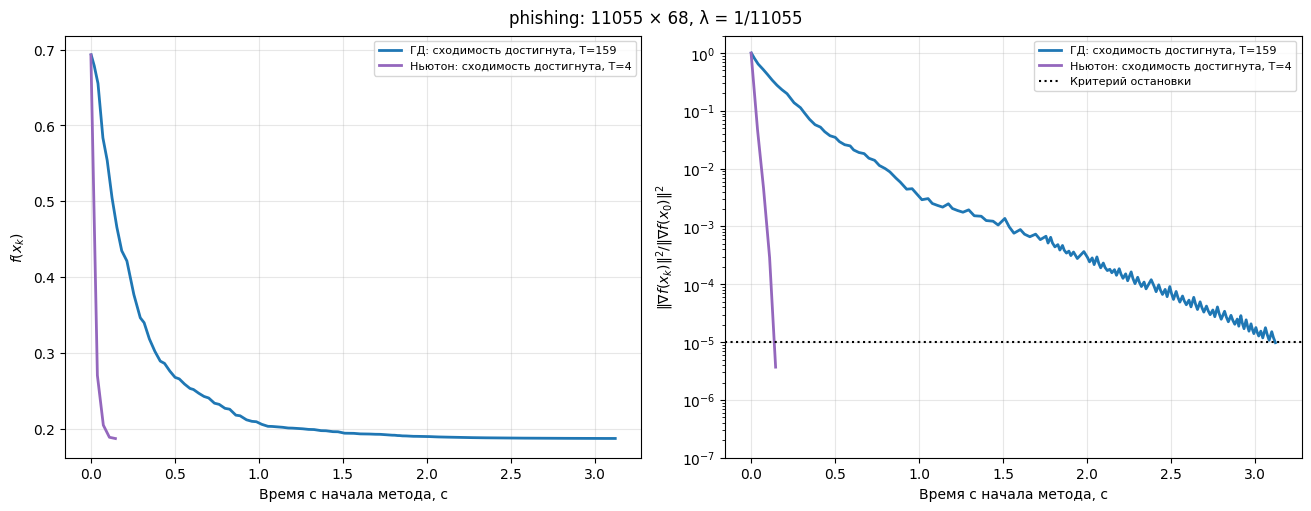

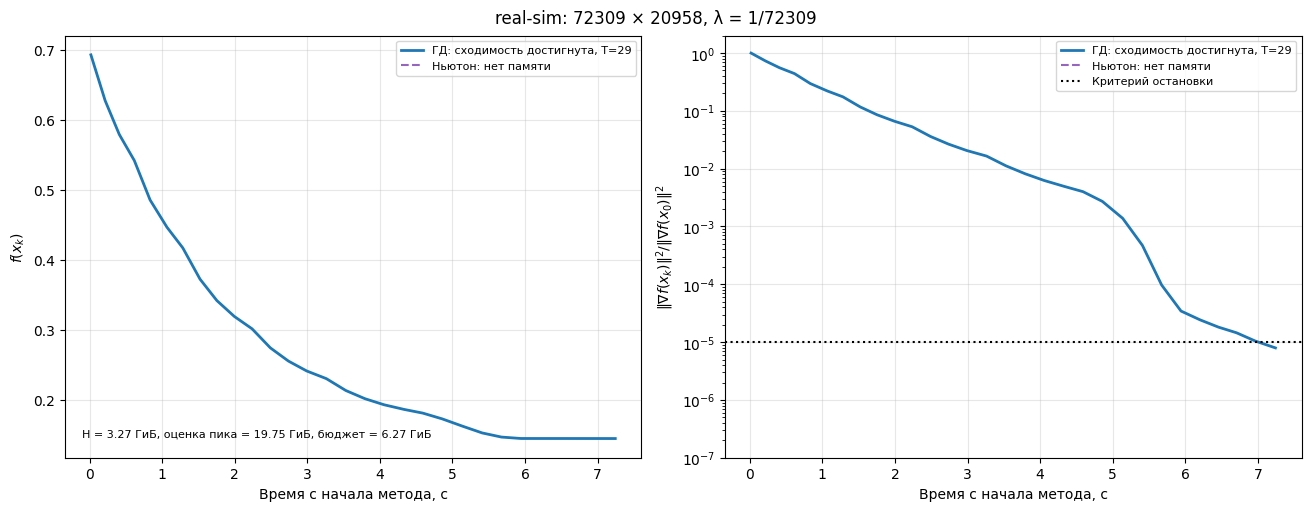

In [45]:
exp3_figures = {}
for dataset_name in exp3_datasets:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    for method_name, color in [('GD', 'tab:blue'), ('Newton', 'tab:purple')]:
        result = exp3_results[(dataset_name, method_name)]
        if result['history'] is None:
            for ax in axes:
                ax.plot([], [], color=color, linestyle='--', label=f'{method_name}: нет памяти')
            axes[0].text(0.03, 0.05, result['reason'], transform=axes[0].transAxes,
                         fontsize=8, wrap=True)
            continue
        history = result['history']
        label = f"{method_name}: {result['message']}, T={result['iterations']}"
        axes[0].plot(history['time'], history['func'], color=color, linewidth=2, label=label)
        ratio = experiment_relative_gradient(history)
        axes[1].semilogy(history['time'], np.maximum(ratio, np.finfo(float).tiny),
                         color=color, linewidth=2, label=label)
    default_tolerance = inspect.signature(gradient_descent).parameters['tolerance'].default
    axes[1].axhline(default_tolerance, color='black', linestyle=':', label='Критерий остановки')
    axes[0].set(xlabel='Время с начала метода, с', ylabel=r'$f(x_k)$')
    axes[1].set(xlabel='Время с начала метода, с',
                ylabel=r'$\|\nabla f(x_k)\|^2 / \|\nabla f(x_0)\|^2$',
                ylim=(default_tolerance * 0.01, 2))
    m, n = exp3_datasets[dataset_name][0].shape
    fig.suptitle(f'{dataset_name}: {m} × {n}, lambda = 1/{m}')
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    experiment_prepare_figure(fig)
    fig.savefig(experiment_output_dir / f'exp3_{dataset_name}.png', dpi=180)
    exp3_figures[dataset_name] = fig
    plt.show()
    plt.close(fig)


Эксперимент 3: Ваш ответ

**Данные и параметры эксперимента.**

Для регрессии использована Pseudo-Huber с $\delta=1$, для классификации —
Logistic Loss. Минимизируется
$$
f(x)=\frac1m\sum_{i=1}^m\ell(b_i,a_i^Tx)+\frac\lambda2\|x\|_2^2,
\qquad \lambda=\frac1m.
$$
Нормировка: $\ell(b,z)=\sqrt{1+(z-b)^2}$ для Pseudo-Huber
и $\ell(b,z)=\ln(1+e^{-bz})$ для логистической модели, $b\in\{-1,1\}$.

| Датасет | Потеря | $m$ | $n$ | Ненулевых элементов | Плотность |
|---|---|---:|---:|---:|---:|
| `mg_scale` | Pseudo-Huber | 1385 | 6 | 8310 | 100% |
| `triazines_scale` | Pseudo-Huber | 186 | 60 | 9982 | 89.4444% |
| `phishing` | Logistic | 11055 | 68 | 331650 | 44.1176% |
| `real-sim` | Logistic | 72309 | 20958 | 3709083 | 0.244751% |

Начальная точка $x_0=0$. Использованы параметры методов по умолчанию:
относительный квадрат нормы градиента не больше $10^{-5}$,
лимиты $10000$ итераций для GD и $100$ для Ньютона, поиск по Вульфу
с $c_1=10^{-4}$, $c_2=0.9$. При неудаче поиска Вульфа реализация
переходит к бэктрекингу Армихо; поэтому не каждый принятый шаг обязан
удовлетворять сильному условию Вульфа.

Среда сохранённого запуска: Google Colab, Linux, CPU `x86_64`,
2 логических процессора, около $12.7$ ГиБ RAM, NumPy 2.4.6,
SciPy 1.16.3. Для вычислений BLAS задан один поток.
Небольшие матрицы с высокой плотностью `mg_scale` и `triazines_scale`
хранятся как `ndarray`, остальные — как CSR.

**Результаты.**

| Датасет | Итерации GD | Итерации Ньютона | Время GD, с | Время Ньютона, с |
|---|---:|---:|---:|---:|
| `mg_scale` | 41 | 4 | 0.0230 | 0.0033 |
| `triazines_scale` | 224 | 3 | 0.0974 | 0.0030 |
| `phishing` | 159 | 4 | 2.1969 | 0.1515 |
| `real-sim` | 29 | Не запускался | 8.1277 | — |

Все семь выполненных запусков завершились успешно. На трёх задачах,
где запущены оба метода, Ньютон достигает заданной точности за меньшее
время. Его итерация при этом дороже: например, на `phishing` среднее
время итерации около $37.9$ мс против $13.8$ мс у GD.

Для `real-sim` один плотный гессиан занимает примерно $3.27$ ГиБ,
а оценка пикового потребления памяти — $19.75$ ГиБ при бюджете $6.70$ ГиБ.
Бюджет составляет 60% доступной оперативной памяти на момент проверки.
Запуск Ньютона пропущен после оценки памяти, со статусом `skipped_memory`.
Поэтому сравнить его фактическое время с GD на этом датасете нельзя.
Несмотря на предупреждения поиска Вульфа на `real-sim`, GD выполнил
заданный критерий остановки.

**0. Выпуклость целевой функции.**

У обеих потерь аналитические вторые производные по предсказанию неотрицательны:
$$
w_i=(1+(a_i^Tx-b_i)^2)^{-3/2}>0
$$
для Pseudo-Huber и
$$
w_i=p_i(1-p_i)>0,\qquad p_i=(1+e^{b_i a_i^Tx})^{-1}
$$
для Logistic. Поэтому
$$
H(x)=\frac1m A^T\operatorname{Diag}(w)A+\lambda I\succeq\lambda I.
$$
При $\lambda>0$ функции сильно выпуклы и имеют единственный минимум.
Численная реализация использует устойчивые вычисления потерь и производных.

**1. Влияние регуляризации.**

Регуляризация добавляет положительную кривизну во всех направлениях.
Она обеспечивает нижнюю границу $\mu\geq\lambda$ и уменьшает влияние
почти плоских направлений. При фиксированной точке добавление $\lambda I$
сдвигает спектр в положительную сторону и улучшает обусловленность.
Это помогает GD, но одновременно меняет саму задачу и её решение.

Графики показывают сходимость к стационарной точке; для этих сильно
выпуклых функций это минимум. Поскольку внутри одного датасета
$\lambda$ не меняется, по этим графикам нельзя отдельно измерить
влияние регуляризации. Такое сравнение выполнено
в эксперименте 6.

**2. Стоимость итерации и память.**

Обозначим $s=\operatorname{nnz}(A)$, а через $r_i$ — число ненулевых
элементов в строке $i$. Для плотной матрицы вычисление функции и градиента
требует $O(mn)$ операций; для CSR — $O(s+m+n)$.
Память GD без учёта сохранённой истории составляет $O(mn+m+n)$
для плотного входа и $O(s+m+n)$ для CSR.

Формирование плотного гессиана требует $O(mn^2)$ операций.
Для разреженной матрицы затраты на формирование гессиана можно оценить
по вкладам строк:
$O(m+s+\sum_i r_i^2+n^2)$, включая перевод результата в плотную матрицу.
Затем разложение Холецкого требует $O(n^3)$ операций, а треугольные решения — $O(n^2)$.
Память Ньютона составляет $O(mn+m+n^2)$ для плотного входа
или $O(s+m+n^2)$ для CSR. Разреженность входа не гарантирует
разреженность гессиана; наша реализация хранит его плотно.
Эти оценки — дополнительный разбор операций конкретного оракула.

Поиск шага добавляет вызовы функции и иногда градиента.
В текущей реализации произведения с $A$ при таких вызовах вычисляются заново,
поэтому фактическая стоимость итерации зависит и от числа пробных шагов.

**3. Когда выгоден каждый метод.**

При большом $m$ и небольшом $n$ полный гессиан сравнительно мал.
На `mg_scale` и `phishing` затраты на него окупились сокращением числа шагов.
На `triazines_scale`, где $m$ и $n$ ближе по порядку, Ньютон также оказался быстрее.

При большом $n$ метод ограничивают затраты памяти $O(n^2)$ и
факторизация за $O(n^3)$. `real-sim` показывает эту проблему, хотя число объектов
в нём тоже больше числа признаков. GD работает с разреженными произведениями
и в этом запуске укладывается в доступные ресурсы.

**4. Различия между потерями.**

У Pseudo-Huber вес кривизны мал при большой невязке, а у Logistic —
при большом по модулю отступе. Поэтому по мере движения по-разному меняется
гессиан и допустимая длина шага. Для Logistic глобальная верхняя граница
равна $L\leq\lambda+\|A\|_2^2/(4m)$, для Pseudo-Huber с $\delta=1$ —
$L\leq\lambda+\|A\|_2^2/m$.

В выполненных запусках Ньютону потребовалось 3–4 итерации, GD — 29–224.
Эти числа зависят также от матрицы признаков, масштаба данных и критерия
остановки. Поскольку датасеты для двух потерь различаются, разницу
нельзя объяснять только выбором потери. Абсолютные значения функций
на разных датасетах и для разных потерь напрямую не сравниваются.

## Эксперимент 4. Стратегия выбора длины шага в градиентном спуске

Исследуйте, как поведение градиентного спуска зависит от стратегии выбора шага:
* константный шаг (несколько значений);
* бэктрекинг по Армихо (несколько значений $c_1$);
* сильные условия Вульфа (несколько значений $c_2$);
* точный одномерный поиск: метод Брента и метод золотого сечения.

Рассмотрите квадратичную функцию и **обе ML-модели вашего варианта** на модельных (случайно сгенерированных) данных. Запустите градиентный спуск с разными стратегиями из одной и той же начальной точки и постройте кривые сходимости на одном графике:
* для квадратичной функции — относительная невязка по функции $(f(x_k) - f^*)/(f(x_0) - f^*)$ в логарифмической шкале от числа итераций;
* для ML-моделей — относительный квадрат нормы градиента в логарифмической шкале от числа итераций.

Повторите для нескольких начальных точек. Помимо числа итераций, сравните стратегии по числу вызовов оракула и по реальному времени.

### Вопросы для отчёта
1. Какая стратегия выбора шага лучше всего и по какому критерию (итерации, вызовы оракула, время)?
2. Насколько сильно константный шаг чувствителен к своему значению? Что происходит при слишком большом шаге?
3. Окупается ли точный одномерный поиск по сравнению с неточным?

In [46]:
exp4_rng = np.random.default_rng(np.random.SeedSequence([SEED, 4]))
exp4_n, exp4_m = 20, 200
exp4_tolerance = 1e-8
exp4_max_iter = 5000
exp4_regcoef = 1.0 / exp4_m
exp4_delta = 1.0

Q, _ = np.linalg.qr(exp4_rng.normal(size=(exp4_n, exp4_n)))
exp4_A_quad = (Q * np.geomspace(1.0, 100.0, exp4_n)) @ Q.T
exp4_b_quad = exp4_rng.normal(size=exp4_n)
exp4_quad = QuadraticOracle(exp4_A_quad, exp4_b_quad)
exp4_x_star = np.linalg.solve(exp4_A_quad, exp4_b_quad)
exp4_f_star = -0.5 * np.dot(exp4_b_quad, exp4_x_star)

exp4_A_ml = exp4_rng.normal(size=(exp4_m, exp4_n)) * np.geomspace(1.0, 5.0, exp4_n)
exp4_true_x = exp4_rng.normal(size=exp4_n) / np.sqrt(exp4_n)
exp4_b_reg = exp4_A_ml @ exp4_true_x + 0.2 * exp4_rng.normal(size=exp4_m)
exp4_margins = exp4_A_ml @ exp4_true_x + 0.5 * exp4_rng.normal(size=exp4_m)
exp4_b_cls = np.where(exp4_margins >= 0, 1.0, -1.0)
exp4_spectral_sq = np.linalg.norm(exp4_A_ml, ord=2) ** 2
exp4_problems = {
    'quadratic': {
        'oracle': exp4_quad, 'L': float(np.linalg.eigvalsh(exp4_A_quad)[-1]),
        'fingerprint': experiment_fingerprint(exp4_A_quad, exp4_b_quad),
    },
    'pseudohuber': {
        'oracle': create_linear_model_oracle(
            exp4_A_ml, exp4_b_reg, exp4_regcoef, PseudoHuberLoss(delta=exp4_delta)),
        'L': float(exp4_spectral_sq / (exp4_m * exp4_delta ** 2) + exp4_regcoef),
        'fingerprint': experiment_fingerprint(exp4_A_ml, exp4_b_reg),
    },
    'logistic': {
        'oracle': create_linear_model_oracle(exp4_A_ml, exp4_b_cls, exp4_regcoef, 'logistic'),
        'L': float(exp4_spectral_sq / (4 * exp4_m) + exp4_regcoef),
        'fingerprint': experiment_fingerprint(exp4_A_ml, exp4_b_cls),
    },
}
exp4_starts = {
    'zero': np.zeros(exp4_n),
    'ones': np.ones(exp4_n),
    'random': 3.0 * exp4_rng.normal(size=exp4_n),
}


def exp4_strategies(L):
    options = {
        f'Constant {coefficient:g}/L': {'method': 'Constant', 'c': coefficient / L}
        for coefficient in [0.5, 1.0, 1.8, 3.0]
    }
    options.update({
        f'Armijo c1={c1:g}': {'method': 'Armijo', 'c1': c1, 'alpha_0': 1.0}
        for c1 in [1e-4, 0.1, 0.4]
    })
    options.update({
        f'Wolfe c2={c2:g}': {'method': 'Wolfe', 'c1': 1e-4, 'c2': c2, 'alpha_0': 1.0}
        for c2 in [0.1, 0.5, 0.9]
    })
    options['Brent'] = {'method': 'Brent', 'tol': 1e-5}
    options['Golden'] = {'method': 'Golden', 'tol': 1e-5}
    return options


for name, problem in exp4_problems.items():
    print(f'{name}: n = {exp4_n}, L (верхняя оценка) = {problem["L"]:.6g}')
print('Для ML: m =', exp4_m, ', lambda =', exp4_regcoef)


quadratic: n = 20, L (верхняя оценка) = 100
pseudohuber: n = 20, L (верхняя оценка) = 25.9872
logistic: n = 20, L (верхняя оценка) = 6.50055
Для ML: m = 200 , lambda = 0.005


In [47]:
exp4_results = {}
exp4_table = []
for problem_name, problem in exp4_problems.items():
    for start_name, x_0 in exp4_starts.items():
        for strategy_name, options in exp4_strategies(problem['L']).items():
            result = experiment_run(
                'exp4', problem['oracle'], x_0, gradient_descent,
                problem={'name': problem_name, 'fingerprint': problem['fingerprint'],
                         'seed': SEED, 'regcoef': exp4_regcoef if problem_name != 'quadratic' else 0.0,
                         'delta': exp4_delta if problem_name == 'pseudohuber' else None},
                tolerance=exp4_tolerance, max_iter=exp4_max_iter,
                line_search_options=options,
            )
            exp4_results[(problem_name, start_name, strategy_name)] = result
            history = result['history']
            if problem_name == 'quadratic':
                denominator = problem['oracle'].func(x_0) - exp4_f_star
                residual = (np.asarray(history['func']) - exp4_f_star) / denominator
            else:
                residual = experiment_relative_gradient(history)
            row = {
                'problem': problem_name, 'start': start_name, 'strategy': strategy_name,
                'status': result['message'], 'iterations': result['iterations'],
                'seconds': result['elapsed'], 'oracle_calls': result['oracle_calls'],
                'func_calls': result['calls']['func'], 'grad_calls': result['calls']['grad'],
                'hess_calls': result['calls']['hess'],
                'func_directional_calls': result['calls']['func_directional'],
                'grad_directional_calls': result['calls']['grad_directional'],
                'final_residual': float(residual[-1]),
                'relative_grad_sq': float(experiment_relative_gradient(history)[-1]),
                'options': json.dumps(options, sort_keys=True),
            }
            exp4_table.append(row)
            print(f"{problem_name:<12} {start_name:<6} {strategy_name:<20} "
                  f"{result['message']:<22} T={result['iterations']:4d}, "
                  f"f/g/H={row['func_calls']}/{row['grad_calls']}/{row['hess_calls']}, "
                  f"t={result['elapsed']:.4f} с", flush=True)
experiment_save_table('exp4_step_strategies.csv', exp4_table)

experiment_show_table(exp4_table, index=['problem', 'strategy'], columns='start', values=['iterations', 'seconds', 'oracle_calls', 'status'])


quadratic    zero   Constant 0.5/L       success                T=1595, f/g/H=1596/1596/0, t=0.0394 с
quadratic    zero   Constant 1/L         success                T= 796, f/g/H=797/797/0, t=0.0201 с
quadratic    zero   Constant 1.8/L       success                T= 441, f/g/H=442/442/0, t=0.0114 с
quadratic    zero   Constant 3/L         computational_error    T= 512, f/g/H=514/514/0, t=0.0126 с
quadratic    zero   Armijo c1=0.0001     success                T= 366, f/g/H=1470/733/0, t=0.0475 с
quadratic    zero   Armijo c1=0.1        success                T= 367, f/g/H=1474/735/0, t=0.0238 с
quadratic    zero   Armijo c1=0.4        success                T= 363, f/g/H=1458/727/0, t=0.0237 с
quadratic    zero   Wolfe c2=0.1         success                T= 294, f/g/H=2209/1471/0, t=0.0491 с
quadratic    zero   Wolfe c2=0.5         success                T= 294, f/g/H=2209/1471/0, t=0.0500 с
quadratic    zero   Wolfe c2=0.9         success                T= 294, f/g/H=2209/1471/0, 

iterations                seconds            \
start                              zero  ones random      zero      ones   
problem     strategy                                                       
quadratic   Constant 0.5/L         1595   920    761  0.039402  0.024069   
            Constant 1/L            796   459    380  0.020078  0.011907   
            Constant 1.8/L          441   254    210  0.011418  0.006604   
            Constant 3/L            512   509    505  0.012603  0.013167   
            Armijo c1=0.0001        366   224    187  0.047512  0.014528   
            Armijo c1=0.1           367   217    187  0.023800  0.014231   
            Armijo c1=0.4           363   213    179  0.023701  0.013753   
            Wolfe c2=0.1            294   246    167  0.049102  0.041784   
            Wolfe c2=0.5            294   136    152  0.050004  0.022378   
            Wolfe c2=0.9            294   210    147  0.046447  0.033628   
            Brent                   342   243    207  0.060846  0.034596   
            Golden                  342   243    207  0.119261  0.089884   
pseudohuber Constant 0.5/L          375   625   1069  0.030798  0.042001   
            Constant 1/L            186   311    533  0.012723  0.040594   
            Constant 1.8/L          102   172    295  0.007136  0.011806   
            Constant 3/L           5000  5000   5000  0.448163  0.575501   
            Armijo c1=0.0001         83   109    126  0.017112  0.022625   
            Armijo c1=0.1            81   107    126  0.016675  0.021982   
            Armijo c1=0.4            79   101    123  0.017099  0.020924   
            Wolfe c2=0.1             89    97     83  0.034588  0.039686   
            Wolfe c2=0.5             87    93    117  0.054694  0.033475   
            Wolfe c2=0.9             85   107    125  0.045512  0.043059   
            Brent                    93   121    135  0.096413  0.131529   
            Golden                   93   121    135  0.207477  0.163621   
logistic    Constant 0.5/L         4573  4068   5000  0.519550  0.511056   
            Constant 1/L           2285  2030   3317  0.125288  0.251839   
            Constant 1.8/L         1267  1123   1845  0.090120  0.143042   
            Constant 3/L            758   670   1108  0.042043  0.084286   
            Armijo c1=0.0001        239   193    278  0.042340  0.063908   
            Armijo c1=0.1           232   186    267  0.035294  0.062661   
            Armijo c1=0.4           228   191    248  0.037558  0.076219   
            Wolfe c2=0.1            221   171    246  0.074547  0.102318   
            Wolfe c2=0.5            192   165    168  0.102581  0.082286   
            Wolfe c2=0.9            200   170    189  0.047519  0.096970   
            Brent                   272   201    319  0.197226  0.139426   
            Golden                  272   201    319  0.433013  0.351404   

                                       oracle_calls                \
start                           random         zero   ones random   
problem     strategy                                                
quadratic   Constant 0.5/L    0.021511         3192   1842   1524   
            Constant 1/L      0.009775         1594    920    762   
            Constant 1.8/L    0.005268          884    510    422   
            Constant 3/L      0.032130         1028   1022   1014   
            Armijo c1=0.0001  0.012136         2203   1351   1129   
            Armijo c1=0.1     0.014026         2209   1309   1129   
            Armijo c1=0.4     0.011602         2185   1285   1081   
            Wolfe c2=0.1      0.026839         3680   3223   2122   
            Wolfe c2=0.5      0.023974         3680   1745   1909   
            Wolfe c2=0.9      0.028311         3680   2635   1856   
            Brent             0.030188         4411   2512   2072   
            Golden            0.074952        13681   9722   8284   
pseudohuber Constant 0.5/L   

iterations                seconds            \
start                              zero  ones random      zero      ones   
problem     strategy                                                       
quadratic   Constant 0.5/L         1595   920    761  0.039402  0.024069   
            Constant 1/L            796   459    380  0.020078  0.011907   
            Constant 1.8/L          441   254    210  0.011418  0.006604   
            Constant 3/L            512   509    505  0.012603  0.013167   
            Armijo c1=0.0001        366   224    187  0.047512  0.014528   
            Armijo c1=0.1           367   217    187  0.023800  0.014231   
            Armijo c1=0.4           363   213    179  0.023701  0.013753   
            Wolfe c2=0.1            294   246    167  0.049102  0.041784   
            Wolfe c2=0.5            294   136    152  0.050004  0.022378   
            Wolfe c2=0.9            294   210    147  0.046447  0.033628   
            Brent                   342   243    207  0.060846  0.034596   
            Golden                  342   243    207  0.119261  0.089884   
pseudohuber Constant 0.5/L          375   625   1069  0.030798  0.042001   
            Constant 1/L            186   311    533  0.012723  0.040594   
            Constant 1.8/L          102   172    295  0.007136  0.011806   
            Constant 3/L           5000  5000   5000  0.448163  0.575501   
            Armijo c1=0.0001         83   109    126  0.017112  0.022625   
            Armijo c1=0.1            81   107    126  0.016675  0.021982   
            Armijo c1=0.4            79   101    123  0.017099  0.020924   
            Wolfe c2=0.1             89    97     83  0.034588  0.039686   
            Wolfe c2=0.5             87    93    117  0.054694  0.033475   
            Wolfe c2=0.9             85   107    125  0.045512  0.043059   
            Brent                    93   121    135  0.096413  0.131529   
            Golden                   93   121    135  0.207477  0.163621   
logistic    Constant 0.5/L         4573  4068   5000  0.519550  0.511056   
            Constant 1/L           2285  2030   3317  0.125288  0.251839   
            Constant 1.8/L         1267  1123   1845  0.090120  0.143042   
            Constant 3/L            758   670   1108  0.042043  0.084286   
            Armijo c1=0.0001        239   193    278  0.042340  0.063908   
            Armijo c1=0.1           232   186    267  0.035294  0.062661   
            Armijo c1=0.4           228   191    248  0.037558  0.076219   
            Wolfe c2=0.1            221   171    246  0.074547  0.102318   
            Wolfe c2=0.5            192   165    168  0.102581  0.082286   
            Wolfe c2=0.9            200   170    189  0.047519  0.096970   
            Brent                   272   201    319  0.197226  0.139426   
            Golden                  272   201    319  0.433013  0.351404   

                                       oracle_calls                \
start                           random         zero   ones random   
problem     strategy                                                
quadratic   Constant 0.5/L    0.021511         3192   1842   1524   
            Constant 1/L      0.009775         1594    920    762   
            Constant 1.8/L    0.005268          884    510    422   
            Constant 3/L      0.032130         1028   1022   1014   
            Armijo c1=0.0001  0.012136         2203   1351   1129   
            Armijo c1=0.1     0.014026         2209   1309   1129   
            Armijo c1=0.4     0.011602         2185   1285   1081   
            Wolfe c2=0.1      0.026839         3680   3223   2122   
            Wolfe c2=0.5      0.023974         3680   1745   1909   
            Wolfe c2=0.9      0.028311         3680   2635   1856   
            Brent             0.030188         4411   2512   2072   
            Golden            0.074952        13681   9722   8284   
pseudohuber Constant 0.5/L   

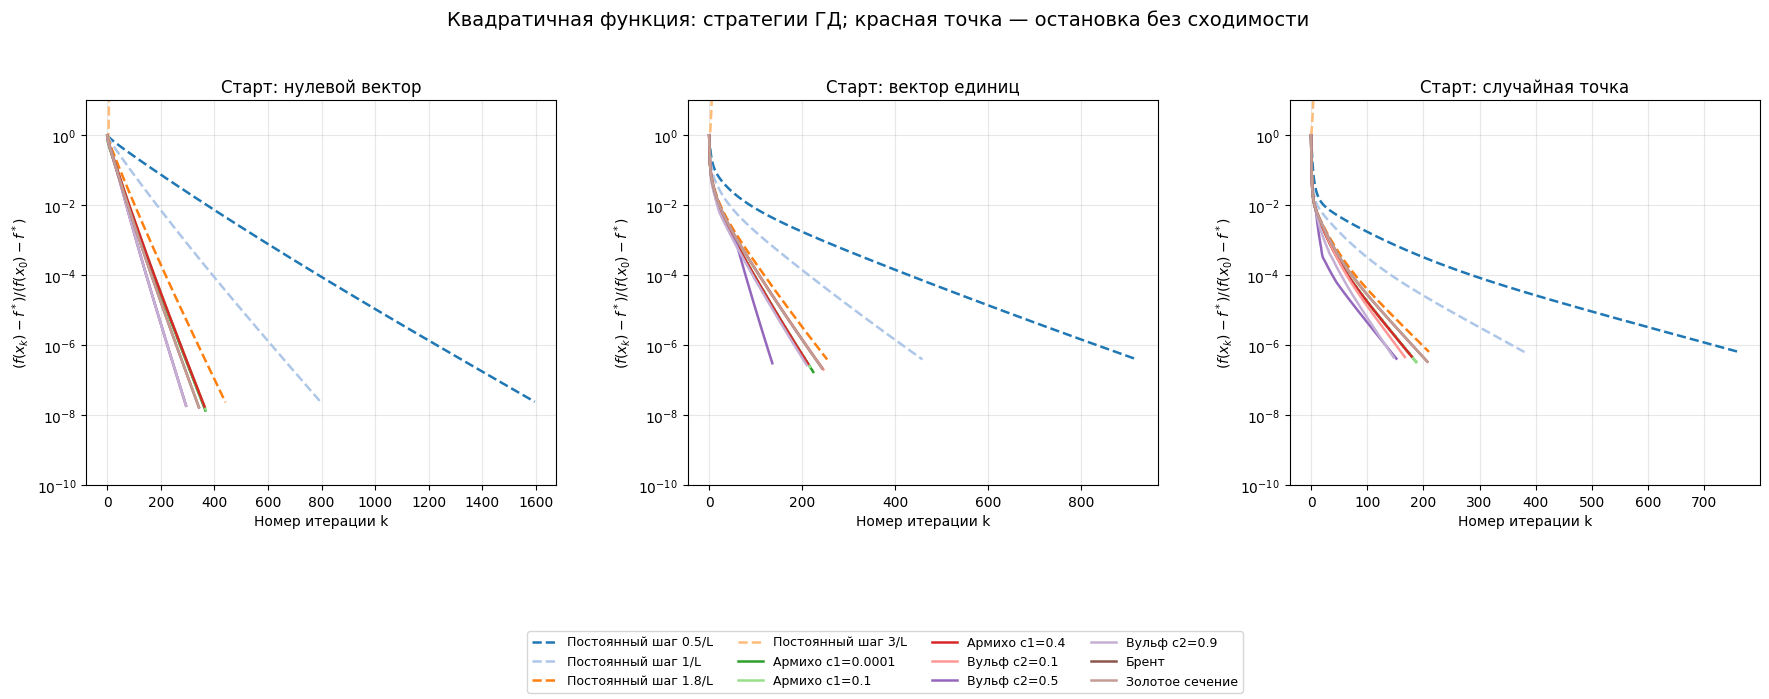

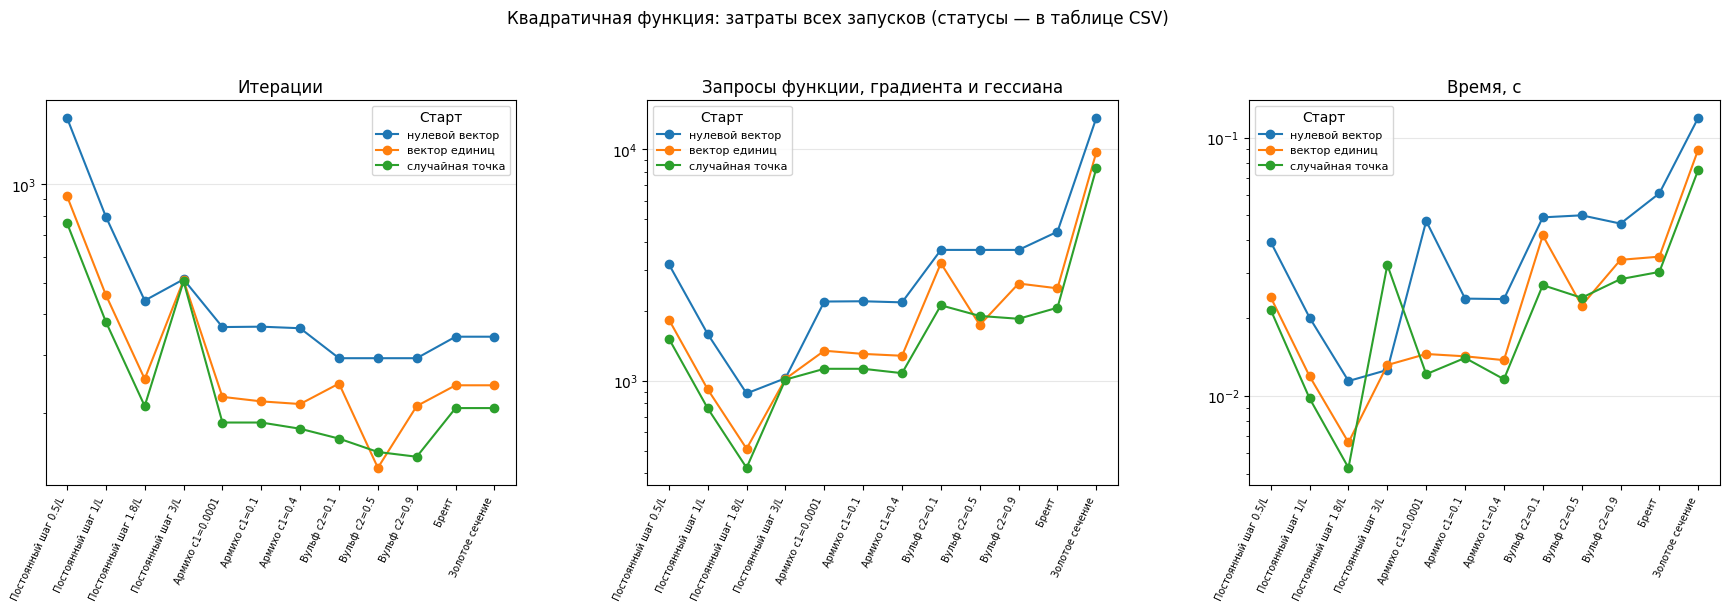

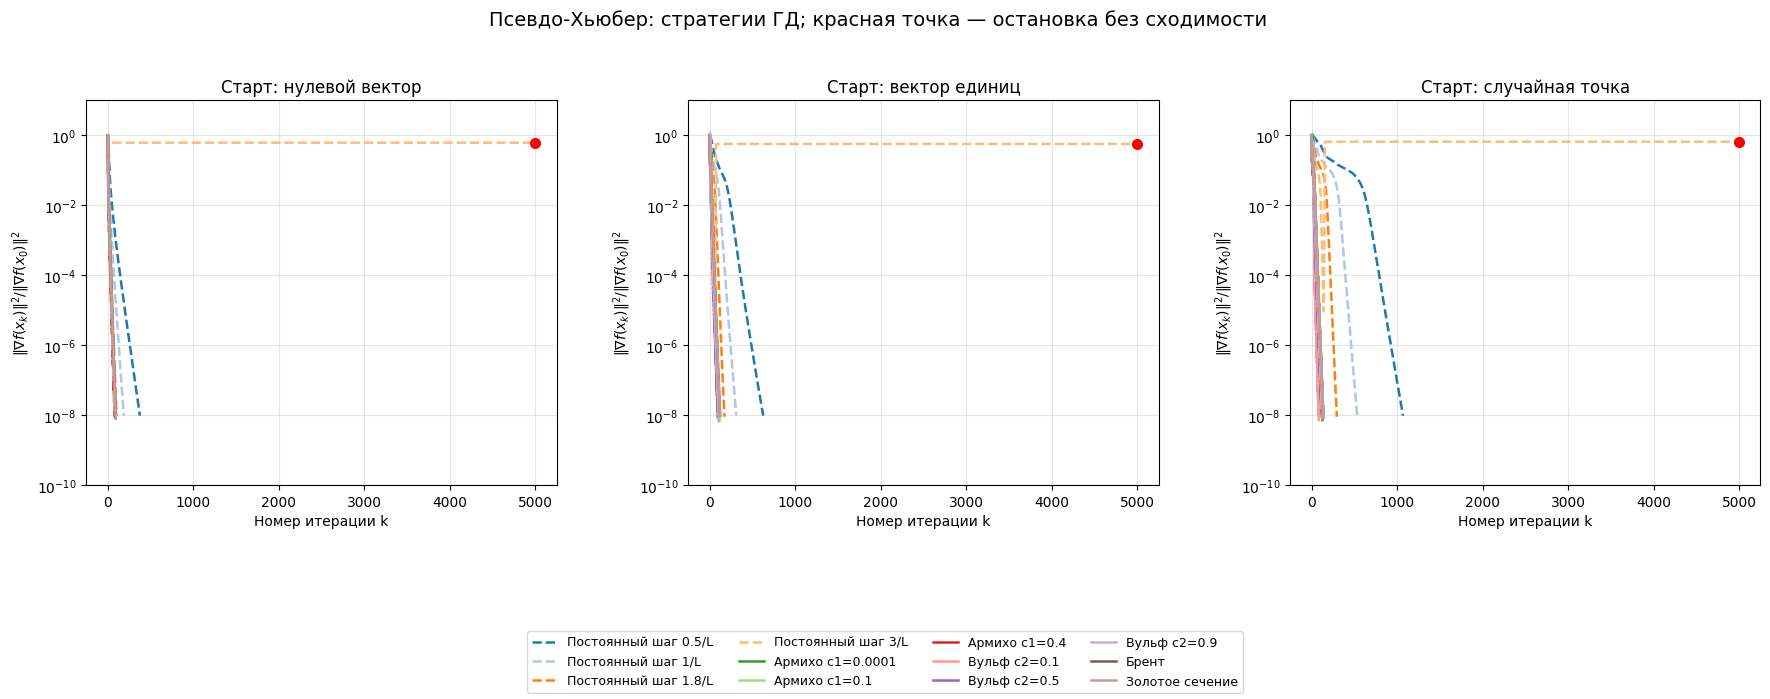

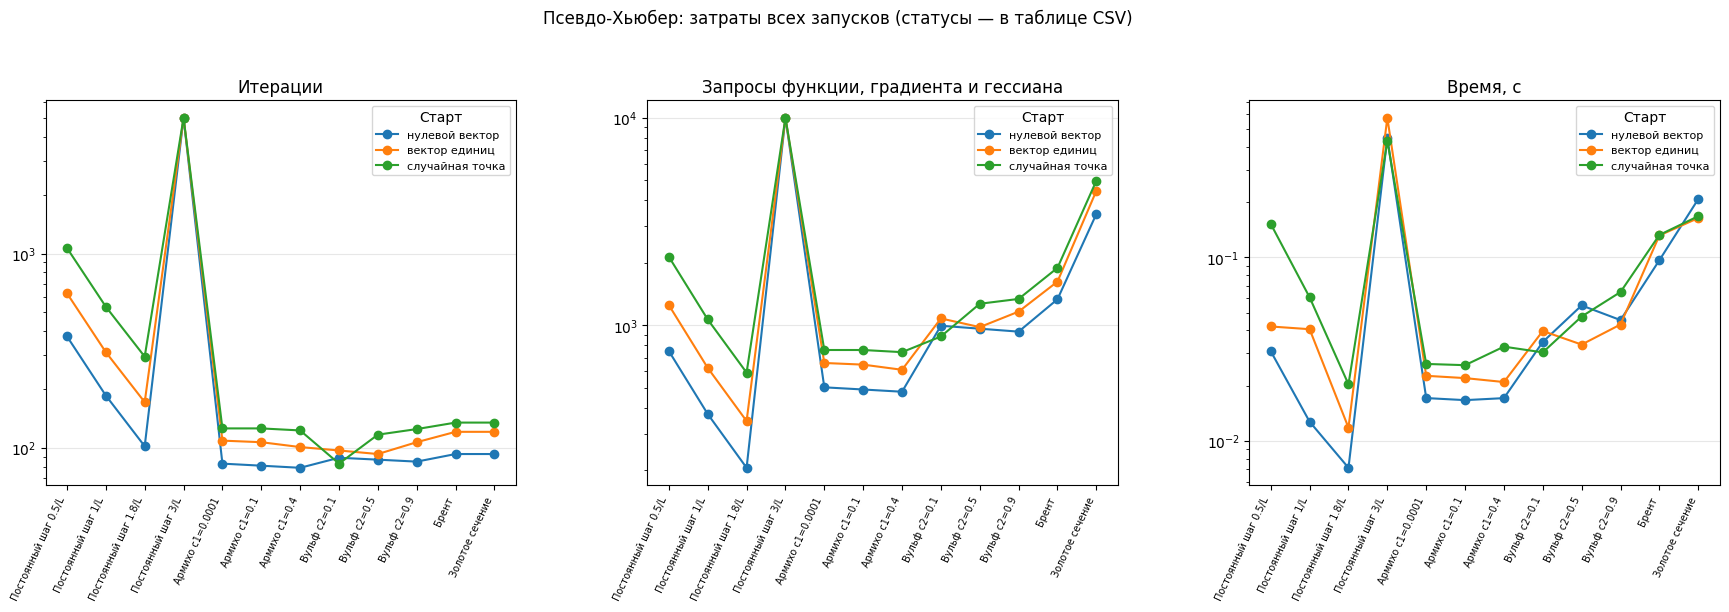

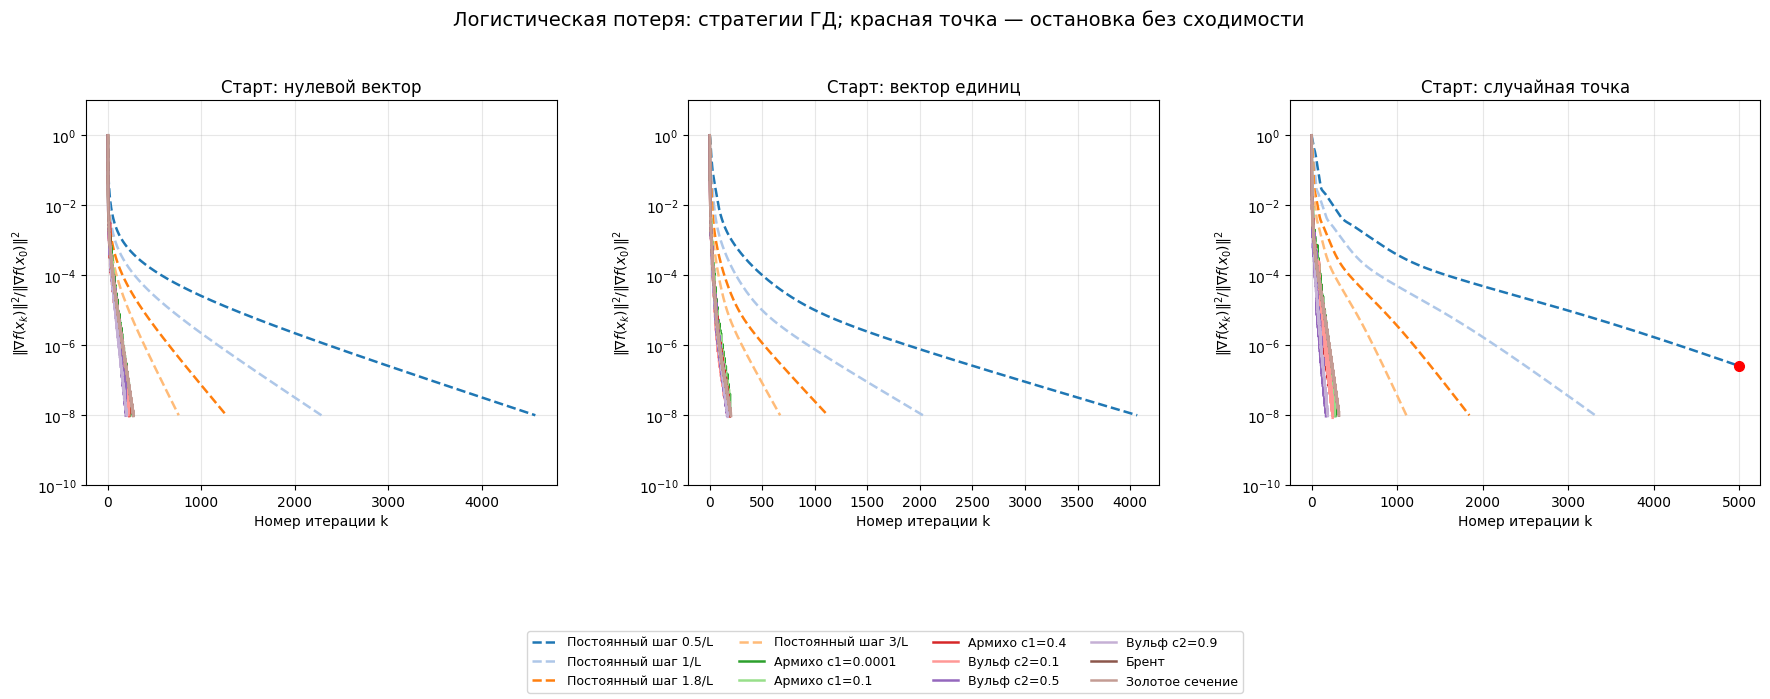

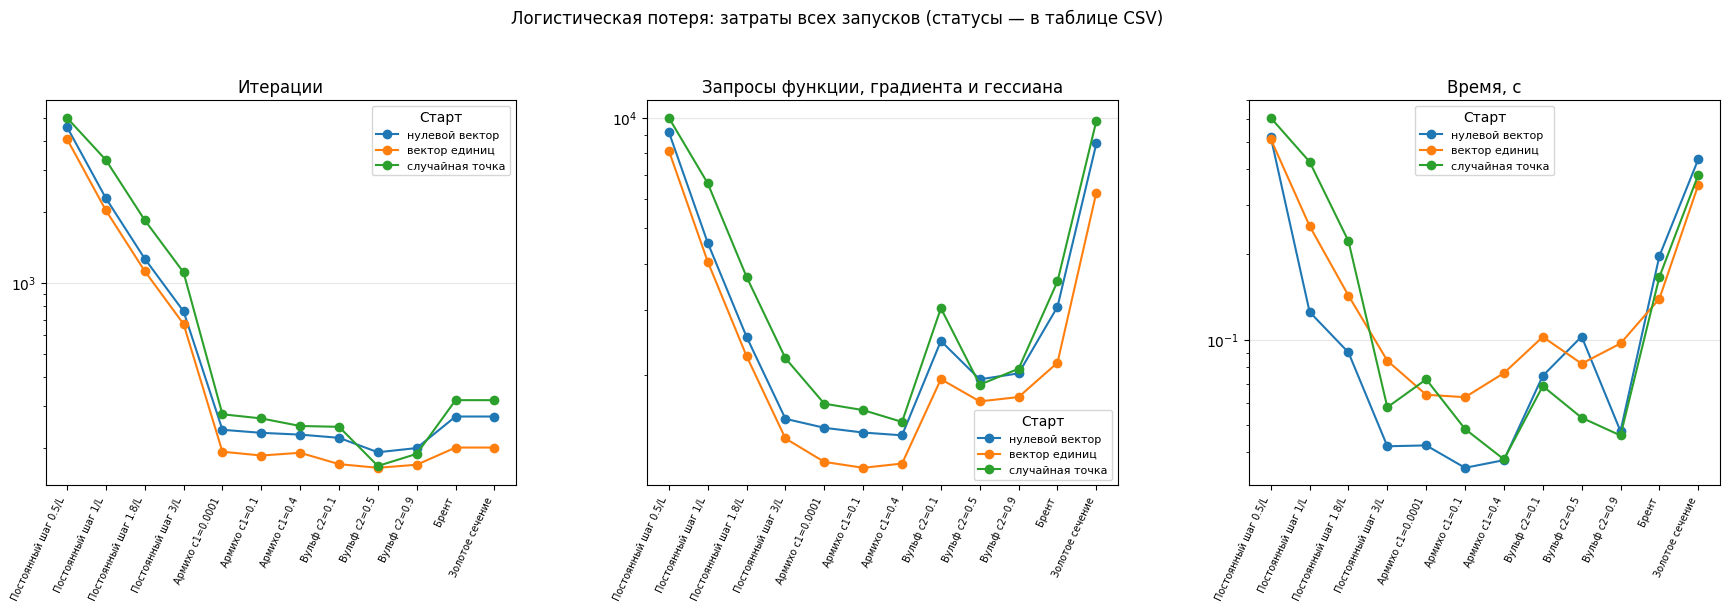

In [48]:
exp4_figures = {}
exp4_strategy_names = list(exp4_strategies(exp4_problems['quadratic']['L']))
exp4_colors = {name: plt.get_cmap('tab20')(i) for i, name in enumerate(exp4_strategy_names)}
for problem_name, problem in exp4_problems.items():
    fig, axes = plt.subplots(1, len(exp4_starts), figsize=(18, 7))
    fig.subplots_adjust(left=0.06, right=0.99, bottom=0.3, top=0.85, wspace=0.28)
    for ax, (start_name, x_0) in zip(axes, exp4_starts.items()):
        ax.set_yscale('log')
        ax.set_ylim(exp4_tolerance * 0.01, 10)
        for strategy_name in exp4_strategy_names:
            result = exp4_results[(problem_name, start_name, strategy_name)]
            history = result['history']
            if problem_name == 'quadratic':
                residual = (np.asarray(history['func']) - exp4_f_star) / (
                    problem['oracle'].func(x_0) - exp4_f_star)
            else:
                residual = experiment_relative_gradient(history)
            plotted = np.maximum(residual, np.finfo(float).tiny)
            ax.plot(np.arange(len(plotted)), plotted,
                         color=exp4_colors[strategy_name], linewidth=1.8,
                         linestyle='--' if strategy_name.startswith('Constant') else '-',
                         label=strategy_name)
            if result['message'] != 'success':
                ax.plot(len(plotted) - 1, plotted[-1], marker='o', markersize=7,
                         color='red')
        ax.set(title=f'Старт: {start_name}', xlabel='Номер итерации k',
               ylim=(exp4_tolerance * 0.01, 10))
        ax.set_ylabel(r'$(f(x_k)-f^*)/(f(x_0)-f^*)$' if problem_name == 'quadratic'
                      else r'$\|\nabla f(x_k)\|^2 / \|\nabla f(x_0)\|^2$')
        ax.grid(alpha=0.3)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=9)
    fig.suptitle(f'{problem_name}: стратегии ГД; красная точка — остановка без сходимости', fontsize=14)
    experiment_prepare_figure(fig)
    fig.savefig(experiment_output_dir / f'exp4_{problem_name}_convergence.png', dpi=180)
    exp4_figures[(problem_name, 'convergence')] = fig
    plt.show()
    plt.close(fig)

    cost_fig, cost_axes = plt.subplots(1, 3, figsize=(18, 7))
    cost_fig.subplots_adjust(left=0.06, right=0.99, bottom=0.3, top=0.85, wspace=0.28)
    for ax, metric, title in zip(
        cost_axes, ['iterations', 'oracle_calls', 'elapsed'],
        ['Итерации', 'Запросы функции, градиента и гессиана', 'Время, с'],
    ):
        for start_index, start_name in enumerate(exp4_starts):
            values = [exp4_results[(problem_name, start_name, name)][metric]
                      for name in exp4_strategy_names]
            ax.plot(np.arange(len(values)), np.maximum(values, np.finfo(float).tiny),
                     marker='o', linewidth=1.5, label=start_name)
        ax.set_yscale('log')
        ax.set_xticks(np.arange(len(exp4_strategy_names)), exp4_strategy_names,
                      rotation=65, ha='right', fontsize=7)
        ax.set_title(title)
        ax.grid(axis='y', alpha=0.3)
        ax.legend(title='Старт', fontsize=8)
    cost_fig.suptitle(f'{problem_name}: затраты всех запусков (статусы — в таблице CSV)')
    experiment_prepare_figure(cost_fig)
    cost_fig.savefig(experiment_output_dir / f'exp4_{problem_name}_costs.png', dpi=180)
    exp4_figures[(problem_name, 'costs')] = cost_fig
    plt.show()
    plt.close(cost_fig)


Эксперимент 4: Ваш ответ

**Данные и параметры эксперимента.**

Сравниваются стратегии выбора шага GD на квадратичной функции и двух ML-моделях.
У квадратичной задачи $n=20$, матрица положительно определена,
её собственные значения расположены по геометрической сетке от $1$ до $100$.
Собственные направления заданы случайной ортогональной матрицей, $b$ случаен.
Поэтому $\kappa=100$, $L=100$; минимум найден решением $Ax^*=b$.

Для ML использована общая модельная матрица $A\in\mathbb R^{200\times20}$:
нормально распределённые признаки умножены на коэффициенты от $1$ до $5$.
Регрессионные ответы получены из линейной модели с шумом масштаба $0.2$,
классы — по знаку линейной модели с шумом масштаба $0.5$.
Потери — Pseudo-Huber с $\delta=1$ и Logistic, $\lambda=1/200=0.005$.
Использованы `SEED = 42` и три общих старта: нулевой вектор,
вектор единиц и случайный вектор $3z$, где $z\sim N(0,I)$.

Для постоянного шага проверены $\alpha\in\{0.5/L,1/L,1.8/L,3/L\}$.
В Армихо меняется $c_1\in\{10^{-4},0.1,0.4\}$, в сильных условиях Вульфа —
$c_2\in\{0.1,0.5,0.9\}$ при $c_1=10^{-4}$.
В Армихо первый пробный шаг равен $1$, на следующих итерациях поиск
начинается с удвоенного предыдущего принятого шага; при неудаче шаг делится пополам.
Для Брента и золотого сечения задана точность одномерного поиска $10^{-5}$;
поэтому «точный поиск» здесь означает численное решение вспомогательной задачи
с этой точностью. Оценки $L$ равны $100$, примерно $25.9872$ и $6.50055$
для квадратичной функции, Pseudo-Huber и Logistic соответственно.

Лимит — $5000$ итераций, критерий остановки для всех задач:
$$
\frac{\|\nabla f(x_k)\|_2^2}{\|\nabla f(x_0)\|_2^2}\leq10^{-8}.
$$
На графике квадратичной задачи отображается относительная ошибка функции
$(f(x_k)-f^*)/(f(x_0)-f^*)$, а для ML — относительный квадрат нормы градиента.
Это разные величины; критерий остановки в коде остаётся градиентным.
Среда вычислений та же, что в эксперименте 3.

**Результаты.**

Из 108 запусков 101 завершился успешно, четыре достигли лимита итераций,
а три остановились с ошибкой вычислений. В таблице приведены результаты характерных стратегий из нулевого старта.
Вызовы оракула считаются как сумма запросов функции, градиента и гессиана;
для GD запросов гессиана нет. Пробные шаги входят в эти счётчики.

| Задача | Стратегия | Итерации | Вызовы оракула | Время, с |
|---|---|---|---|---|
| Квадратичная | $1/L$ | 796 | 1594 | 0.0436 |
| Квадратичная | $1.8/L$ | 441 | 884 | 0.0240 |
| Квадратичная | Армихо, $c_1=0.4$ | 363 | 2185 | 0.0572 |
| Квадратичная | Вульф, $c_2=0.5$ | 294 | 3680 | 0.0961 |
| Квадратичная | Брент | 342 | 4411 | 0.1335 |
| Квадратичная | Золотое сечение | 342 | 13681 | 0.2685 |
| Pseudo-Huber | $1/L$ | 186 | 374 | 0.0298 |
| Pseudo-Huber | $1.8/L$ | 102 | 206 | 0.0150 |
| Pseudo-Huber | Армихо, $c_1=0.4$ | 79 | 479 | 0.0180 |
| Pseudo-Huber | Вульф, $c_2=0.5$ | 87 | 964 | 0.0377 |
| Pseudo-Huber | Брент | 93 | 1336 | 0.1092 |
| Pseudo-Huber | Золотое сечение | 93 | 3440 | 0.1618 |
| Logistic | $1/L$ | 2285 | 4572 | 0.1242 |
| Logistic | $1.8/L$ | 1267 | 2536 | 0.0991 |
| Logistic | Армихо, $c_1=0.4$ | 228 | 1369 | 0.0692 |
| Logistic | Вульф, $c_2=0.5$ | 192 | 1944 | 0.0559 |
| Logistic | Брент | 272 | 3062 | 0.1705 |
| Logistic | Золотое сечение | 272 | 8515 | 0.3013 |

**1. Какая стратегия лучше.**

Единой лучшей стратегии по всем критериям не получилось.
На квадратичной задаче меньше всего итераций потребовал Вульф,
а меньше всего вызовов и времени — шаг $1.8/L$ во всех трёх стартах.
На Pseudo-Huber шаг $1.8/L$ также оказался самым дешёвым по вызовам
и времени, хотя по числу итераций уступал некоторым адаптивным стратегиям.

На Logistic по числу итераций во всех стартах выиграл Вульф с $c_2=0.5$:
192, 165 и 168 шагов. По вызовам оракула выгоднее оказался Армихо
с $c_1=0.1$ или $0.4$, в зависимости от старта. По времени среди
исследованных стратегий также выигрывали варианты Армихо.
Меньшее число внешних итераций может сочетаться с более дорогим
поиском шага. Небольшие различия времени относятся
к сохранённому запуску; универсальный рейтинг параметров из них не следует.

**2. Чувствительность постоянного шага.**

Для квадратичной задачи ошибка в собственном направлении умножается на
$1-\alpha\lambda_j$. Сходимость из произвольного старта обеспечивается при
$$
0<\alpha<\frac2{\lambda_{\max}(A)}=\frac2L.
$$
При $\alpha=3/L$ множитель вдоль самого крутого направления равен $-2$,
и ошибка растёт. Все три таких запуска закончились ошибкой вычислений
после 505–512 итераций. Уменьшение шага до $0.5/L$ даёт устойчивое,
но более медленное движение.

На Pseudo-Huber метод с шагом $3/L$ не выполнил критерий за $5000$ итераций
ни из одного старта. На Logistic этот шаг, напротив, оказался успешным
во всех стартах. Для нелинейной функции использованная глобальная оценка
$L$ может быть завышена относительно кривизны вдоль траектории;
выход за достаточную границу $2/L$ ещё не означает обязательную расходимость.
Слишком малый шаг тоже может не уложиться в лимит: Logistic из случайного
старта с $0.5/L$ остановился на $5000$ итерациях.

**3. Окупается ли точный одномерный поиск.**

В этих запусках Брент и золотое сечение не дали общего преимущества
перед неточным поиском. Например, на квадратичной задаче из нуля
оба потребовали 342 итерации, тогда как Вульф — 294.
При одинаковом числе внешних шагов золотое сечение запросило функцию
существенно чаще, чем Брент. Аналогичная разница видна на обеих ML-моделях.

Одномерная минимизация улучшает функцию вдоль текущего антиградиента,
но не устраняет плохую обусловленность многомерной задачи.
Поэтому затраты на высокую точность каждой одномерной минимизации
могут не окупаться. Армихо ограничивается достаточным уменьшением,
а Вульф дополнительно контролирует изменение наклона вдоль направления.
В этом эксперименте более дешёвый неточный поиск оказался полезнее.



## Эксперимент 5. Стратегия выбора длины шага в методе Ньютона

Повторите эксперимент 4 для метода Ньютона на ML-моделях вашего варианта (модельные данные).

Дополнительно для каждой стратегии зафиксируйте номер итерации, начиная с которой шаг $\alpha = 1$ принимается всегда, т. е. момент входа в зону квадратичной сходимости. Как ведёт себя $\|\nabla f(x_k)\|$ после этого момента? Проверьте численно, что $\|\nabla f(x_{k+1})\| \approx C \|\nabla f(x_k)\|^2$.

### Вопросы для отчёта
1. Какая стратегия работает лучше всего?
2. Почему для метода Ньютона единичный шаг является приоритетным?
3. На какой итерации метод входит в зону квадратичной сходимости и как это видно на графиках?

In [49]:
class ExperimentStepRecorder(LineSearchTool):
    def __init__(self, **options):
        super().__init__(**options)
        self.alphas = []

    def line_search(self, oracle, x_k, d_k, previous_alpha=None):
        alpha = super().line_search(oracle, x_k, d_k, previous_alpha)
        self.alphas.append(np.nan if alpha is None else float(alpha))
        return alpha


class ExperimentNewtonObserver(BaseSmoothOracle):
    """Спектр вычисляем по уже полученному H, не меняя направления и шаги."""
    def __init__(self, oracle, spectrum_every=0):
        self.oracle = oracle
        self.spectrum_every = spectrum_every
        self.hessian_iteration = 0
        self.samples = []

    def func(self, x):
        return self.oracle.func(x)

    def grad(self, x):
        return self.oracle.grad(x)

    def func_directional(self, x, d, alpha):
        return self.oracle.func_directional(x, d, alpha)

    def grad_directional(self, x, d, alpha):
        return self.oracle.grad_directional(x, d, alpha)

    def record_spectrum(self, iteration, x, hessian):
        started = time.perf_counter()
        matrix = hessian.toarray() if scipy.sparse.issparse(hessian) else hessian
        spectrum = scipy.linalg.eigvalsh(matrix)
        elapsed = time.perf_counter() - started
        self.samples.append((iteration, x.copy(), spectrum, elapsed))

    def hess(self, x):
        hessian = self.oracle.hess(x)
        if self.spectrum_every and self.hessian_iteration % self.spectrum_every == 0:
            self.record_spectrum(self.hessian_iteration, x, hessian)
        self.hessian_iteration += 1
        return hessian


def experiment_observed_newton(oracle, x_0, tolerance=1e-5, max_iter=100,
                               line_search_options=None, trace=False, display=False,
                               spectrum_every=0):
    tool = ExperimentStepRecorder(**(line_search_options or {'method': 'Wolfe'}))
    observer = ExperimentNewtonObserver(oracle, spectrum_every)
    x_opt, message, history = newton(
        observer, x_0, tolerance=tolerance, max_iter=max_iter,
        line_search_options=tool, trace=trace, display=display,
    )
    if trace:
        iterations = max(0, len(history['func']) - 1)
        history['alpha'] = np.asarray(tool.alphas[:iterations])
        history['attempted_alpha'] = np.asarray(tool.alphas)
        if spectrum_every:
            if not observer.samples or not np.array_equal(observer.samples[-1][1], x_opt):
                observer.record_spectrum(iterations, x_opt, oracle.hess(x_opt))
            history['spectrum_iter'] = np.array([s[0] for s in observer.samples], dtype=int)
            history['spectrum_x'] = np.array([s[1] for s in observer.samples])
            history['spectrum_values'] = np.array([s[2] for s in observer.samples])
            history['spectrum_seconds'] = np.array([s[3] for s in observer.samples])
    return x_opt, message, history


def experiment_newton_diagnostics(result):
    norms = np.asarray(result['history']['grad_norm'])
    alphas = np.asarray(result['history']['alpha'])
    unit = np.isclose(alphas, 1.0, rtol=1e-7, atol=1e-10)
    suffix_start = None
    if result['message'] == 'success' and len(unit) and unit[-1]:
        nonunit = np.flatnonzero(~unit)
        suffix_start = int(nonunit[-1] + 1) if len(nonunit) else 0
    noise_floor = 100 * np.finfo(float).eps * max(1.0, norms[0])
    C = np.full(len(alphas), np.nan)
    valid = ((norms[:-1] > np.sqrt(np.finfo(float).eps) * max(1.0, norms[0]))
             & (norms[1:] > noise_floor))
    C[valid] = norms[1:][valid] / norms[:-1][valid] / norms[:-1][valid]
    local = valid & unit & (norms[:-1] <= 0.1) & (norms[1:] < norms[:-1])
    orders = []
    for k in range(1, len(alphas)):
        if (unit[k - 1] and unit[k] and valid[k - 1] and valid[k]
                and norms[k - 1] <= 0.1
                and 0 < norms[k + 1] < norms[k] < norms[k - 1]):
            orders.append(np.log(norms[k + 1] / norms[k])
                          / np.log(norms[k] / norms[k - 1]))
    return {'unit_step_start': suffix_start, 'C': C, 'local': local,
            'local_C_median': float(np.median(C[local])) if np.any(local) else None,
            'local_pairs': int(np.count_nonzero(local)),
            'observed_orders': np.asarray(orders)}


exp5_tolerance = 1e-16
exp5_max_iter = 1000
exp5_strategies = {
    f'Constant {step:g}': {'method': 'Constant', 'c': step}
    for step in [0.25, 0.5, 1.0, 1.5]
}
exp5_strategies.update({name: options for name, options in exp4_strategies(1.0).items()
                        if not name.startswith('Constant')})
exp5_problems = {name: exp4_problems[name] for name in ['pseudohuber', 'logistic']}
exp5_starts = {name: point.copy() for name, point in exp4_starts.items()}


In [50]:
exp5_results, exp5_diagnostics, exp5_table = {}, {}, []
for problem_name, problem in exp5_problems.items():
    for start_name, x_0 in exp5_starts.items():
        for strategy_name, options in exp5_strategies.items():
            key = (problem_name, start_name, strategy_name)
            result = experiment_run(
                'exp5', problem['oracle'], x_0, experiment_observed_newton,
                problem={'name': problem_name, 'fingerprint': problem['fingerprint'],
                         'regcoef': exp4_regcoef,
                         'delta': exp4_delta if problem_name == 'pseudohuber' else None},
                tolerance=exp5_tolerance, max_iter=exp5_max_iter,
                line_search_options=options,
            )
            diagnostic = experiment_newton_diagnostics(result)
            exp5_results[key], exp5_diagnostics[key] = result, diagnostic
            exp5_table.append({
                'problem': problem_name, 'start': start_name, 'strategy': strategy_name,
                'status': result['message'], 'iterations': result['iterations'],
                'seconds': result['elapsed'], 'oracle_calls': result['oracle_calls'],
                'func_calls': result['calls']['func'], 'grad_calls': result['calls']['grad'],
                'hess_calls': result['calls']['hess'],
                'unit_step_start': diagnostic['unit_step_start'],
                'local_quadratic_pairs': diagnostic['local_pairs'],
                'local_C_median': diagnostic['local_C_median'],
                'observed_orders': json.dumps(diagnostic['observed_orders'].tolist()),
                'final_grad_norm': float(result['history']['grad_norm'][-1]),
                'relative_grad_sq': float(experiment_relative_gradient(result['history'])[-1]),
                'options': json.dumps(options, sort_keys=True),
            })
            print(f"{problem_name:<12} {start_name:<6} {strategy_name:<20} "
                  f"{result['message']:<22} T={result['iterations']:4d}, "
                  f"unit_start={diagnostic['unit_step_start']}, "
                  f"C={diagnostic['local_C_median']}, t={result['elapsed']:.4f} с", flush=True)
experiment_save_table('exp5_newton_strategies.csv', exp5_table)
print('unit_step_start — начало конечного непрерывного участка шагов alpha≈1, k с нуля.')
print('Это отдельный признак: квадратичную сходимость оцениваем также по C_k и порядку p.')

experiment_show_table(exp5_table, index=['problem', 'strategy'], columns='start', values=['iterations', 'unit_step_start', 'local_C_median', 'status'])


pseudohuber  zero   Constant 0.25        iterations_exceeded    T=1000, unit_start=None, C=None, t=0.1898 с
pseudohuber  zero   Constant 0.5         iterations_exceeded    T=1000, unit_start=None, C=None, t=0.1670 с
pseudohuber  zero   Constant 1           iterations_exceeded    T=1000, unit_start=None, C=None, t=0.1683 с
pseudohuber  zero   Constant 1.5         iterations_exceeded    T=1000, unit_start=None, C=None, t=0.1681 с
pseudohuber  zero   Armijo c1=0.0001     success                T=   4, unit_start=1, C=0.051468661792908925, t=0.0016 с
pseudohuber  zero   Armijo c1=0.1        success                T=   4, unit_start=1, C=0.051468661792908925, t=0.0015 с
pseudohuber  zero   Armijo c1=0.4        success                T=   4, unit_start=1, C=0.051468661792908925, t=0.0016 с
pseudohuber  zero   Wolfe c2=0.1         success                T=   4, unit_start=1, C=0.05143000464263056, t=0.0022 с
pseudohuber  zero   Wolfe c2=0.5         success                T=   4, unit_start=1,

iterations              unit_step_start       \
start                              zero  ones random            zero ones   
problem     strategy                                                        
pseudohuber Constant 0.25          1000  1000   1000             NaN  NaN   
            Constant 0.5           1000  1000   1000             NaN  NaN   
            Constant 1             1000  1000   1000             NaN  NaN   
            Constant 1.5           1000  1000   1000             NaN  NaN   
            Armijo c1=0.0001          4     9      7             1.0  3.0   
            Armijo c1=0.1             4     7      7             1.0  4.0   
            Armijo c1=0.4             4     6      6             1.0  3.0   
            Wolfe c2=0.1              4     5      5             1.0  2.0   
            Wolfe c2=0.5              4     6      6             1.0  2.0   
            Wolfe c2=0.9              4     6      6             1.0  2.0   
            Brent                     4     8      5             NaN  NaN   
            Golden                    4     5      5             NaN  NaN   
logistic    Constant 0.25            67   176    110             NaN  NaN   
            Constant 0.5             30  1000   1000             NaN  NaN   
            Constant 1                9  1000   1000             0.0  NaN   
            Constant 1.5             22  1000   1000             NaN  NaN   
            Armijo c1=0.0001          9    12     10             0.0  4.0   
            Armijo c1=0.1             9    11     10             0.0  2.0   
            Armijo c1=0.4             9    10     10             0.0  2.0   
            Wolfe c2=0.1              6     8      8             3.0  5.0   
            Wolfe c2=0.5              9    10     10             0.0  2.0   
            Wolfe c2=0.9              9    11     10             0.0  4.0   
            Brent                     5     7      8             NaN  NaN   
            Golden                    5     7      8             NaN  NaN   

                                    local_C_median                        \
start                        random           zero       ones     random   
problem     strategy                                                       
pseudohuber Constant 0.25       NaN            NaN        NaN        NaN   
            Constant 0.5        NaN            NaN        NaN        NaN   
            Constant 1          NaN            NaN        NaN        NaN   
            Constant 1.5        NaN            NaN        NaN        NaN   
            Armijo c1=0.0001    3.0       0.051469   0.085584   0.068841   
            Armijo c1=0.1       3.0       0.051469   0.049370   0.068841   
            Armijo c1=0.4       3.0       0.051469   0.055071   0.060409   
            Wolfe c2=0.1        2.0       0.051430   0.038276   0.074291   
            Wolfe c2=0.5        2.0       0.029804   0.057268   0.054459   
            Wolfe c2=0.9        2.0       0.029804   0.057268   0.054459   
            Brent               NaN            NaN   0.065059        NaN   
            Golden              NaN            NaN   0.065063        NaN   
logistic    Constant 0.25       NaN            NaN        NaN        NaN   
            Constant 0.5        NaN            NaN        NaN        NaN   
            Constant 1          NaN      15.323209        NaN        NaN   
            Constant 1.5        NaN            NaN        NaN        NaN   
            Armijo c1=0.0001    2.0      15.323209  17.021706  17.231026   
            Armijo c1=0.1       2.0      15.323209  15.723872  17.231026   
            Armijo c1=0.4       2.0      15.323209  15.980613  17.231026   
            Wolfe c2=0.1        5.0      10.387182   5.324930  11.120539   
            Wolfe c2=0.5        2.0      15.323209  14.078697  14.973978   
            Wolfe c2=0.9        2.0      15.323209  16.423649  14.973978   
            Brent               NaN            Na

iterations              unit_step_start       \
start                              zero  ones random            zero ones   
problem     strategy                                                        
pseudohuber Constant 0.25          1000  1000   1000             NaN  NaN   
            Constant 0.5           1000  1000   1000             NaN  NaN   
            Constant 1             1000  1000   1000             NaN  NaN   
            Constant 1.5           1000  1000   1000             NaN  NaN   
            Armijo c1=0.0001          4     9      7             1.0  3.0   
            Armijo c1=0.1             4     7      7             1.0  4.0   
            Armijo c1=0.4             4     6      6             1.0  3.0   
            Wolfe c2=0.1              4     5      5             1.0  2.0   
            Wolfe c2=0.5              4     6      6             1.0  2.0   
            Wolfe c2=0.9              4     6      6             1.0  2.0   
            Brent                     4     8      5             NaN  NaN   
            Golden                    4     5      5             NaN  NaN   
logistic    Constant 0.25            67   176    110             NaN  NaN   
            Constant 0.5             30  1000   1000             NaN  NaN   
            Constant 1                9  1000   1000             0.0  NaN   
            Constant 1.5             22  1000   1000             NaN  NaN   
            Armijo c1=0.0001          9    12     10             0.0  4.0   
            Armijo c1=0.1             9    11     10             0.0  2.0   
            Armijo c1=0.4             9    10     10             0.0  2.0   
            Wolfe c2=0.1              6     8      8             3.0  5.0   
            Wolfe c2=0.5              9    10     10             0.0  2.0   
            Wolfe c2=0.9              9    11     10             0.0  4.0   
            Brent                     5     7      8             NaN  NaN   
            Golden                    5     7      8             NaN  NaN   

                                    local_C_median                        \
start                        random           zero       ones     random   
problem     strategy                                                       
pseudohuber Constant 0.25       NaN            NaN        NaN        NaN   
            Constant 0.5        NaN            NaN        NaN        NaN   
            Constant 1          NaN            NaN        NaN        NaN   
            Constant 1.5        NaN            NaN        NaN        NaN   
            Armijo c1=0.0001    3.0       0.051469   0.085584   0.068841   
            Armijo c1=0.1       3.0       0.051469   0.049370   0.068841   
            Armijo c1=0.4       3.0       0.051469   0.055071   0.060409   
            Wolfe c2=0.1        2.0       0.051430   0.038276   0.074291   
            Wolfe c2=0.5        2.0       0.029804   0.057268   0.054459   
            Wolfe c2=0.9        2.0       0.029804   0.057268   0.054459   
            Brent               NaN            NaN   0.065059        NaN   
            Golden              NaN            NaN   0.065063        NaN   
logistic    Constant 0.25       NaN            NaN        NaN        NaN   
            Constant 0.5        NaN            NaN        NaN        NaN   
            Constant 1          NaN      15.323209        NaN        NaN   
            Constant 1.5        NaN            NaN        NaN        NaN   
            Armijo c1=0.0001    2.0      15.323209  17.021706  17.231026   
            Armijo c1=0.1       2.0      15.323209  15.723872  17.231026   
            Armijo c1=0.4       2.0      15.323209  15.980613  17.231026   
            Wolfe c2=0.1        5.0      10.387182   5.324930  11.120539   
            Wolfe c2=0.5        2.0      15.323209  14.078697  14.973978   
            Wolfe c2=0.9        2.0      15.323209  16.423649  14.973978   
            Brent               NaN            Na

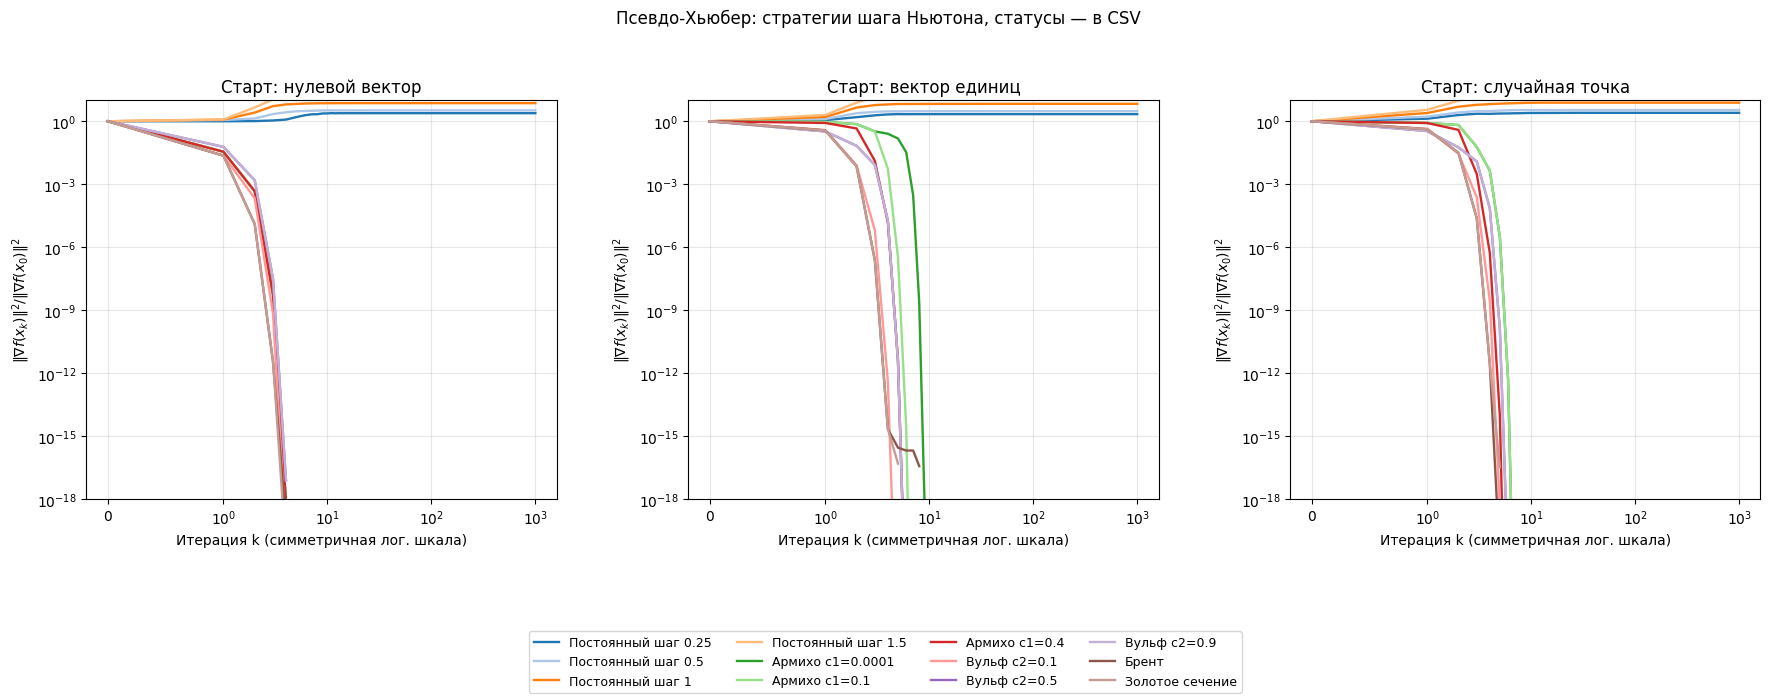

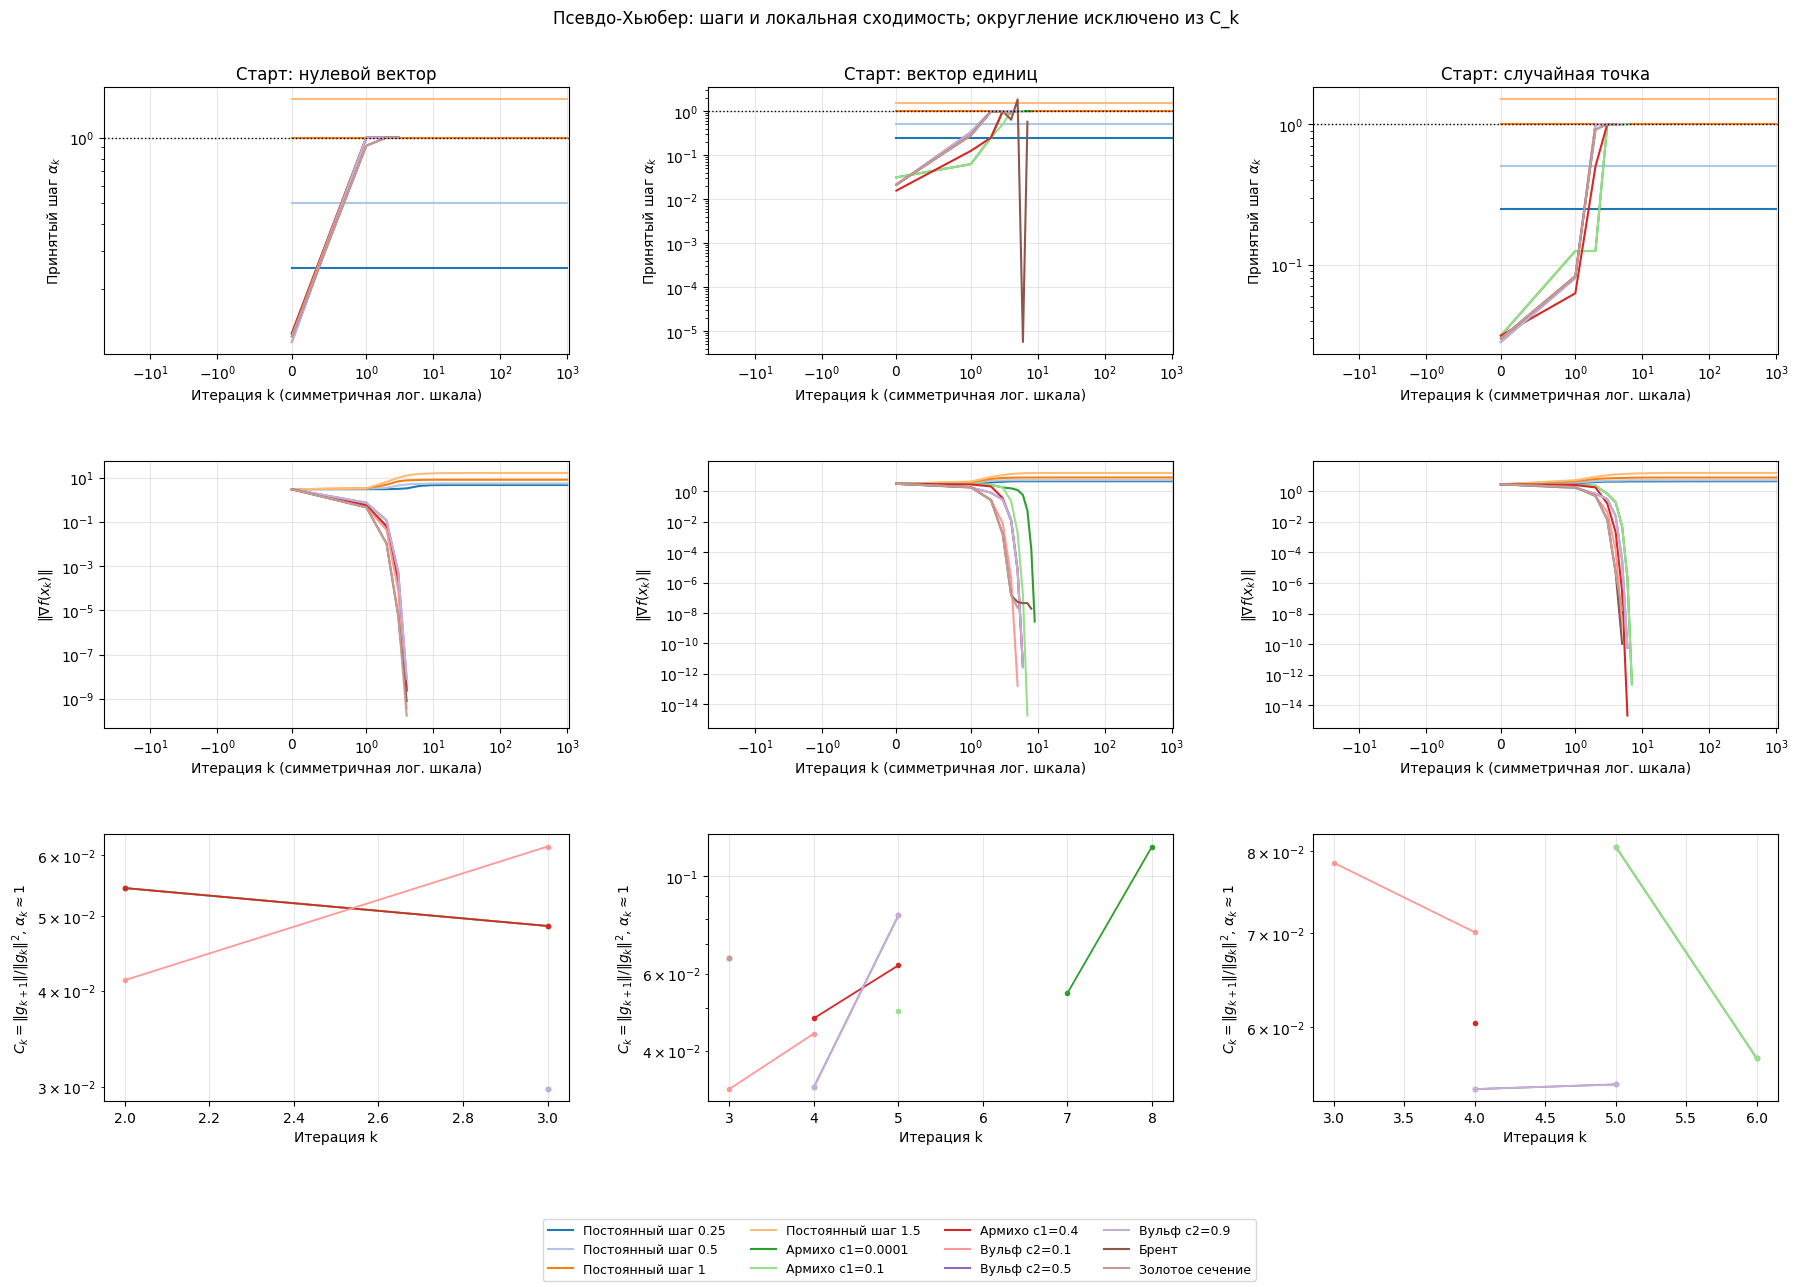

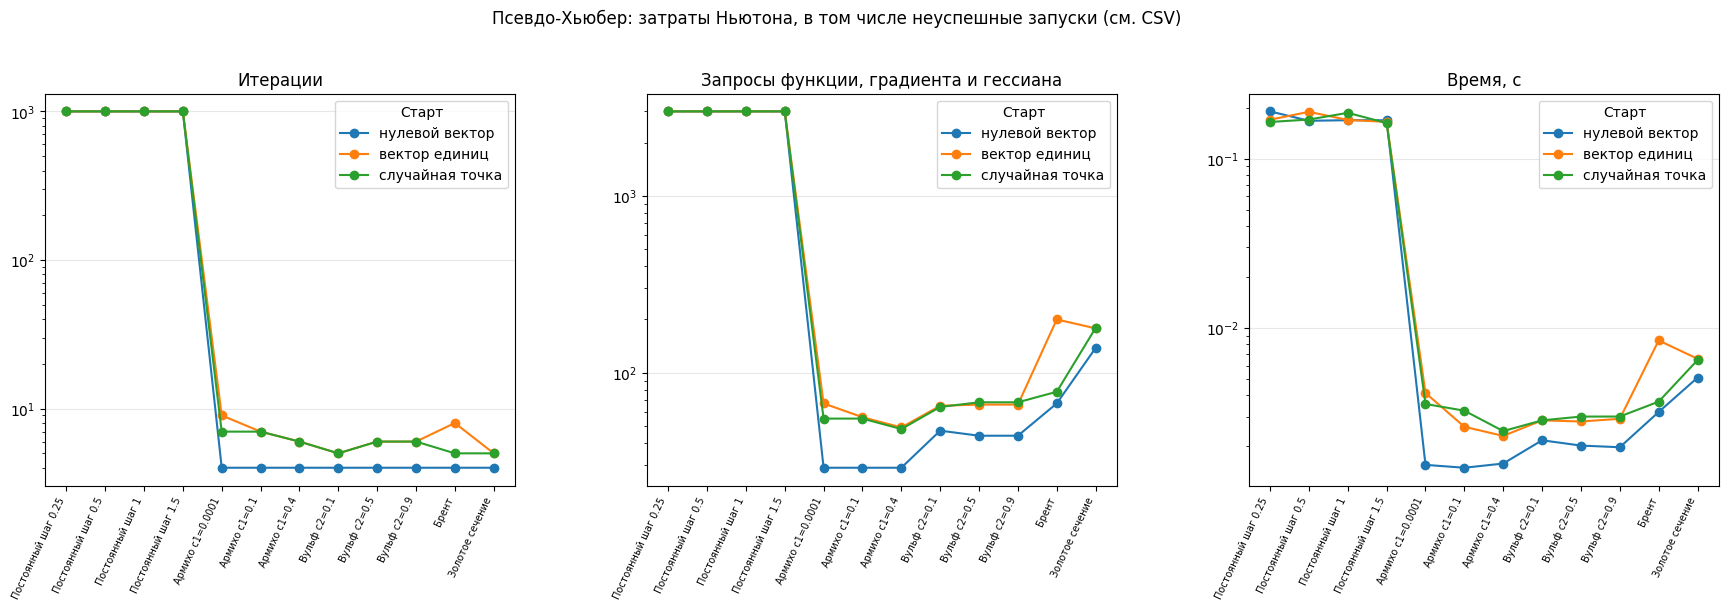

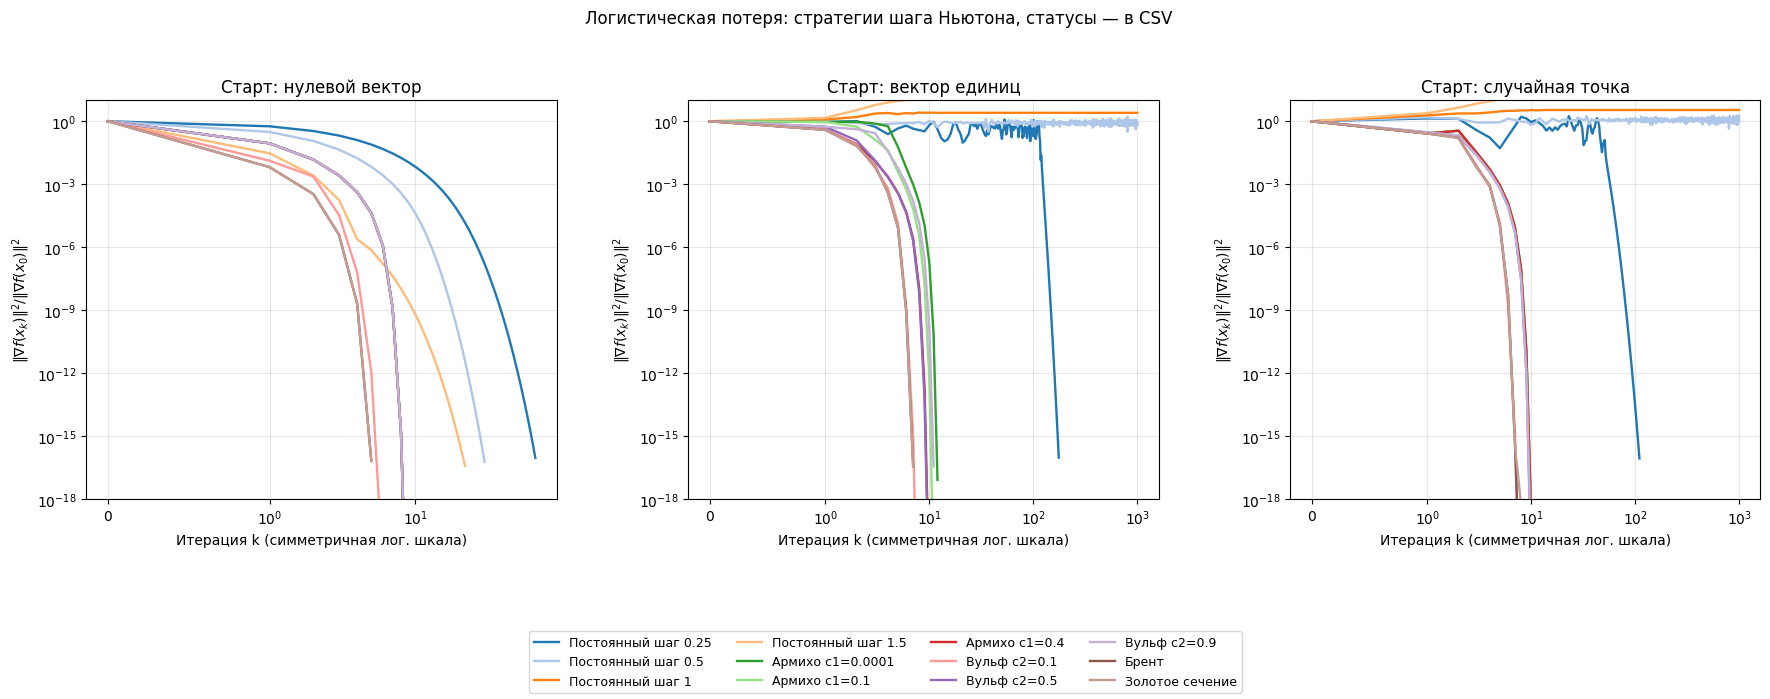

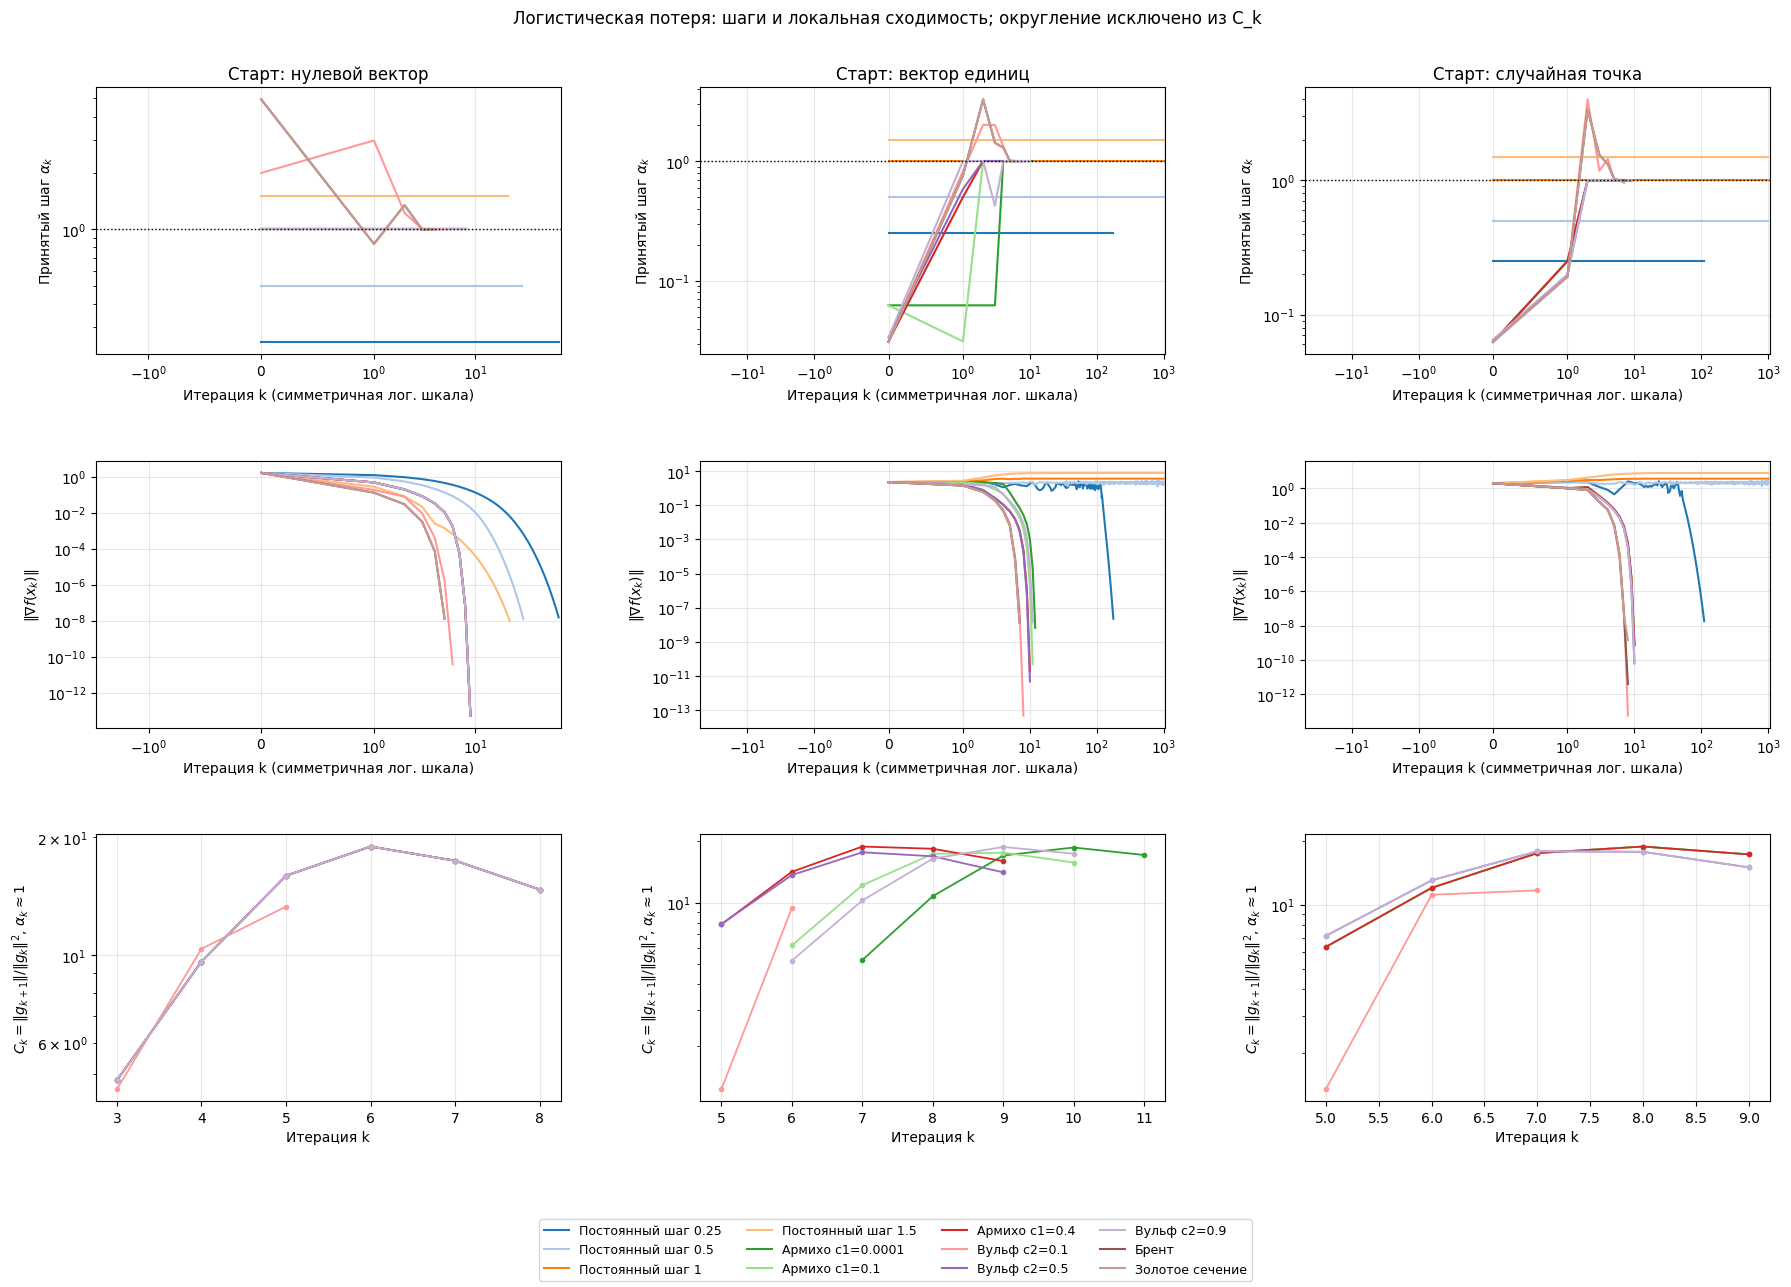

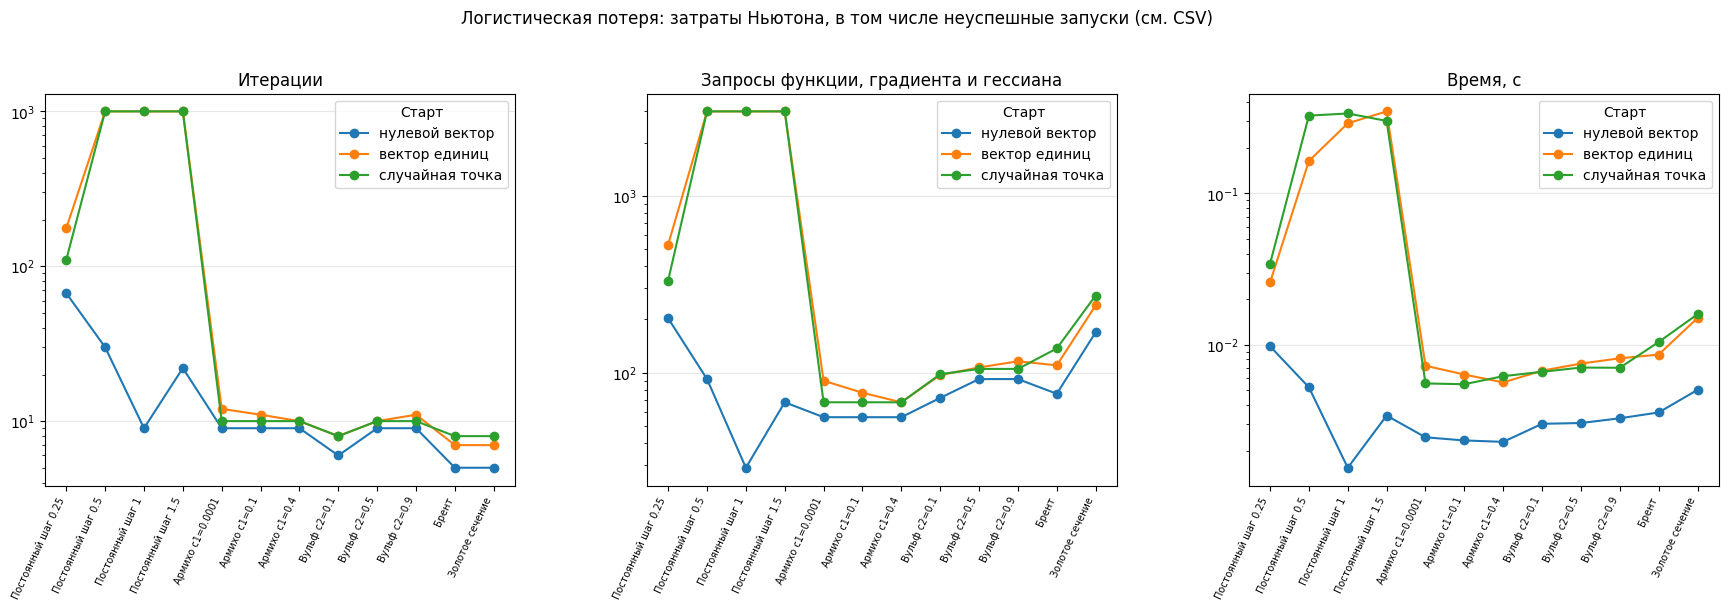

In [51]:
exp5_figures = {}
exp5_names = list(exp5_strategies)
exp5_colors = {name: plt.get_cmap('tab20')(i) for i, name in enumerate(exp5_names)}
for problem_name in exp5_problems:
    fig, axes = plt.subplots(1, len(exp5_starts), figsize=(18, 7))
    fig.subplots_adjust(left=0.06, right=0.99, bottom=0.28, top=0.85, wspace=0.28)
    for ax, start_name in zip(axes, exp5_starts):
        ax.set_yscale('log')
        ax.set_xscale('symlog', linthresh=1)
        ax.set_ylim(exp5_tolerance * 0.01, 10)
        for strategy_name in exp5_names:
            result = exp5_results[(problem_name, start_name, strategy_name)]
            ratio = experiment_relative_gradient(result['history'])
            ax.plot(np.arange(len(ratio)), np.maximum(ratio, np.finfo(float).tiny),
                     color=exp5_colors[strategy_name], linewidth=1.7, label=strategy_name)
        ax.set(title=f'Старт: {start_name}', xlabel='Итерация k (symlog)',
               ylabel=r'$\|\nabla f(x_k)\|^2/\|\nabla f(x_0)\|^2$')
        ax.grid(alpha=0.3)
    fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=4, fontsize=9)
    fig.suptitle(f'{problem_name}: стратегии шага Ньютона, статусы — в CSV')
    experiment_prepare_figure(fig)
    fig.savefig(experiment_output_dir / f'exp5_{problem_name}_convergence.png', dpi=180)
    exp5_figures[(problem_name, 'convergence')] = fig
    plt.show()
    plt.close(fig)

    diagnostic_fig, panels = plt.subplots(3, len(exp5_starts), figsize=(18, 13))
    diagnostic_fig.subplots_adjust(left=0.06, right=0.99, bottom=0.14, top=0.92,
                                    hspace=0.4, wspace=0.3)
    for col, start_name in enumerate(exp5_starts):
        for strategy_name in exp5_names:
            key = (problem_name, start_name, strategy_name)
            result, diagnostic = exp5_results[key], exp5_diagnostics[key]
            norms = np.asarray(result['history']['grad_norm'])
            alphas = np.asarray(result['history']['alpha'])
            color = exp5_colors[strategy_name]
            panels[0, col].plot(np.arange(len(alphas)), alphas, color=color,
                                 linewidth=1.5, label=strategy_name)
            panels[1, col].plot(np.arange(len(norms)), np.maximum(norms, np.finfo(float).tiny),
                                 color=color, linewidth=1.5)
            unit = np.isclose(alphas, 1.0, rtol=1e-7, atol=1e-10)
            indices = np.flatnonzero(diagnostic['local'])
            panels[2, col].plot(indices, diagnostic['C'][indices], marker='o',
                                 markersize=3, color=color, linewidth=1.3)
        panels[0, col].axhline(1, color='black', linestyle=':', linewidth=1)
        panels[0, col].set_title(f'Старт: {start_name}')
        for row, ylabel in enumerate([
            r'Принятый шаг $\alpha_k$', r'$\|\nabla f(x_k)\|$',
            r'$C_k=\|g_{k+1}\|/\|g_k\|^2$, $\alpha_k\approx1$',
        ]):
            panels[row, col].set_yscale('log')
            if row < 2:
                panels[row, col].set_xscale('symlog', linthresh=1)
            panels[row, col].set(xlabel='Итерация k (symlog)' if row < 2 else 'Итерация k',
                                 ylabel=ylabel)
            panels[row, col].grid(alpha=0.3)
    diagnostic_fig.legend(*panels[0, 0].get_legend_handles_labels(),
                           loc='lower center', ncol=4, fontsize=9)
    diagnostic_fig.suptitle(f'{problem_name}: шаги и локальная сходимость; округление исключено из C_k')
    experiment_prepare_figure(diagnostic_fig)
    diagnostic_fig.savefig(experiment_output_dir / f'exp5_{problem_name}_quadratic_phase.png', dpi=180)
    exp5_figures[(problem_name, 'diagnostic')] = diagnostic_fig
    plt.show()
    plt.close(diagnostic_fig)

    cost_fig, axes = plt.subplots(1, 3, figsize=(18, 7))
    cost_fig.subplots_adjust(left=0.06, right=0.99, bottom=0.3, top=0.86, wspace=0.28)
    for ax, metric, title in zip(axes, ['iterations', 'oracle_calls', 'elapsed'],
                                ['Итерации', 'Запросы функции, градиента и гессиана', 'Время, с']):
        for index, start_name in enumerate(exp5_starts):
            values = [exp5_results[(problem_name, start_name, name)][metric] for name in exp5_names]
            ax.plot(np.arange(len(values)), np.maximum(values, np.finfo(float).tiny),
                     marker='o', linewidth=1.5, label=start_name)
        ax.set_yscale('log')
        ax.set_xticks(np.arange(len(exp5_names)), exp5_names, rotation=65, ha='right', fontsize=7)
        ax.set_title(title)
        ax.legend(title='Старт')
        ax.grid(axis='y', alpha=0.3)
    cost_fig.suptitle(f'{problem_name}: затраты Ньютона, в том числе неуспешные запуски (см. CSV)')
    experiment_prepare_figure(cost_fig)
    cost_fig.savefig(experiment_output_dir / f'exp5_{problem_name}_costs.png', dpi=180)
    exp5_figures[(problem_name, 'costs')] = cost_fig
    plt.show()
    plt.close(cost_fig)


Эксперимент 5: Ваш ответ

**Данные и параметры эксперимента.**

Использованы те же модельные данные Pseudo-Huber и Logistic, что
в эксперименте 4: $m=200$, $n=20$, $\delta=1$, $\lambda=0.005$,
те же три начальные точки. Направление Ньютона вычисляется из
$H(x_k)d_k=-\nabla f(x_k)$ с помощью Холецкого.

Для постоянного шага выбраны $\alpha\in\{0.25,0.5,1,1.5\}$.
Параметры Армихо, Вульфа, Брента и золотого сечения совпадают
с экспериментом 4. Лимит — $1000$ итераций, относительный квадрат
нормы градиента должен быть не больше $10^{-16}$.
Более строгий критерий позволяет проследить локальное поведение
до того, как начинают сказываться ошибки округления. Среда вычислений та же, что в эксперименте 3.

Записывались все принятые шаги. Номер $k_{\mathrm{unit}}$ отмечает начало участка в конце траектории,
на котором все шаги до остановки удовлетворяют $\alpha_k\approx1$; нумерация начинается с нуля. Это наблюдение
по конечной траектории, а не доказательство принятия полного шага
на всех возможных последующих итерациях.

**Результаты.**

Из 72 запусков успешно завершились 54, остальные 18 достигли лимита.
Запуски с Армихо, Вульфом, Брентом и золотым сечением завершились успешно
из всех трёх стартов. В таблице показаны несколько характерных вариантов.

| Потеря | Стратегия | Нулевой старт | Единицы | Случайный старт | Время из нуля, с |
|---|---|---|---|---|---|
| Pseudo-Huber | Армихо, $c_1=0.4$ | 4 | 6 | 6 | 0.0017 |
| Pseudo-Huber | Вульф, $c_2=0.1$ | 4 | 5 | 5 | 0.0023 |
| Pseudo-Huber | Брент | 4 | 8 | 5 | 0.0033 |
| Pseudo-Huber | Золотое сечение | 4 | 5 | 5 | 0.0056 |
| Logistic | Армихо, $c_1=0.4$ | 9 | 10 | 10 | 0.0025 |
| Logistic | Вульф, $c_2=0.1$ | 6 | 8 | 8 | 0.0025 |
| Logistic | Брент | 5 | 7 | 8 | 0.0032 |
| Logistic | Золотое сечение | 5 | 7 | 8 | 0.0050 |

Для Pseudo-Huber ни один из четырёх постоянных шагов не привёл
к выполнению критерия за $1000$ итераций. На Logistic метод с шагом $0.25$
сошёлся из всех стартов за 67, 176 и 110 итераций. С шагами $0.5$, $1$
и $1.5$ метод сошёлся из нуля за 30, 9 и 22 итерации соответственно,
а из двух остальных стартов достигли лимита.
Это показывает, что положительного гессиана недостаточно
для успешного применения фиксированного полного шага вдали от решения.

**1. Сравнение стратегий.**

На Pseudo-Huber Вульф с $c_2=0.1$ потребовал 4–5 итераций,
Армихо с $c_1=0.4$ — 4–6. На Logistic Брент и золотое сечение
дали 5–8 итераций, Вульф с $c_2=0.1$ — 6–8, Армихо с $c_1=0.4$ — 9–10.
По времени в сохранённом запуске лучшие результаты в каждом старте
показал один из вариантов Армихо. На малых задачах время измеряется
миллисекундами, поэтому небольшие различия между близкими параметрами
следует оценивать осторожно.

На графиках затрат видно, что меньшее число внешних итераций
не обязательно сокращает число вызовов оракула.
Брент и особенно золотое сечение чаще запрашивают функцию,
чтобы уточнить минимум вдоль направления. Например, для Pseudo-Huber
из нуля все четыре приведённые стратегии выполнили по четыре шага,
но одномерный поиск занял больше времени.

**2. Почему приоритетен единичный шаг.**

Направление Ньютона уже задаёт перемещение к минимуму текущей
квадратичной модели. Поэтому $\alpha=1$ использует это перемещение целиком.
Вблизи невырожденного минимума модель становится точной до остатка
более высокого порядка, и полный шаг даёт локальную квадратичную сходимость.
Вдали от минимума модель может быть неточной, поэтому длину шага нужно проверять.

При фиксированном $\alpha\ne1$ локальная формула ошибки имеет вид
$$
e_{k+1}=(1-\alpha)e_k+O(\|e_k\|_2^2),
\qquad e_k=x_k-x^*.
$$
Линейный член обычно сохраняется. Поэтому уменьшенный постоянный шаг
может повысить устойчивость, но лишает метод полного локального ускорения.
Армихо сначала проверяет $\alpha=1$ и дробит его только при необходимости.
Вблизи решения при выполнении условий локальной теории полный шаг
принимается, и затраты на подбор уменьшаются.

**3. Полные шаги и квадратичная сходимость.**

В таблице указано, с какой итерации начинается участок полных шагов. В столбце Армихо
тройки соответствуют $c_1=(10^{-4},0.1,0.4)$, в столбце Вульфа —
$c_2=(0.1,0.5,0.9)$. Последний столбец — медиана диагностических значений $C_k$ для Армихо
с $c_1=0.4$ на локальных переходах.

| Потеря | Старт | $k_{\mathrm{unit}}$, Армихо | $k_{\mathrm{unit}}$, Вульф | Медиана $C_k$, Армихо $0.4$ |
|---|---|---|---|---|
| Pseudo-Huber | Нулевой | (1, 1, 1) | (1, 1, 1) | 0.05147 |
| Pseudo-Huber | Единицы | (3, 4, 3) | (2, 2, 2) | 0.05507 |
| Pseudo-Huber | Случайный | (3, 3, 3) | (2, 2, 2) | 0.06041 |
| Logistic | Нулевой | (0, 0, 0) | (3, 0, 0) | 15.32 |
| Logistic | Единицы | (4, 2, 2) | (5, 2, 4) | 15.98 |
| Logistic | Случайный | (2, 2, 2) | (5, 2, 2) | 17.23 |

При постоянном шаге $\alpha=1$ успешный запуск Logistic из нуля имеет
$k_{\mathrm{unit}}=0$; для постоянных шагов, отличных от единицы,
участка полных шагов нет. Для несошедшихся запусков номер не определяется.
В запусках с Брентом и золотым сечением не обнаружено участка в конце
траектории, на котором все шаги совпадают с единицей в принятом допуске. Их численно найденные шаги не обязаны
совпадать с $1$; отсутствие такого участка не означает отсутствие сходимости.

Диагностика основана на отношении
$$
C_k=\frac{\|\nabla f(x_{k+1})\|_2}{\|\nabla f(x_k)\|_2^2}.
$$
Учитываются переходы с полным шагом, убывающей нормой градиента
и $\|\nabla f(x_k)\|_2\leq0.1$; значения около уровня округления исключаются.
Порог $0.1$ выбран для диагностики этих задач и не является
универсальной границей зоны квадратичной сходимости.

Графики показывают ускорение уменьшения градиента после перехода
к полным шагам. Значения $C_k$ на доступном локальном участке имеют
конечный сопоставимый масштаб; он различается у двух моделей.
Наблюдений до остановки мало. Они согласуются с квадратичной сходимостью,
но не доказывают её порядок.
Сам факт принятия $\alpha=1$ также недостаточен.

Локальная теорема Ньютона оценивает ошибку точки. Для нормы градиента
можно получить отдельную оценку: при локально липшицевом гессиане
с константой $M$ и $H(x_k)\succeq\mu I$, $\mu>0$, если весь отрезок
полного шага лежит в этой окрестности, то
$$
\|\nabla f(x_{k+1})\|_2
\leq\frac{M}{2}\|d_k\|_2^2
\leq\frac{M}{2\mu^2}\|\nabla f(x_k)\|_2^2.
$$
Здесь постоянная не обязана быть одинаковой для разных потерь или траекторий.

## Эксперимент 6. Влияние регуляризации на обусловленность и скорость сходимости

Коэффициент $\lambda$ напрямую задаёт константу сильной выпуклости: чем он больше, тем лучше обусловлена задача, но тем дальше её минимум от минимума нерегуляризованной функции.

**Порядок проведения.**
1. Для каждой модели вашего варианта возьмите датасет с наибольшим числом признаков $n$, на котором метод Ньютона помещается в память, и зафиксируйте начальную точку $x_0$.
2. Запустите градиентный спуск и метод Ньютона для $\lambda \in \{10^{-5}, 10^{-4}, 10^{-3}, 10^{-2}, 0.1, 1, 10\}$.
3. Постройте графики:
   * число итераций до сходимости от $\lambda$ (отдельные кривые для градиентного спуска и метода Ньютона);
   * время работы до сходимости от $\lambda$;
   * норма решения $\|x^*\|_2$ от $\lambda$.
4. Сравните, для какой функции потерь (регрессионной или классификационной) изменение $\lambda$ сильнее влияет на устойчивость метода Ньютона.

### Вопросы для отчёта
1. Как меняется число итераций методов при $\lambda \to 0$ и почему?
2. Возникала ли численная неустойчивость при некоторых $\lambda$? Если да, почему и как вы её устранили?
3. Как $\lambda$ влияет на ширину зоны квадратичной сходимости метода Ньютона?
4. Наблюдается ли плато в числе итераций при больших $\lambda$? Почему?

In [52]:
exp6_candidates = {
    'pseudohuber': {'mg_scale': (A_mg, b_mg),
                   'triazines_scale': (A_triazines, b_triazines)},
    'logistic': {'phishing': (A_phishing, b_phishing),
                'real-sim': (A_real_sim, b_real_sim)},
}
exp6_memory_fraction = 0.6


def experiment_newton_memory(A, fraction=0.6):
    memory = experiment_hardware()
    available = memory['available_ram_bytes']
    if available is None and memory['ram_bytes'] is not None:
        available = memory['ram_bytes'] // 2
    budget = None if available is None else fraction * available
    nnz = A.nnz if scipy.sparse.issparse(A) else np.count_nonzero(A)
    hessian_bytes = 8 * A.shape[1] ** 2
    estimated_peak = 6 * hessian_bytes + 32 * nnz
    return budget is not None and estimated_peak <= budget, {
        'dense_hessian_gib': hessian_bytes / 2**30,
        'estimated_peak_gib': estimated_peak / 2**30,
        'memory_budget_gib': None if budget is None else budget / 2**30,
    }


exp6_selected, exp6_selection_table = {}, []
for loss_name, candidates in exp6_candidates.items():
    for dataset_name, (A, b) in sorted(candidates.items(), key=lambda item: item[1][0].shape[1], reverse=True):
        fits, memory = experiment_newton_memory(A, exp6_memory_fraction)
        exp6_selection_table.append({'loss': loss_name, 'dataset': dataset_name,
                                     'm': A.shape[0], 'n': A.shape[1], 'fits_memory': fits, **memory})
        print(f'{loss_name}: {dataset_name}, n={A.shape[1]}, подходит={fits}, {memory}')
        if fits:
            exp6_selected[loss_name] = {
                'name': dataset_name, 'A': A, 'b': b, 'x_0': np.zeros(A.shape[1]),
                'fingerprint': experiment_fingerprint(A, b),
            }
            break
    if loss_name not in exp6_selected:
        raise MemoryError(f'Для {loss_name} нет датасета, помещающегося в бюджет памяти Ньютона')
experiment_save_table('exp6_dataset_selection.csv', exp6_selection_table)
exp6_lambdas = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0]
exp6_tolerance = 1e-10
exp6_gd_max_iter, exp6_newton_max_iter = 100000, 100
exp6_line_search = {'method': 'Wolfe'}


pseudohuber: triazines_scale, n=60, подходит=True, {'dense_hessian_gib': 2.682209014892578e-05, 'estimated_peak_gib': np.float64(0.0004584193229675293), 'memory_budget_gib': 6.156278228759765}
logistic: real-sim, n=20958, подходит=False, {'dense_hessian_gib': 3.2725763618946075, 'estimated_peak_gib': 19.745997458696365, 'memory_budget_gib': 6.156278228759765}
logistic: phishing, n=68, подходит=True, {'dense_hessian_gib': 3.445148468017578e-05, 'estimated_peak_gib': 0.010090649127960205, 'memory_budget_gib': 6.156278228759765}


In [53]:
exp6_results, exp6_table = {}, []
for loss_name, data in exp6_selected.items():
    A, b, x_0 = data['A'], data['b'], data['x_0']
    for regcoef in exp6_lambdas:
        oracle = create_linear_model_oracle(A, b, regcoef, loss_name)
        problem = {'dataset': data['name'], 'fingerprint': data['fingerprint'],
                   'loss': loss_name, 'regcoef': regcoef}
        for method_name, optimizer, max_iter in [
            ('GD', gradient_descent, exp6_gd_max_iter),
            ('Newton', newton, exp6_newton_max_iter),
        ]:
            result = experiment_run(
                'exp6', oracle, x_0, optimizer, problem,
                tolerance=exp6_tolerance, max_iter=max_iter,
                line_search_options=exp6_line_search,
            )
            exp6_results[(loss_name, regcoef, method_name)] = result
            norm = float(np.linalg.norm(result['x_opt']))
            exp6_table.append({
                'loss': loss_name, 'dataset': data['name'], 'lambda': regcoef,
                'method': method_name, 'status': result['message'],
                'iterations': result['iterations'], 'seconds': result['elapsed'],
                'solution_norm': norm if result['message'] == 'success' else None,
                'terminal_norm': norm, 'oracle_calls': result['oracle_calls'],
                'relative_grad_sq': float(experiment_relative_gradient(result['history'])[-1]),
                'final_grad_norm': float(result['history']['grad_norm'][-1]),
            })
            print(f"{loss_name:<12} lambda={regcoef:g} {method_name:<6} "
                  f"{result['message']:<22} T={result['iterations']:5d}, "
                  f"t={result['elapsed']:.4f} с, ||x||={norm:.6g}", flush=True)
experiment_save_table('exp6_regularization.csv', exp6_table)

experiment_show_table(exp6_table, index=['loss', 'lambda'], columns='method', values=['iterations', 'seconds', 'solution_norm', 'status'])


pseudohuber  lambda=1e-05 GD     success                T=61639, t=29.6354 с, ||x||=0.847751
pseudohuber  lambda=1e-05 Newton success                T=    4, t=0.0024 с, ||x||=0.879903
pseudohuber  lambda=0.0001 GD     success                T=55669, t=27.1218 с, ||x||=0.803738
pseudohuber  lambda=0.0001 Newton success                T=    4, t=0.0025 с, ||x||=0.821435
pseudohuber  lambda=0.001 GD     success                T=28911, t=13.9592 с, ||x||=0.61263
pseudohuber  lambda=0.001 Newton success                T=    4, t=0.0024 с, ||x||=0.618259
pseudohuber  lambda=0.01 GD     success                T= 5286, t=2.2587 с, ||x||=0.388197
pseudohuber  lambda=0.01 Newton success                T=    4, t=0.0023 с, ||x||=0.388713
pseudohuber  lambda=0.1 GD     success                T=  806, t=0.4182 с, ||x||=0.217541
pseudohuber  lambda=0.1 Newton success                T=    4, t=0.0024 с, ||x||=0.2176
pseudohuber  lambda=1 GD     success                T=   68, t=0.0266 с, ||x||=0.123

iterations           seconds           solution_norm  \
method                       GD Newton         GD    Newton            GD   
loss        lambda                                                          
pseudohuber 0.00001       61639      4  29.635354  0.002373      0.847751   
            0.00010       55669      4  27.121792  0.002540      0.803738   
            0.00100       28911      4  13.959166  0.002414      0.612630   
            0.01000        5286      4   2.258731  0.002324      0.388197   
            0.10000         806      4   0.418235  0.002350      0.217541   
            1.00000          68      3   0.026649  0.001874      0.123372   
            10.00000         13      3   0.006361  0.001834      0.084682   
logistic    0.00001        1125      7  18.186261  0.251969     38.142051   
            0.00010         646      6  10.897853  0.232200     24.894166   
            0.00100         204      4   2.622578  0.149040     12.643377   
            0.01000          84      3   1.447404  0.271311      4.287704   
            0.10000         100      2   1.563928  0.181629      0.701036   
            1.00000           7      2   0.110729  0.170442      0.083538   
            10.00000          3      1   0.056926  0.091464      0.008714   

                                  status           
method                   Newton       GD   Newton  
loss        lambda                                 
pseudohuber 0.00001    0.879903  success  success  
            0.00010    0.821435  success  success  
            0.00100    0.618259  success  success  
            0.01000    0.388713  success  success  
            0.10000    0.217600  success  success  
            1.00000    0.123381  success  success  
            10.00000   0.084682  success  success  
logistic    0.00001   38.148911  success  success  
            0.00010   24.894647  success  success  
            0.00100   12.643448  success  success  
            0.01000    4.287727  success  success  
            0.10000    0.701043  success  success  
            1.00000    0.083538  success  success  
            10.00000   0.008714  success  success

iterations           seconds           solution_norm  \
method                       GD Newton         GD    Newton            GD   
loss        lambda                                                          
pseudohuber 0.00001       61639      4  29.635354  0.002373      0.847751   
            0.00010       55669      4  27.121792  0.002540      0.803738   
            0.00100       28911      4  13.959166  0.002414      0.612630   
            0.01000        5286      4   2.258731  0.002324      0.388197   
            0.10000         806      4   0.418235  0.002350      0.217541   
            1.00000          68      3   0.026649  0.001874      0.123372   
            10.00000         13      3   0.006361  0.001834      0.084682   
logistic    0.00001        1125      7  18.186261  0.251969     38.142051   
            0.00010         646      6  10.897853  0.232200     24.894166   
            0.00100         204      4   2.622578  0.149040     12.643377   
            0.01000          84      3   1.447404  0.271311      4.287704   
            0.10000         100      2   1.563928  0.181629      0.701036   
            1.00000           7      2   0.110729  0.170442      0.083538   
            10.00000          3      1   0.056926  0.091464      0.008714   

                                  status           
method                   Newton       GD   Newton  
loss        lambda                                 
pseudohuber 0.00001    0.879903  success  success  
            0.00010    0.821435  success  success  
            0.00100    0.618259  success  success  
            0.01000    0.388713  success  success  
            0.10000    0.217600  success  success  
            1.00000    0.123381  success  success  
            10.00000   0.084682  success  success  
logistic    0.00001   38.148911  success  success  
            0.00010   24.894647  success  success  
            0.00100   12.643448  success  success  
            0.01000    4.287727  success  success  
            0.10000    0.701043  success  success  
            1.00000    0.083538  success  success  
            10.00000   0.008714  success  success

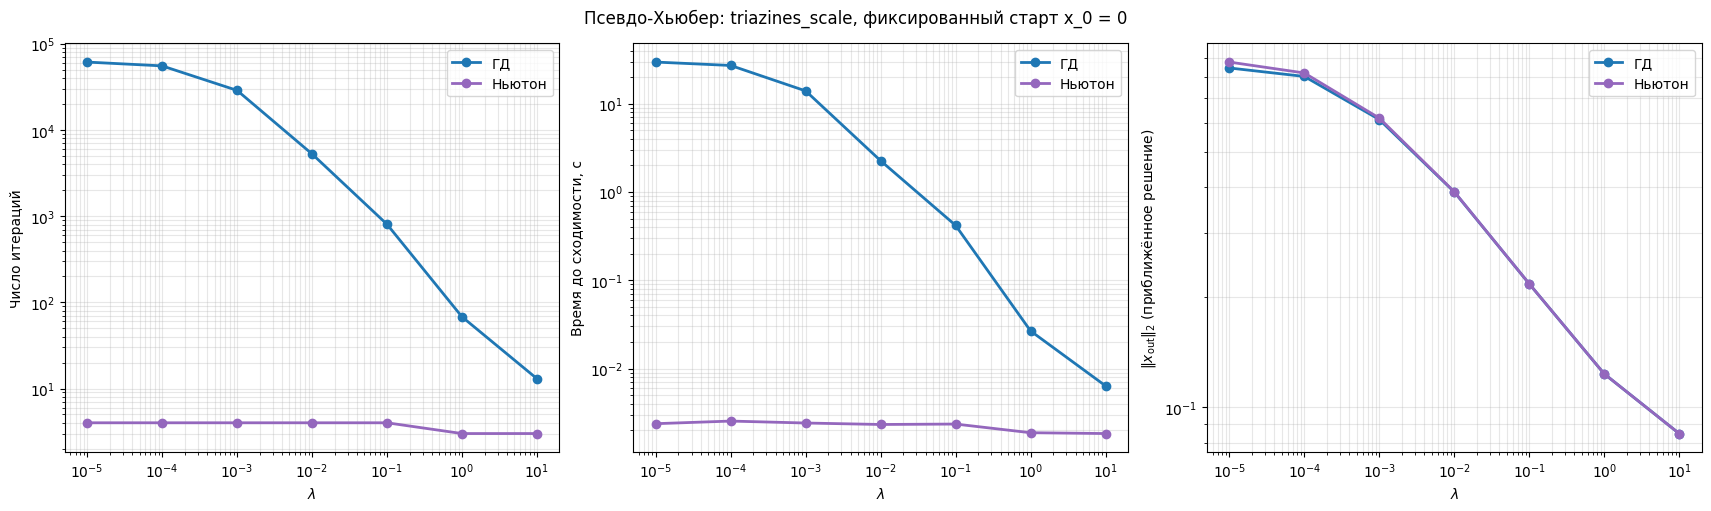

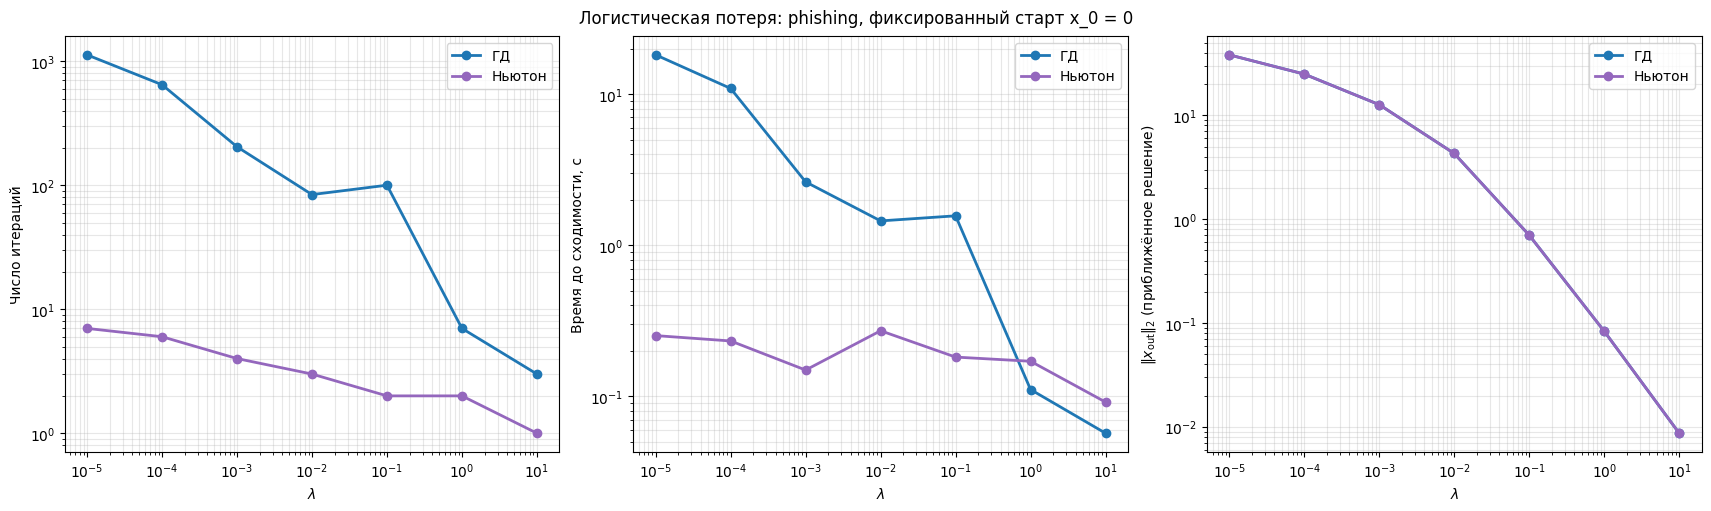

In [54]:
exp6_figures = {}
for loss_name, data in exp6_selected.items():
    fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
    for method_name, color, marker in [('GD', 'tab:blue', 'o'), ('Newton', 'tab:purple', 'o')]:
        results = [exp6_results[(loss_name, regcoef, method_name)] for regcoef in exp6_lambdas]
        succeeded = np.array([r['message'] == 'success' for r in results])
        metrics = [np.array([r['iterations'] for r in results], dtype=float),
                   np.array([r['elapsed'] for r in results]),
                   np.array([np.linalg.norm(r['x_opt']) for r in results])]
        for ax, values in zip(axes, metrics):
            ax.plot(exp6_lambdas, np.where(succeeded, values, np.nan), color=color,
                     marker=marker, linewidth=2, label=method_name)
            if np.any(~succeeded):
                ax.scatter(np.array(exp6_lambdas)[~succeeded], values[~succeeded],
                            marker='o', color='red', s=70, label=f'{method_name}: без success')
    for ax, ylabel in zip(axes, ['Число итераций', 'Время до сходимости, с', r'$\|x_{\mathrm{out}}\|_2$ (приближённое решение)']):
        ax.set(xscale='log', yscale='log', xlabel=r'$\lambda$', ylabel=ylabel)
        ax.grid(alpha=0.3, which='both')
        ax.legend()
    fig.suptitle(f'{loss_name}: {data["name"]}, фиксированный старт x_0 = 0')
    experiment_prepare_figure(fig)
    fig.savefig(experiment_output_dir / f'exp6_{loss_name}_regularization.png', dpi=180)
    exp6_figures[loss_name] = fig
    plt.show()
    plt.close(fig)


Эксперимент 6: Ваш ответ

**Данные и параметры эксперимента.**

Для каждой потери выбран датасет с наибольшим числом признаков,
на котором расчёт методом Ньютона укладывается в заданный бюджет памяти:
`triazines_scale` для Pseudo-Huber ($m=186$, $n=60$) и `phishing`
для Logistic ($m=11055$, $n=68$). `real-sim` исключён по оценке памяти,
как в эксперименте 3. Данные и начальная точка $x_0=0$ внутри каждой
модели остаются одинаковыми при всех значениях регуляризации.

Исследованы
$$
\lambda\in\{10^{-5},10^{-4},10^{-3},10^{-2},0.1,1,10\}.
$$
Использован поиск по Вульфу; при неудаче реализация переходит
к Армихо. Лимиты — $100000$ итераций GD и $100$ Ньютона,
критерий — относительный квадрат нормы градиента не больше $10^{-10}$.
Pseudo-Huber задана с $\delta=1$. Среда вычислений та же,
что в эксперименте 3; арифметика `float64`.

**Результаты.**

Все 28 запусков завершились успешно. В последнем столбце приведена
норма приближённого решения Ньютона; на графиках показаны нормы решений
обоих методов.

| Потеря | $\lambda$ | Итерации GD | Итерации Ньютона | Время GD, с | Время Ньютона, с | $\lVert x_{\mathrm{out}}\rVert_2$, Ньютон |
|---|---|---|---|---|---|---|
| Pseudo-Huber | $10^{-5}$ | 61639 | 4 | 30.8398 | 0.0025 | 0.879903 |
| Pseudo-Huber | $10^{-4}$ | 55669 | 4 | 28.4799 | 0.0025 | 0.821435 |
| Pseudo-Huber | $10^{-3}$ | 28911 | 4 | 14.4583 | 0.0026 | 0.618259 |
| Pseudo-Huber | $10^{-2}$ | 5286 | 4 | 3.5711 | 0.0055 | 0.388713 |
| Pseudo-Huber | $0.1$ | 806 | 4 | 0.7323 | 0.0050 | 0.2176 |
| Pseudo-Huber | $1$ | 68 | 3 | 0.0672 | 0.0040 | 0.123381 |
| Pseudo-Huber | $10$ | 13 | 3 | 0.0142 | 0.0040 | 0.0846824 |
| Logistic | $10^{-5}$ | 1125 | 7 | 18.4321 | 0.2924 | 38.1489 |
| Logistic | $10^{-4}$ | 646 | 6 | 10.9113 | 0.2211 | 24.8946 |
| Logistic | $10^{-3}$ | 204 | 4 | 2.6696 | 0.1538 | 12.6434 |
| Logistic | $10^{-2}$ | 84 | 3 | 0.9856 | 0.1094 | 4.28773 |
| Logistic | $0.1$ | 100 | 2 | 0.7056 | 0.0779 | 0.701043 |
| Logistic | $1$ | 7 | 2 | 0.0530 | 0.0722 | 0.0835377 |
| Logistic | $10$ | 3 | 1 | 0.0259 | 0.0371 | 0.00871425 |

При ослаблении регуляризации GD в целом требует больше итераций.
Для Pseudo-Huber разница особенно велика: от 13 шагов при $\lambda=10$
до 61639 при $\lambda=10^{-5}$. На Logistic изменение также заметно,
но зависимость не строго монотонна: при переходе от $0.01$ к $0.1$
число итераций выросло с 84 до 100, хотя время уменьшилось.
Число шагов зависит от кривизны вдоль всей траектории и работы поиска шага.

Ньютон потребовал 3–4 итерации на Pseudo-Huber и 1–7 на Logistic.
При больших $\lambda$ GD может оказаться быстрее Ньютона,
если ему достаточно малого числа шагов: на Logistic при $\lambda=1$ и $10$ именно так и произошло.

**1. Почему ослабление регуляризации замедляет сходимость.**

Запишем $f_\lambda(x)=R(x)+\lambda\|x\|_2^2/2$, где $R$ — средняя потеря.
Тогда
$$
H_\lambda(x)=\nabla^2R(x)+\lambda I\succeq\lambda I.
$$
Регуляризация задаёт гарантированную нижнюю границу кривизны;
фактическая константа сильной выпуклости может быть больше $\lambda$.
Если $\|\nabla^2R(x)\|_2\leq B$, то
$$
\kappa_2(H_\lambda(x))\leq\frac{B+\lambda}{\lambda}.
$$
При малом $\lambda$ почти плоские направления данных могут ухудшать
обусловленность, и GD медленно уменьшает ошибку вдоль них.
Ньютон учитывает разные масштабы кривизны при решении системы,
поэтому в этих запусках число его итераций меняется слабее.
Предел $\lambda=0$ не исследовался; по конечной сетке нельзя утверждать,
что число шагов обязательно стремится к бесконечности для любого датасета.

**2. Устойчивость и точность решения.**

Ошибок Холецкого и аварийных завершений в этих запусках не было.
Возникали предупреждения поиска Вульфа; имеющийся переход к Армихо
позволил продолжить вычисления. Дополнительный сдвиг гессиана
или изменение целевой функции не применялись.

У Logistic при ослаблении регуляризации число шагов Ньютона выросло
с 1 до 7, у Pseudo-Huber — с 3 до 4. В этих опытах число шагов сильнее изменилось
у логистической модели, но на обеих моделях численных сбоев не было.
Датасеты различаются, поэтому нельзя отделить влияние потери от влияния данных.

При слабой регуляризации одинаковая точность по градиенту не обеспечивает
одинаковую точность координат. Для сильно выпуклой функции
$$
\|x-x^*\|_2\leq\frac{\|\nabla f_\lambda(x)\|_2}{\mu}
\leq\frac{\|\nabla f_\lambda(x)\|_2}{\lambda}.
$$
Например, при $\lambda=10^{-5}$ на Pseudo-Huber норма решения GD
равна примерно $0.847751$, Ньютона — $0.879903$, хотя оба выполнили
критерий. При малом $\lambda$ приведённая граница допускает заметную
ошибку координат. Эти результаты не указывают на разные точные минимумы:
у регуляризованной задачи минимум единственный.

**3. Зона квадратичной сходимости Ньютона.**

Локальная теорема связывает размер допустимой окрестности с отношением
нижней границы кривизны $\mu$ к константе липшицевости гессиана $M$.
При прочих равных больший запас положительной кривизны позволяет
обосновать более широкую окрестность квадратичной сходимости.
Квадратичный регуляризатор добавляет постоянную матрицу $\lambda I$
и сам не увеличивает изменение гессиана между точками.

Однако при изменении $\lambda$ перемещается и минимум.
Поэтому ширина фактической зоны не обязана расти строго монотонно.
Радиус этой зоны в эксперименте не измерялся. Малое число итераций Ньютона
согласуется с локальной теорией, но по нему нельзя определить радиус.

**4. Норма решения и плато при большой регуляризации.**

Норма приближённого решения уменьшается при росте $\lambda$ на обеих моделях.
Штраф сильнее ограничивает параметры. Для точных минимумов выпуклой
регуляризованной задачи норма не возрастает с $\lambda$;
наши результаты согласуются с этим свойством.

Когда $\lambda I$ преобладает над гессианом средней потери,
число обусловленности приближается к единице, а задача становится
близкой к квадратичной. У Ньютона видны короткие участки почти постоянного
числа шагов: три шага на Pseudo-Huber при $\lambda=1,10$ и два на Logistic
при $\lambda=0.1,1$, затем один при $10$.
У GD устойчивого плато в исследованном диапазоне ещё нет:
число итераций при самых больших $\lambda$ продолжает уменьшаться.

## Эксперимент 7. Исследовательская задача
В качестве следующего эксперимента, выберите один из двух, предложенных ниже

In [55]:
exp7_variant = '7.2'
print('Код выбранного варианта расположен ниже, сразу после условия 7.2.')


Код выбранного варианта расположен ниже, сразу после условия 7.2.


Эксперимент 7: Ваш ответ

**Выбранный вариант и параметры эксперимента.**

Выполнен вариант 7.2 — спектральный анализ гессиана.
Использованы те же модели, датасеты и начальная точка, что в эксперименте 6:
Pseudo-Huber на `triazines_scale` ($n=60$), Logistic на `phishing` ($n=68$),
$x_0=0$. Выбраны $\lambda\in\{10^{-5},10^{-3},0.1,10\}$,
относительный квадрат нормы градиента не больше $10^{-10}$,
лимит 100 итераций Ньютона, поиск по Вульфу с резервным Армихо.

Полный спектр вычисляется через `scipy.linalg.eigvalsh` в начале,
на каждой пятой итерации и дополнительно в конечной точке.
Поскольку Ньютон сходится быстро, в большинстве запусков записаны
только начальный и конечный спектры. Для Logistic при $\lambda=10^{-5}$
есть три наблюдения: итерации 0, 5 и 7.
Линии между точками на графике обусловленности не означают,
что спектр вычислялся на каждой промежуточной итерации.

Гистограммы внутри каждой модели используют общие интервалы
с логарифмической шкалой собственных значений. Для сравнения с GD
использованы его результаты из эксперимента 6 с теми же параметрами.
Время спектральной диагностики записывается отдельно и входит
в общее время этого запуска Ньютона. Поэтому оно не сравнивается
напрямую со временем обычного Ньютона из эксперимента 6.

**Результаты.**

Все восемь запусков завершились успешно. Число обусловленности
вычислено как отношение максимального собственного значения к минимальному.
В таблице показаны округлённые значения в начале и в конечной точке.

| Потеря | $\lambda$ | $\kappa(H(x_0))$ | $\kappa(H(x_{\mathrm{out}}))$ | Итерации Ньютона |
|---|---:|---:|---:|---:|
| Pseudo-Huber | $10^{-5}$ | $2.044\cdot10^6$ | $3.337\cdot10^6$ | 4 |
| Pseudo-Huber | $10^{-3}$ | $2.044\cdot10^4$ | $3.337\cdot10^4$ | 4 |
| Pseudo-Huber | $0.1$ | 205.4 | 333.0 | 4 |
| Pseudo-Huber | $10$ | 3.044 | 4.173 | 3 |
| Logistic | $10^{-5}$ | $1.626\cdot10^4$ | 3276 | 7 |
| Logistic | $10^{-3}$ | 163.6 | 81.50 | 4 |
| Logistic | $0.1$ | 2.626 | 2.610 | 2 |
| Logistic | $10$ | 1.016 | 1.016 | 1 |

**1. Влияние регуляризации на спектр.**

Для обеих моделей
$$
H_\lambda(x)=B(x)+\lambda I,
\qquad B(x)=\frac1m A^T\operatorname{Diag}(w(x))A\succeq0.
$$
Если точка $x$ фиксирована, собственные значения сдвигаются точно на $\lambda$:
$$
\sigma_i(H_\lambda(x))=\sigma_i(B(x))+\lambda.
$$
Поэтому регуляризация поднимает нижнюю часть спектра и не увеличивает
отношение крайних собственных значений. На гистограммах при больших
$\lambda$ виден меньший относительный разброс собственных значений.
Например, при $\lambda=10$ Logistic имеет число обусловленности около $1.016$.

При этом конечная точка зависит от $\lambda$, а вместе с ней меняются
веса $w(x)$. Поэтому конечные спектры при разных коэффициентах
не обязаны получаться простым параллельным сдвигом.
Для этих данных минимальные собственные значения близки к $\lambda$;
это согласуется с линейной зависимостью признаков:
если $Av=0$, то $H_\lambda(x)v=\lambda v$.

**2. Есть ли спектральная щель.**

Спектральная щель здесь — заметный промежуток между
группой малых собственных значений и остальной частью спектра.
Гистограмма показывает скопления значений, но из-за ширины интервалов
может скрывать детали. Поэтому она дополнена графиком упорядоченного спектра.

Для Pseudo-Huber при $\lambda=10^{-5}$ видна группа значений около
$10^{-5}$ и заметный переход к более крупным значениям.
При увеличении регуляризации этот разрыв становится менее выраженным
в относительном масштабе. Для Logistic также есть группа около нижней
границы, но переход к остальным значениям более постепенный;
заметны и отдельные большие значения в верхней части спектра.
Крупный разрыв между верхними значениями не следует автоматически
называть отделением почти нулевой группы.

Малые относительно максимума значения отделяются в диагностике
по порогу $10^{-3}\sigma_{\max}$. Это выбранный порог для сравнения,
а не определение математического нуля. При положительной регуляризации
исследованные гессианы положительно определены, поэтому группа около
$\lambda$ не означает наличие нулевых собственных значений.
Определение и интерпретация щели — дополнительный разбор полученных спектров.

**3. Изменение обусловленности по ходу оптимизации.**

У Pseudo-Huber конечное число обусловленности больше начального
при всех четырёх $\lambda$. Например, при $10^{-5}$ оно выросло
примерно с $2.044\cdot10^6$ до $3.337\cdot10^6$.
У Logistic при слабой регуляризации
обусловленность к концу улучшается. При $10^{-5}$ записаны значения
примерно $16260$, $3322$ и $3276$ на итерациях 0, 5 и 7.
При $\lambda=10$ изменение почти незаметно.

Эта разница связана с тем, что гессиан зависит от текущих предсказаний
и весов потерь. Теория Ньютона не требует монотонного уменьшения
числа обусловленности самого гессиана. При вычислении направления метод масштабирует составляющие
градиента по кривизне. Это не делает спектр исходного гессиана
одинаковым во всех точках.

**4. Связь со скоростью GD.**

В эксперименте 6 на Pseudo-Huber при $\lambda=10^{-5}$ GD потребовал
61639 итераций, при $10$ — 13. На Logistic соответствующие числа —
1125 и 3. Это согласуется с уменьшением разброса собственных значений
при усилении регуляризации. Ньютон при тех же параметрах выполнил
4 и 3 шага на Pseudo-Huber, 7 и 1 на Logistic.

Обычный GD использует один масштаб шага для всех направлений;
Ньютон учитывает кривизну каждого направления через решение системы.
Поэтому даже гессиан с большим числом обусловленности может сочетаться
с малым числом итераций Ньютона, как в опыте с Pseudo-Huber.

По числу обусловленности только в конечной точке нельзя полностью
определить число шагов GD: важны вся траектория, распределение градиента
по направлениям и поиск шага. Общая связь с кривизной
не требует строгой монотонности числа итераций: на Logistic при переходе
от $\lambda=0.01$ к $0.1$ GD в эксперименте 6 выполнил 100 шагов вместо 84.

## Эксперимент 7.1 Эвристики модификации гессиана

На невыпуклых функциях (или вдали от оптимума при некоторых функциях потерь) гессиан $H$ может иметь отрицательные или нулевые собственные значения. Поэтому $H$ заменяют близкой положительно определённой матрицей $\bar H \succ 0$.

**Задание.** Возьмите вашу 2D-функцию и ML-модель вашего варианта **без регуляризации** ($\lambda = 0$). Реализуйте и сравните две стратегии:
1. **Динамический сдвиг спектра (Левенберг–Марквардт):** $\bar H = H + \gamma I$. Если разложение Холецкого не удалось или шаг не уменьшил функцию, отмените шаг и увеличьте $\gamma$ в 10 раз (начиная с $10^{-5}$). После успешного шага уменьшайте $\gamma$.
2. **Спектральное усечение:** на каждой итерации вычисляйте разложение $H = V\Lambda V^\top$ (`scipy.linalg.eigh`) и заменяйте собственные значения: $\bar\lambda_i = \max(|\lambda_i|, \varepsilon)$, $\varepsilon \sim 10^{-5}$. Шаг Ньютона делайте по $\bar H = V \bar\Lambda V^\top$.

Сравните траектории обоих подходов на 2D-функции из разных начальных точек, особенно вблизи седловых точек. Постройте график $\gamma_k$ от номера итерации. Покажите геометрически, почему при больших $\gamma$ сдвиг вырождается в градиентный спуск, а спектральное усечение сохраняет ньютоновское поведение вдоль направлений положительной кривизны. Сравните методы на ML-данных по времени одной итерации: Холецкий с подбором $\gamma$ против полного спектрального разложения за $O(n^3)$.

1. **Описание эксперимента:** какие параметры варьировались и на каких данных.
2. **Результаты:** графики, таблицы, профили времени работы.
3. **Выводы:** почему метод ведёт себя именно так и подтверждают ли результаты теорию.

 ## Эксперимент 7.2 Спектральный анализ гессиана

Поведение градиентных методов определяется спектром гессиана, а метод Ньютона «выравнивает» этот спектр.

**Задание.**
1. На каждой 5-й итерации метода Ньютона (до сходимости) вычисляйте полный спектр гессиана (`scipy.linalg.eigvalsh`).
2. Постройте гистограммы спектра в начальной точке $x_0 = 0$ и в точке оптимума $x^*$.

Исследуйте, как L2-регуляризация $\lambda$ влияет на распределение спектра. Покажите на графиках, есть ли «спектральная щель» — отрыв почти нулевых собственных значений от ненулевых. Опишите эволюцию числа обусловленности $\kappa = \lambda_{\max} / \lambda_{\min}$ в процессе оптимизации и сопоставьте её с наблюдаемой скоростью градиентного спуска.


In [56]:
exp7_lambdas = [1e-5, 1e-3, 0.1, 10.0]
exp7_spectrum_every = 5
exp7_results, exp7_table = {}, []


def exp7_condition(spectrum):
    return float(spectrum[-1] / spectrum[0]) if spectrum[0] > 0 else np.inf


for loss_name, data in exp6_selected.items():
    for regcoef in exp7_lambdas:
        oracle = create_linear_model_oracle(data['A'], data['b'], regcoef, loss_name)
        result = experiment_run(
            'exp7_2', oracle, data['x_0'], experiment_observed_newton,
            problem={'dataset': data['name'], 'fingerprint': data['fingerprint'],
                     'loss': loss_name, 'regcoef': regcoef},
            tolerance=exp6_tolerance, max_iter=exp6_newton_max_iter,
            line_search_options=exp6_line_search, spectrum_every=exp7_spectrum_every,
        )
        exp7_results[(loss_name, regcoef)] = result
        history = result['history']
        for iteration, spectrum, seconds in zip(
            history['spectrum_iter'], history['spectrum_values'], history['spectrum_seconds'],
        ):
            numerical_zero = 100 * np.finfo(float).eps * max(1.0, abs(spectrum[-1]))
            relative_threshold = 1e-3 * max(0.0, spectrum[-1])
            adjacent = np.divide(spectrum[1:], spectrum[:-1],
                                 out=np.full(len(spectrum) - 1, np.nan),
                                 where=spectrum[:-1] > numerical_zero)
            finite_adjacent = adjacent[np.isfinite(adjacent)]
            exp7_table.append({
                'loss': loss_name, 'dataset': data['name'], 'lambda': regcoef,
                'iteration': int(iteration), 'optimizer_status': result['message'],
                'is_terminal': int(iteration) == result['iterations'],
                'lambda_min': float(spectrum[0]), 'lambda_max': float(spectrum[-1]),
                'condition_number': exp7_condition(spectrum),
                'numerically_zero': int(np.count_nonzero(np.abs(spectrum) <= numerical_zero)),
                'relatively_small': int(np.count_nonzero(spectrum <= relative_threshold)),
                'relative_threshold': float(relative_threshold),
                'max_adjacent_ratio': float(np.max(finite_adjacent)) if len(finite_adjacent) else None,
                'spectrum_seconds': float(seconds),
                'grad_norm': float(history['grad_norm'][int(iteration)]),
            })
        print(f"{loss_name:<12} lambda={regcoef:g}, {result['message']}, "
              f"спектры на итерациях {np.asarray(history['spectrum_iter']).tolist()}, "
              f"kappa: {exp7_condition(history['spectrum_values'][0]):.4g} -> "
              f"{exp7_condition(history['spectrum_values'][-1]):.4g}", flush=True)
experiment_save_table('exp7_hessian_spectra.csv', exp7_table)
print('Время диагностических запусков Ньютона включает спектральный анализ; '
      'его затраты записаны отдельно в spectrum_seconds.')


pseudohuber  lambda=1e-05, success, спектры на итерациях [0, 4], kappa: 2.044e+06 -> 3.337e+06


pseudohuber  lambda=0.001, success, спектры на итерациях [0, 4], kappa: 2.044e+04 -> 3.337e+04
pseudohuber  lambda=0.1, success, спектры на итерациях [0, 4], kappa: 205.4 -> 333
pseudohuber  lambda=10, success, спектры на итерациях [0, 3], kappa: 3.044 -> 4.173
logistic     lambda=1e-05, success, спектры на итерациях [0, 5, 7], kappa: 1.626e+04 -> 3276
logistic     lambda=0.001, success, спектры на итерациях [0, 4], kappa: 163.6 -> 81.5
logistic     lambda=0.1, success, спектры на итерациях [0, 2], kappa: 2.626 -> 2.61
logistic     lambda=10, success, спектры на итерациях [0, 1], kappa: 1.016 -> 1.016
Время диагностических запусков Ньютона включает спектральный анализ; его затраты записаны отдельно в spectrum_seconds.


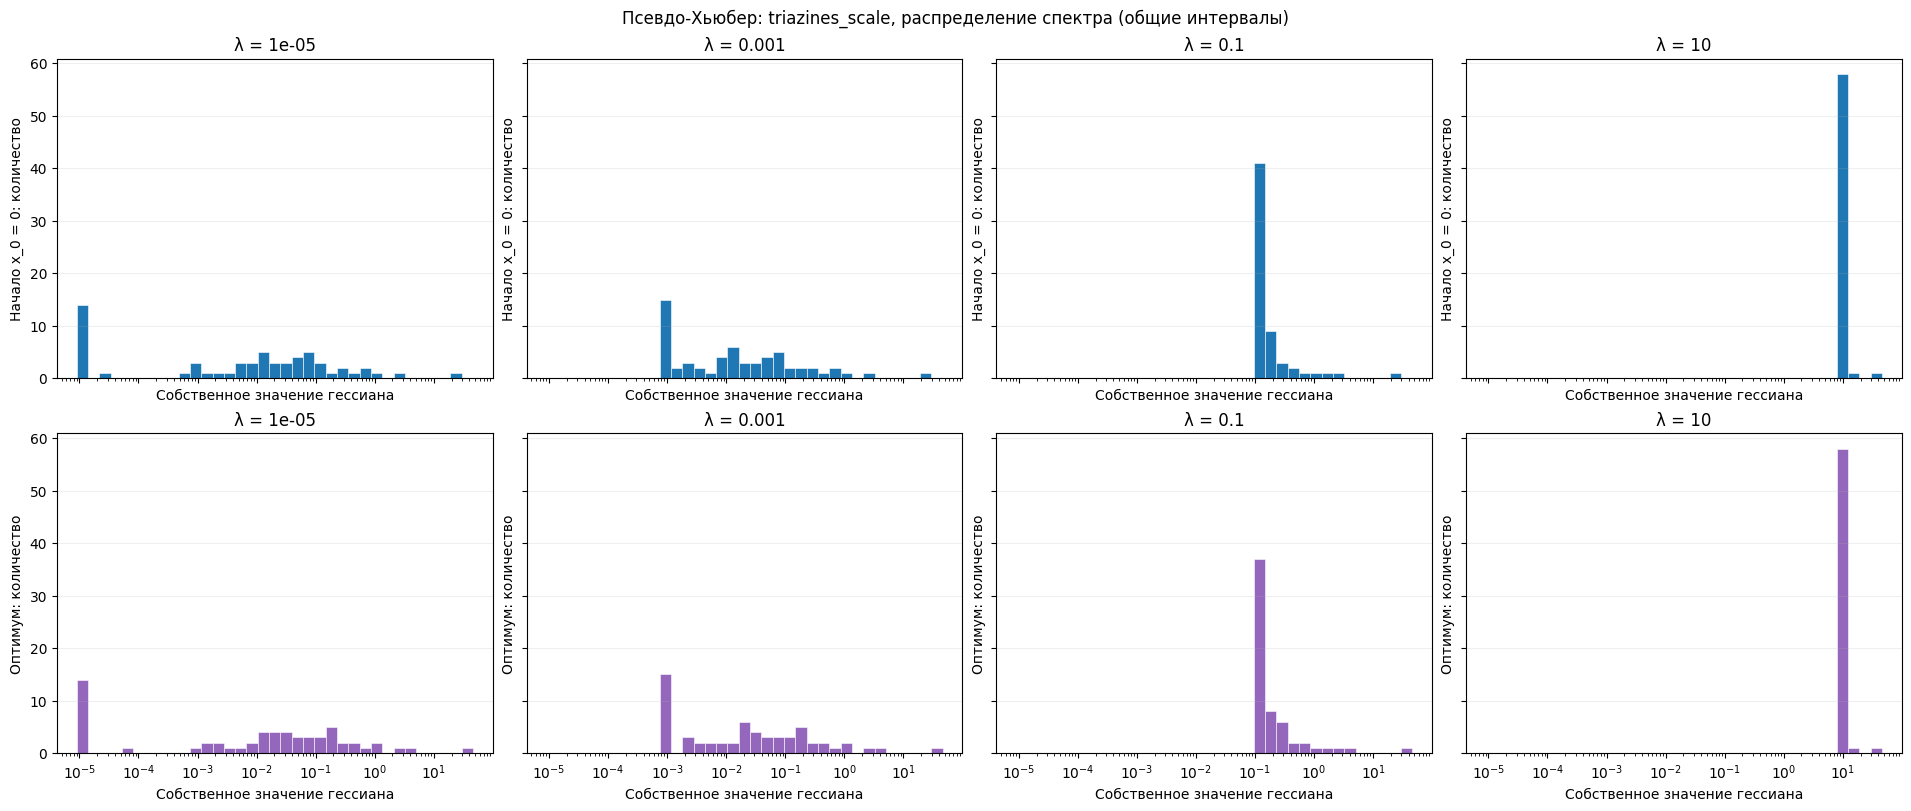

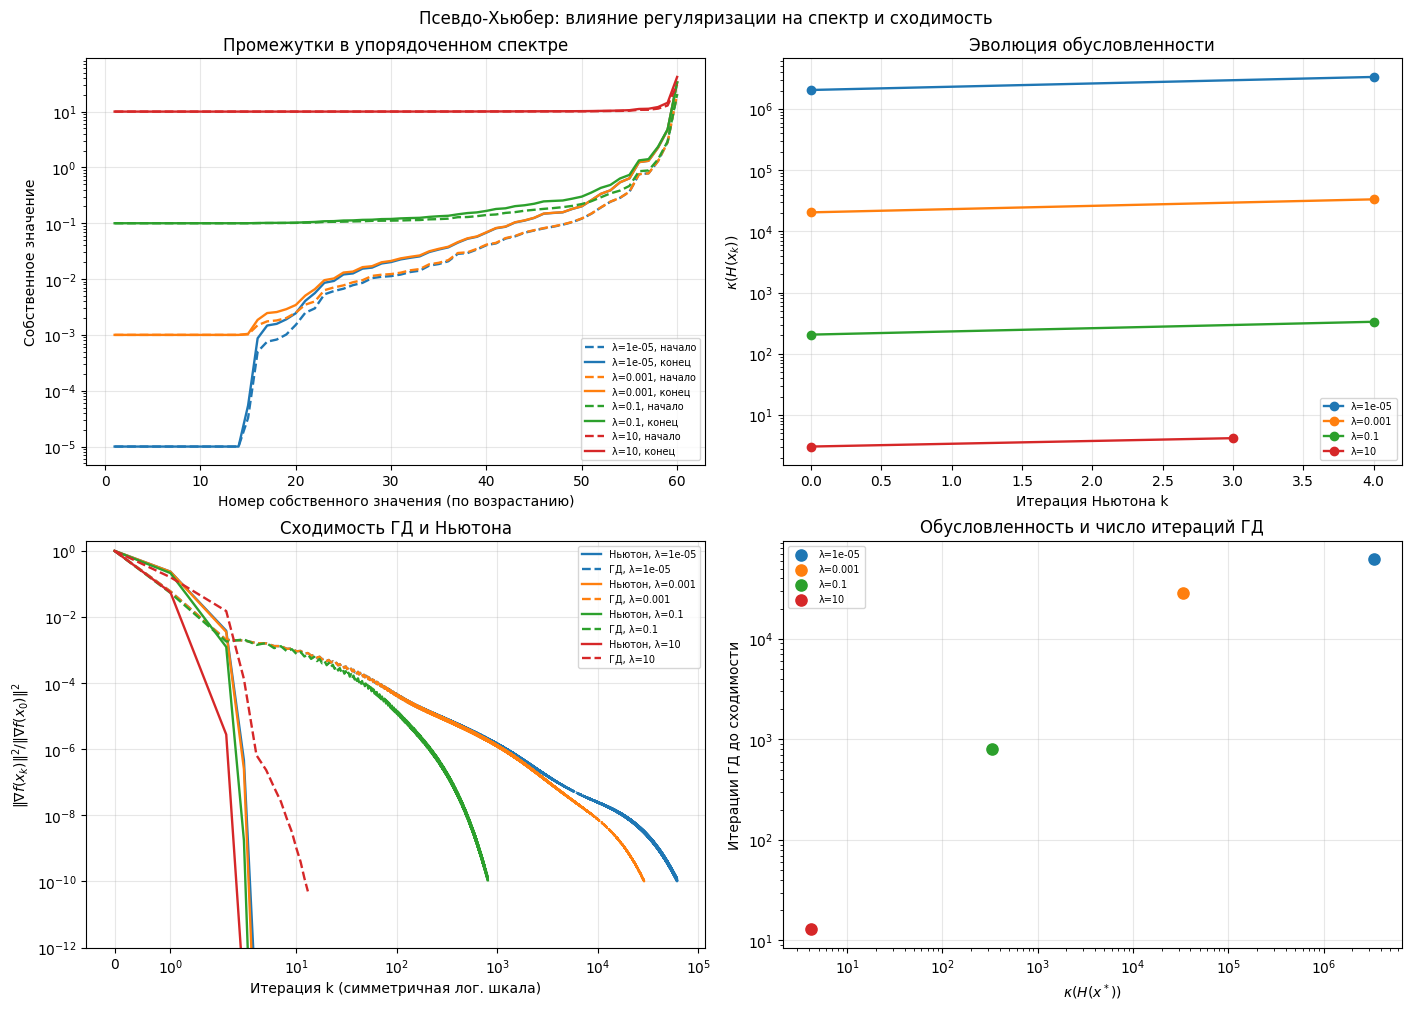

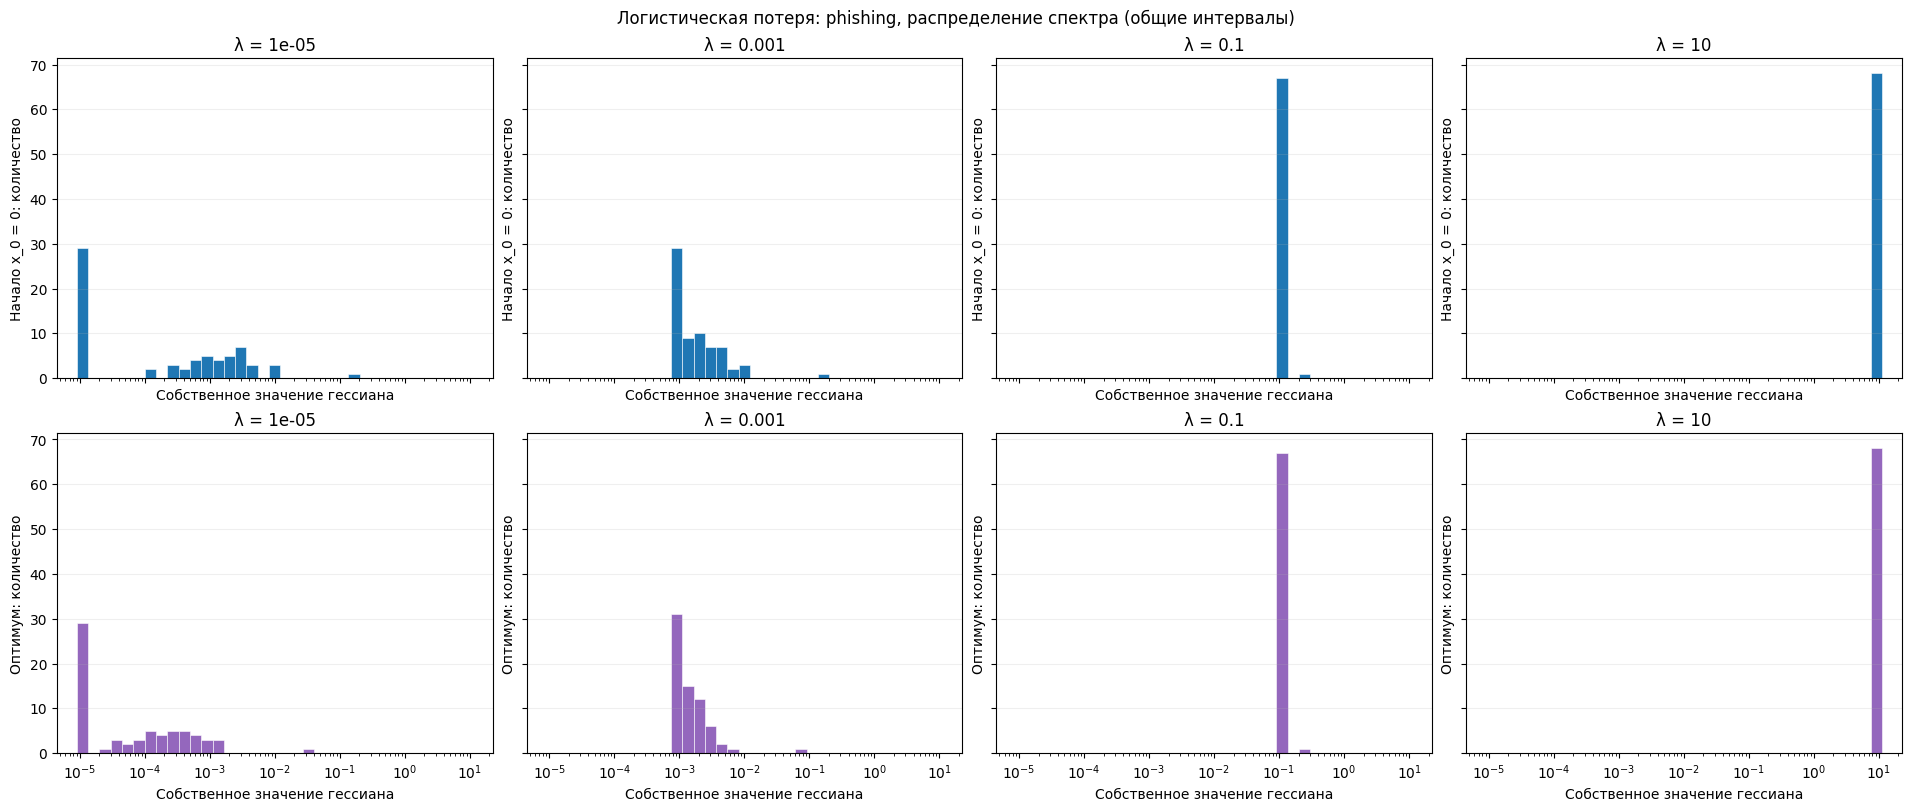

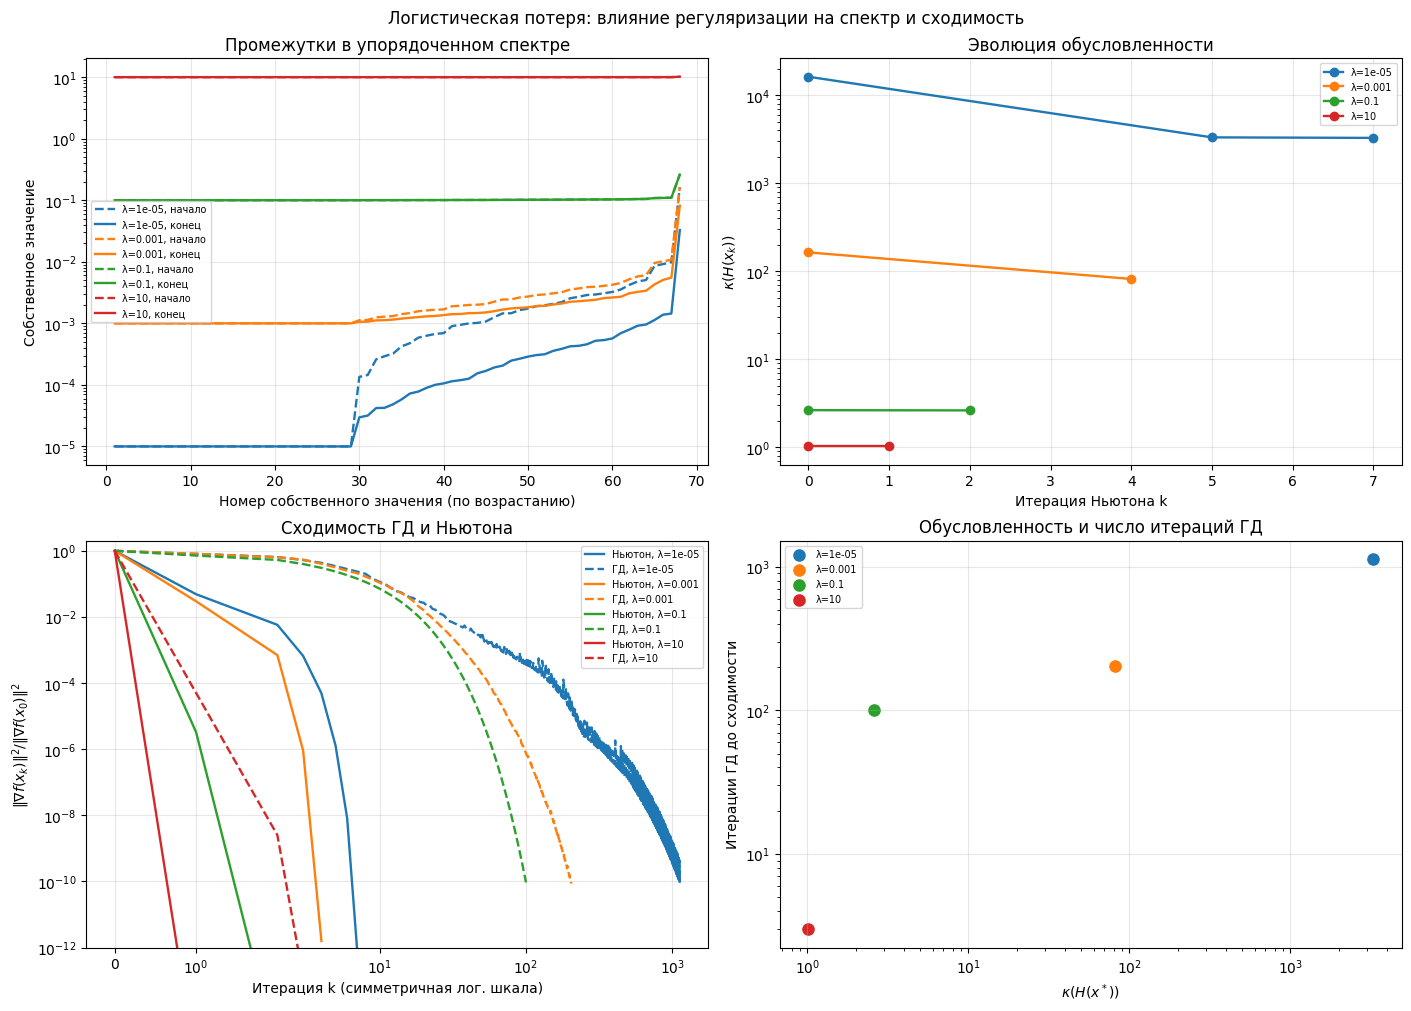

In [57]:
exp7_figures = {}
for loss_name, data in exp6_selected.items():
    all_spectra = np.concatenate([
        np.asarray(exp7_results[(loss_name, regcoef)]['history']['spectrum_values']).ravel()
        for regcoef in exp7_lambdas
    ])
    positive = all_spectra[all_spectra > 0]
    bins = np.geomspace(positive.min() * 0.9, positive.max() * 1.1, 36)
    hist_fig, axes = plt.subplots(2, len(exp7_lambdas), figsize=(19, 8),
                                  sharex=True, sharey=True, constrained_layout=True)
    for col, regcoef in enumerate(exp7_lambdas):
        result = exp7_results[(loss_name, regcoef)]
        spectra = np.asarray(result['history']['spectrum_values'])
        for row, spectrum in enumerate([spectra[0], spectra[-1]]):
            ax = axes[row, col]
            ax.hist(spectrum[spectrum > 0], bins=bins, color=['tab:blue', 'tab:purple'][row],
                     edgecolor='white', linewidth=0.4)
            ax.set_xscale('log')
            ax.set_title(f'lambda = {regcoef:g}')
            ax.set_xlabel('Собственное значение гессиана')
            terminal = 'Оптимум' if result['message'] == 'success' else 'Конечная точка'
            ax.set_ylabel(('Начало x_0 = 0' if row == 0 else terminal) + ': количество')
            if np.any(spectrum <= 0):
                ax.text(0.02, 0.95, f'Неположительных: {np.count_nonzero(spectrum <= 0)}',
                         transform=ax.transAxes, va='top', fontsize=8)
            ax.grid(axis='y', alpha=0.2)
    hist_fig.suptitle(f'{loss_name}: {data["name"]}, распределение спектра (общие интервалы)')
    experiment_prepare_figure(hist_fig)
    hist_fig.savefig(experiment_output_dir / f'exp7_{loss_name}_histograms.png', dpi=180)
    exp7_figures[(loss_name, 'histograms')] = hist_fig
    plt.show()
    plt.close(hist_fig)

    fig, panels = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
    for index, regcoef in enumerate(exp7_lambdas):
        color = f'C{index}'
        result = exp7_results[(loss_name, regcoef)]
        history = result['history']
        spectra = np.asarray(history['spectrum_values'])
        for position, linestyle, label in [(0, '--', 'начало'), (-1, '-', 'конец')]:
            panels[0, 0].plot(np.arange(1, spectra.shape[1] + 1),
                              np.maximum(spectra[position], np.finfo(float).tiny),
                              color=color, linestyle=linestyle, linewidth=1.7,
                              label=f'lambda={regcoef:g}, {label}')
        conditions = [exp7_condition(spectrum) for spectrum in spectra]
        panels[0, 1].plot(history['spectrum_iter'], conditions, marker='o',
                          color=color, linewidth=1.7, label=f'lambda={regcoef:g}')
        gd_result = exp6_results[(loss_name, regcoef, 'GD')]
        for method_name, run, linestyle in [('Newton', result, '-'), ('GD', gd_result, '--')]:
            ratio = experiment_relative_gradient(run['history'])
            panels[1, 0].plot(np.arange(len(ratio)), np.maximum(ratio, np.finfo(float).tiny),
                              color=color, linestyle=linestyle, linewidth=1.7,
                              label=f'{method_name}, lambda={regcoef:g}')
        if gd_result['message'] == 'success' and result['message'] == 'success':
            panels[1, 1].scatter(conditions[-1], gd_result['iterations'], color=color, s=65,
                                 label=f'lambda={regcoef:g}')
    panels[0, 0].set(yscale='log', xlabel='Номер собственного значения (по возрастанию)',
                     ylabel='Собственное значение', title='Промежутки в упорядоченном спектре')
    panels[0, 1].set(yscale='log', xlabel='Итерация Ньютона k', ylabel=r'$\kappa(H(x_k))$',
                     title='Эволюция обусловленности')
    panels[1, 0].set(xscale='symlog', yscale='log', xlabel='Итерация k (symlog)',
                     ylabel=r'$\|\nabla f(x_k)\|^2/\|\nabla f(x_0)\|^2$',
                     ylim=(exp6_tolerance * 0.01, 2), title='Сходимость ГД и Ньютона')
    panels[1, 1].set(xscale='log', yscale='log', xlabel=r'$\kappa(H(x^*))$',
                     ylabel='Итерации ГД до сходимости', title='Обусловленность и число итераций ГД')
    for ax in panels.flat:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    fig.suptitle(f'{loss_name}: влияние регуляризации на спектр и сходимость')
    experiment_prepare_figure(fig)
    fig.savefig(experiment_output_dir / f'exp7_{loss_name}_spectral_evolution.png', dpi=180)
    exp7_figures[(loss_name, 'evolution')] = fig
    plt.show()
    plt.close(fig)


### Точность вычислений: float32 против float64

В машинном обучении ради скорости часто используют одинарную точность (`float32`), а классическая оптимизация строится на двойной (`float64`).

**Задание.**
1. Приведите $A$, $b$ (и все промежуточные векторы) к типу `np.float32`. Запустите градиентный спуск и метод Ньютона до стагнации нормы градиента (установите очень малый `tolerance`). Повторите для `np.float64`. Проверьте, что вычисления действительно идут в `float32`: тип легко «утекает» в `float64`, например через Python-скаляры или `scipy`.
2. Профилируйте время каждой итерации по трём компонентам: (а) вызов оракула (градиент и гессиан), (б) линейный поиск, (в) решение линейной системы (разложение Холецкого).

Постройте график нормы градиента (в логарифмической шкале) от номера итерации для обеих точностей и найдите момент, когда ошибка округления начинает доминировать над шагом метода. Какой точности оптимизации способен достичь каждый метод в `float32` и в `float64`? Постройте столбчатые диаграммы долей времени по трём компонентам. Есть ли реальный выигрыш во времени от перехода на `float32`? Где именно numpy/scipy ускоряются, а где время не меняется? Объясните через устройство BLAS/LAPACK и кэша процессора.

final_dtype               status  iterations  \
loss        method dtype                                                  
pseudohuber GD     float32     float32  line_search_stopped          31   
            Newton float32     float32  gradient_stagnation          77   
            GD     float64     float64  line_search_stopped         103   
            Newton float64     float64  gradient_stagnation          74   
logistic    GD     float32     float32  gradient_stagnation         100   
            Newton float32     float32  gradient_stagnation          65   
            GD     float64     float64  gradient_stagnation         250   
            Newton float64     float64  gradient_stagnation          53   

                            minimum_grad_norm  oracle_seconds  \
loss        method dtype                                        
pseudohuber GD     float32           0.000379        0.009508   
            Newton float32           0.000000        0.143176   
            GD     float64           0.000000        0.053041   
            Newton float64           0.000000        0.263294   
logistic    GD     float32           0.000124        0.040719   
            Newton float32           0.000000        0.127321   
            GD     float64           0.000000        0.135726   
            Newton float64           0.000000        0.184883   

                            line_search_seconds  linear_system_seconds  
loss        method dtype                                                
pseudohuber GD     float32             0.020730               0.000000  
            Newton float32             0.035509               0.007189  
            GD     float64             0.106991               0.000000  
            Newton float64             0.060609               0.008780  
logistic    GD     float32             0.091047               0.000000  
            Newton float32             0.037928               0.006261  
            GD     float64             0.280440               0.000000  
            Newton float64             0.079449               0.006112

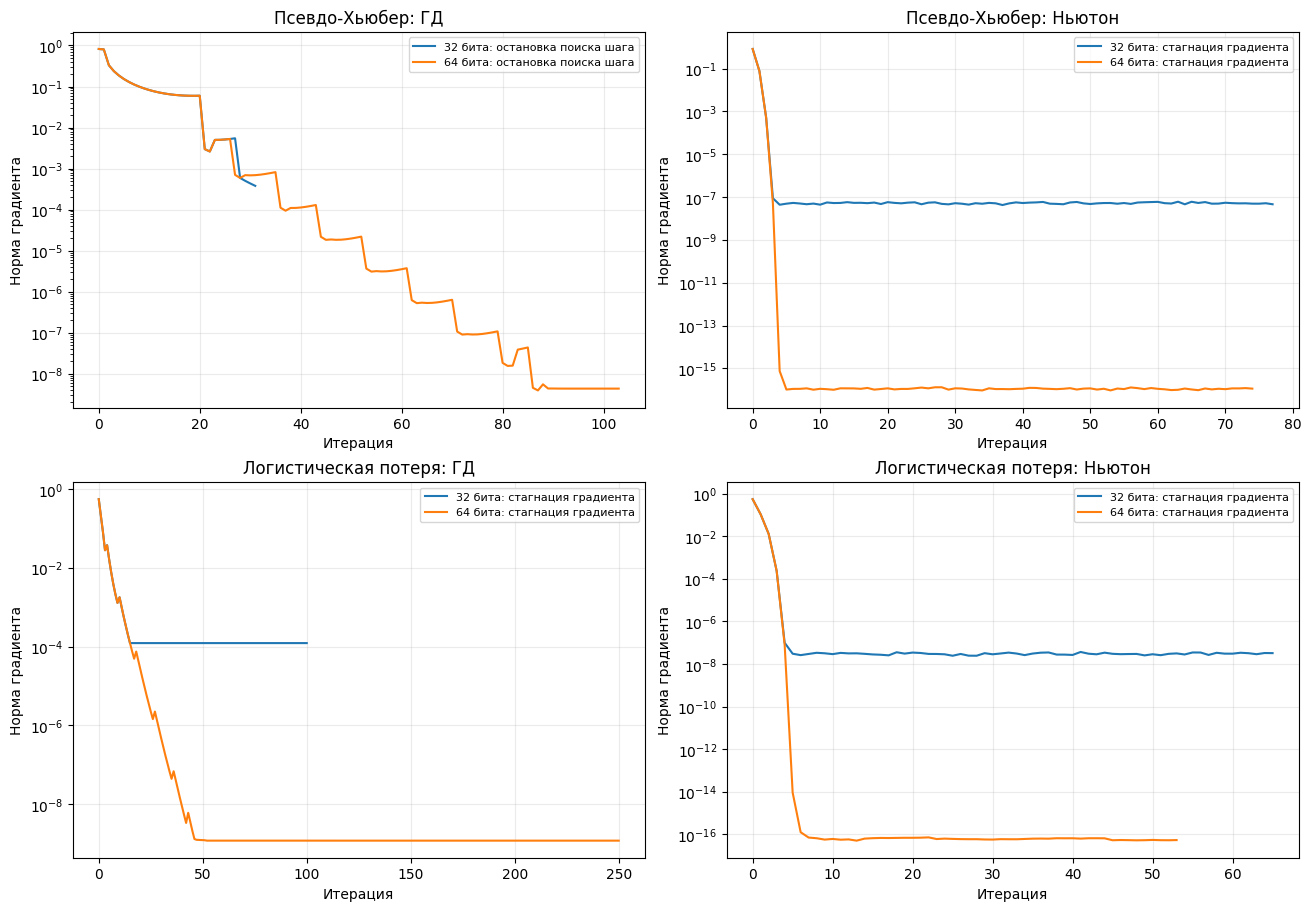

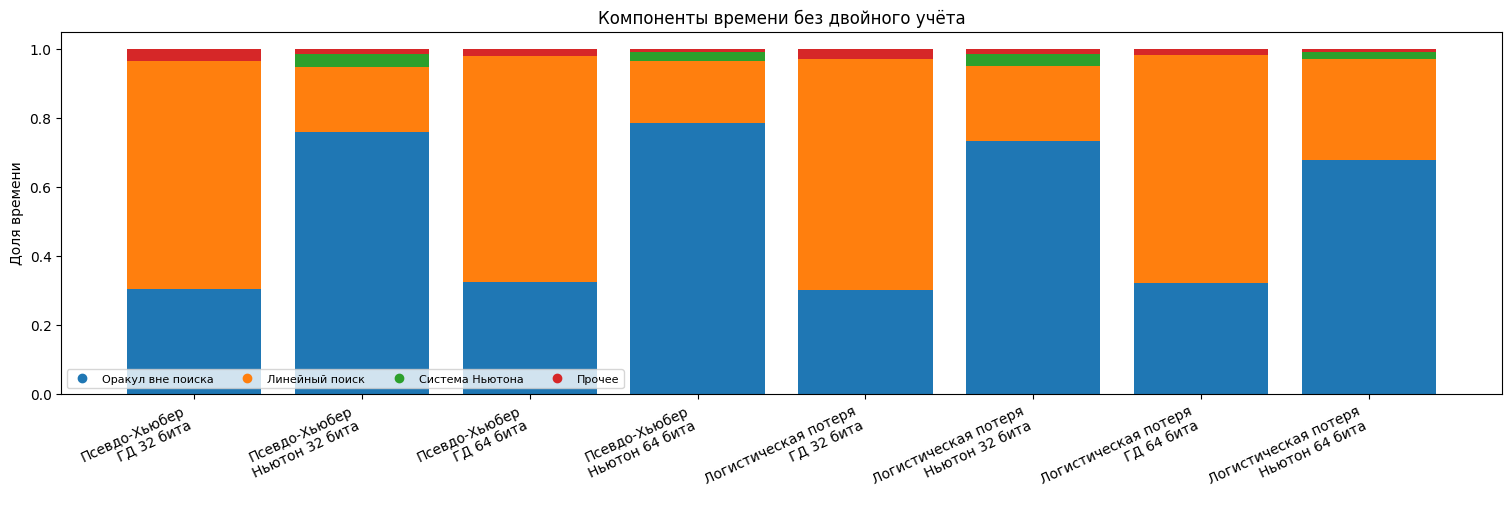

Время линейного поиска включает вызовы оракула внутри него; они не входят во второй раз в оракул.


In [58]:
def experiment_precision_optimizer(oracle, x_0, method='GD', tolerance=1e-40,
                                    max_iter=5000, patience=40,
                                    trace=False, display=False):
    """Контролируем dtype и измеряем неперекрывающиеся части итерации."""
    point=np.array(x_0,copy=True)
    dtype=point.dtype
    if dtype not in (np.dtype('float32'),np.dtype('float64')):
        raise TypeError('Для исследования задайте float32 или float64')
    history=defaultdict(list) if trace else None
    search=LineSearchTool(method='Armijo')
    parts=np.zeros(3,dtype=float)
    started=time.perf_counter()
    previous_step=None
    initial_squared=None
    best_norm=np.inf
    stalled=0

    def finish(status):
        if trace:
            duration=time.perf_counter()-started
            history['profile_seconds']=np.r_[parts,max(0.,duration-parts.sum())]
        return point,status,history

    for iteration in range(max_iter+1):
        stage=time.perf_counter()
        value,gradient=oracle.func(point),oracle.grad(point)
        hessian=oracle.hess(point) if method=='Newton' else None
        parts[0]+=time.perf_counter()-stage
        if gradient.dtype!=dtype or (hessian is not None and hessian.dtype!=dtype):
            raise TypeError(f'Изменился dtype производных: ожидался {dtype}')
        squared=float(np.dot(gradient,gradient))
        if not np.isfinite(value) or not np.isfinite(squared):
            return finish('computational_error')
        norm=np.sqrt(squared)
        if initial_squared is None:
            initial_squared=squared
        if trace:
            history['time'].append(time.perf_counter()-started)
            history['func'].append(float(value))
            history['grad_norm'].append(norm)
            history['point_dtype_bits'].append(dtype.itemsize*8)
        if squared<=tolerance*initial_squared:
            return finish('success')
        if norm<best_norm*(1-8*np.finfo(dtype).eps):
            best_norm,stalled=norm,0
        else:
            stalled+=1
        if stalled>=patience:
            return finish('gradient_stagnation')
        if iteration==max_iter:
            return finish('iterations_exceeded')
        if method=='Newton':
            stage=time.perf_counter()
            try:
                factor=scipy.linalg.cho_factor(hessian,lower=True)
                direction=scipy.linalg.cho_solve(factor,-gradient)
            except LinAlgError:
                return finish('newton_direction_error')
            parts[2]+=time.perf_counter()-stage
            if factor[0].dtype!=dtype or direction.dtype!=dtype:
                raise TypeError('Изменился dtype при решении системы')
            alpha_start=1.0
        else:
            direction=-gradient
            alpha_start=None if previous_step is None else 2*previous_step
        stage=time.perf_counter()
        step=search.line_search(oracle,point,direction,previous_alpha=alpha_start)
        parts[1]+=time.perf_counter()-stage
        if step is None:
            return finish('line_search_stopped')
        candidate=point+dtype.type(step)*direction
        if candidate.dtype!=dtype:
            raise TypeError('Изменился dtype следующей точки')
        if np.array_equal(candidate,point):
            return finish('point_stagnation')
        if not np.all(np.isfinite(candidate)):
            return finish('computational_error')
        point=candidate
        previous_step=step
    return finish('iterations_exceeded')


precision_rng=np.random.default_rng(np.random.SeedSequence([SEED,32]))
precision_m, precision_n = 4000, 96
precision_A=precision_rng.normal(size=(precision_m,precision_n))*np.geomspace(.5,2.,precision_n)
precision_truth=precision_rng.normal(size=precision_n)/np.sqrt(precision_n)
precision_targets={
    'pseudohuber':precision_A@precision_truth+.1*precision_rng.normal(size=precision_m),
    'logistic':np.where(precision_A@precision_truth+.3*precision_rng.normal(size=precision_m)>0,1.,-1.),
}
precision_results={}
precision_rows=[]
for loss_name in MY_LOSSES:
    for dtype in [np.float32,np.float64]:
        matrix=precision_A.astype(dtype)
        targets=precision_targets[loss_name].astype(dtype)
        oracle=create_linear_model_oracle(matrix,targets,dtype(.1),loss_name)
        for method in ['GD','Newton']:
            run=experiment_run('precision',oracle,np.zeros(precision_n,dtype=dtype),
                experiment_precision_optimizer,
                problem={'loss':loss_name,'dtype':np.dtype(dtype).name,
                         'fingerprint':experiment_fingerprint(matrix,targets)},
                method=method,max_iter=5000 if method=='GD' else 150)
            precision_results[(loss_name,method,np.dtype(dtype).name)]=run
            times=np.asarray(run['history']['profile_seconds'])
            norms=np.asarray(run['history']['grad_norm'])
            precision_rows.append({'loss':loss_name,'method':method,'dtype':np.dtype(dtype).name,
                'final_dtype':str(run['x_opt'].dtype),'status':run['message'],
                'iterations':run['iterations'],'minimum_grad_norm':float(norms.min()),
                'final_relative_grad_sq':float((norms[-1]/norms[0])**2),
                'oracle_seconds':times[0],'line_search_seconds':times[1],
                'linear_system_seconds':times[2],'other_seconds':times[3]})
experiment_save_table('precision_profile.csv',precision_rows)
experiment_show_table(precision_rows,index=['loss','method','dtype'],
    values=['final_dtype','status','iterations','minimum_grad_norm',
            'oracle_seconds','line_search_seconds','linear_system_seconds'])
fig,panels=plt.subplots(len(MY_LOSSES),2,figsize=(13,9),constrained_layout=True,squeeze=False)
for row,loss_name in enumerate(MY_LOSSES):
    for col,method in enumerate(['GD','Newton']):
        for dtype in ['float32','float64']:
            run=precision_results[(loss_name,method,dtype)]
            panels[row,col].semilogy(np.maximum(run['history']['grad_norm'],np.finfo(float).tiny),
                                     label=f"{dtype}: {run['message']}")
        panels[row,col].set(xlabel='Итерация',ylabel='Норма градиента',title=f'{loss_name}: {method}')
        panels[row,col].legend(fontsize=8);panels[row,col].grid(alpha=.25)
experiment_prepare_figure(fig)
fig.savefig(FIGURES_DIR/'precision_convergence.png',dpi=180)
plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(15,5),constrained_layout=True)
bottom=np.zeros(len(precision_rows))
for key,label in [('oracle_seconds','Оракул вне поиска'),('line_search_seconds','Линейный поиск'),
                  ('linear_system_seconds','Система Ньютона'),('other_seconds','Прочее')]:
    total=np.array([sum(r[k] for k in ['oracle_seconds','line_search_seconds',
                                      'linear_system_seconds','other_seconds']) for r in precision_rows])
    share=np.array([r[key] for r in precision_rows])/np.maximum(total,np.finfo(float).tiny)
    ax.bar(np.arange(len(share)),share,bottom=bottom,label=label);bottom+=share
ax.set_xticks(np.arange(len(precision_rows)),
               [f"{r['loss']}\n{r['method']} {r['dtype']}" for r in precision_rows],rotation=25,ha='right')
ax.set(ylabel='Доля времени',title='Компоненты времени без двойного учёта')
ax.legend(handles=[
    Line2D([], [], marker='o', linestyle='None', color=bars[0].get_facecolor(),
           label=bars.get_label()) for bars in ax.containers
], ncol=4, fontsize=8)
experiment_prepare_figure(fig)
fig.savefig(FIGURES_DIR/'precision_time_components.png',dpi=180)
plt.show();plt.close(fig)
print('Время линейного поиска включает вызовы оракула внутри него; они не входят во второй раз в оракул.')


### Диагональное предобуславливание

Итерация градиентного спуска стоит дёшево, но он страдает от плохой обусловленности. Метод Ньютона решает эту проблему за счёт полного учёта кривизны, но требует $O(n^3)$ на разложение Холецкого. Компромисс — учитывать только диагональ гессиана.

**Задание.**
1. Реализуйте модифицированный градиентный спуск $x_{k+1} = x_k - \alpha_k\, [\mathrm{Diag}(\nabla^2 f(x_k))]^{-1} \nabla f(x_k)$. Диагональ гессиана вычисляйте за $O(\mathrm{nnz}(A))$, не формируя полную матрицу.
2. Протестируйте метод на ML-оракулах с линейным поиском по Армихо.

Сравните его с обычным градиентным спуском и полным методом Ньютона. Постройте графики «относительная невязка от времени работы» на «широком» датасете. Насколько учёт только диагональной кривизны сокращает число итераций? Насколько итерация дешевле, чем у полного Ньютона? В каких случаях диагональное предобуславливание бесполезно?


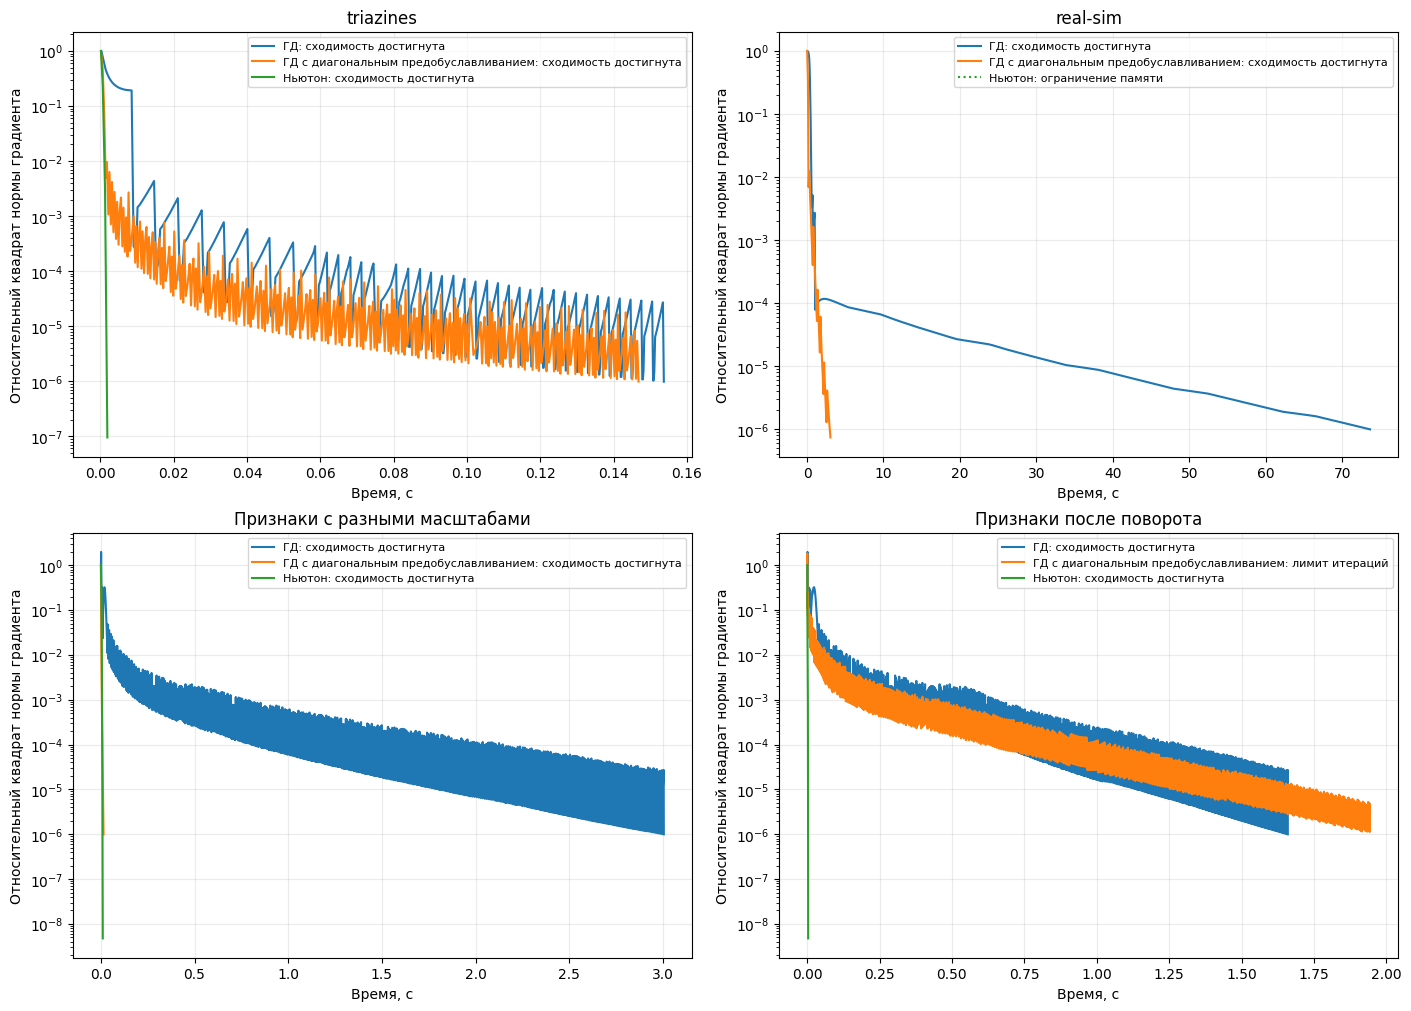

status  iterations    seconds  \
case              method                                                    
triazines         GD                       success       564.0   0.153790   
                  Diagonal GD              success       417.0   0.146875   
                  Newton                   success         3.0   0.001947   
real-sim          GD                       success      1231.0  73.637819   
                  Diagonal GD              success        36.0   3.062320   
                  Newton            skipped_memory         NaN        NaN   
synthetic_axes    GD                       success      4719.0   3.004759   
                  Diagonal GD              success        21.0   0.014462   
                  Newton                   success         5.0   0.010287   
synthetic_rotated GD                       success      4719.0   1.659943   
                  Diagonal GD  iterations_exceeded      5000.0   1.943841   
                  Newton                   success         5.0   0.003653   

                               milliseconds_per_iteration  relative_grad_sq  \
case              method                                                      
triazines         GD                             0.272677          0.000001   
                  Diagonal GD                    0.352219          0.000001   
                  Newton                         0.649120          0.000000   
real-sim          GD                            59.819512          0.000001   
                  Diagonal GD                   85.064442          0.000001   
                  Newton                              NaN               NaN   
synthetic_axes    GD                             0.636736          0.000001   
                  Diagonal GD                    0.688678          0.000001   
                  Newton                         2.057434          0.000000   
synthetic_rotated GD                             0.351757          0.000001   
                  Diagonal GD                    0.388768          0.000003   
                  Newton                         0.730531          0.000000   

                               diagonal_calls  
case              method                       
triazines         GD                        0  
                  Diagonal GD             417  
                  Newton                    0  
real-sim          GD                        0  
                  Diagonal GD              36  
                  Newton                    0  
synthetic_axes    GD                        0  
                  Diagonal GD              21  
                  Newton                    0  
synthetic_rotated GD                        0  
                  Diagonal GD            5000  
                  Newton                    0

status  iterations    seconds  \
case              method                                                    
triazines         GD                       success       564.0   0.153790   
                  Diagonal GD              success       417.0   0.146875   
                  Newton                   success         3.0   0.001947   
real-sim          GD                       success      1231.0  73.637819   
                  Diagonal GD              success        36.0   3.062320   
                  Newton            skipped_memory         NaN        NaN   
synthetic_axes    GD                       success      4719.0   3.004759   
                  Diagonal GD              success        21.0   0.014462   
                  Newton                   success         5.0   0.010287   
synthetic_rotated GD                       success      4719.0   1.659943   
                  Diagonal GD  iterations_exceeded      5000.0   1.943841   
                  Newton                   success         5.0   0.003653   

                               milliseconds_per_iteration  relative_grad_sq  \
case              method                                                      
triazines         GD                             0.272677      9.785679e-07   
                  Diagonal GD                    0.352219      9.867380e-07   
                  Newton                         0.649120      9.513777e-08   
real-sim          GD                            59.819512      9.982514e-07   
                  Diagonal GD                   85.064442      7.428824e-07   
                  Newton                              NaN               NaN   
synthetic_axes    GD                             0.636736      9.962563e-07   
                  Diagonal GD                    0.688678      9.898719e-07   
                  Newton                         2.057434      4.761103e-09   
synthetic_rotated GD                             0.351757      9.962563e-07   
                  Diagonal GD                    0.388768      2.923787e-06   
                  Newton                         0.730531      4.761103e-09   

                               diagonal_calls  
case              method                       
triazines         GD                        0  
                  Diagonal GD             417  
                  Newton                    0  
real-sim          GD                        0  
                  Diagonal GD              36  
                  Newton                    0  
synthetic_axes    GD                        0  
                  Diagonal GD              21  
                  Newton                    0  
synthetic_rotated GD                        0  
                  Diagonal GD            5000  
                  Newton                    0

In [59]:
precondition_rng=np.random.default_rng(np.random.SeedSequence([SEED,91]))
base_features=precondition_rng.normal(size=(900,40))*np.geomspace(.1,10.,40)
reference=precondition_rng.normal(size=40)/np.geomspace(.1,10.,40)
synthetic_labels=np.where(base_features@reference+.2*precondition_rng.normal(size=900)>0,1.,-1.)
basis,_=np.linalg.qr(precondition_rng.normal(size=(40,40)))
precondition_cases={
    'triazines':(A_triazines,b_triazines,'pseudohuber'),
    'real-sim':(A_real_sim,b_real_sim,'logistic'),
    'synthetic_axes':(base_features,synthetic_labels,'logistic'),
    'synthetic_rotated':(base_features@basis,synthetic_labels,'logistic'),
}
precondition_results={}
precondition_rows=[]
fig,panels=plt.subplots(2,2,figsize=(14,10),constrained_layout=True)
for ax,(case,(matrix,targets,loss_name)) in zip(panels.flat,precondition_cases.items()):
    oracle=create_linear_model_oracle(matrix,targets,1/len(targets),loss_name)
    for label,optimizer,limit in [('GD',gradient_descent,5000),
                                  ('Diagonal GD',experiment_preconditioned_gd,5000),
                                  ('Newton',newton,100)]:
        if label=='Newton' and not experiment_newton_memory(matrix)[0]:
            precondition_rows.append({'case':case,'method':label,'status':'skipped_memory',
                'iterations':None,'seconds':None,'milliseconds_per_iteration':None,
                'relative_grad_sq':None,'diagonal_calls':0})
            ax.plot([],[],label='Ньютон: ограничение памяти',linestyle=':')
            continue
        run=experiment_run('preconditioning',oracle,np.zeros(matrix.shape[1]),optimizer,
            problem={'case':case,'loss':loss_name,'fingerprint':experiment_fingerprint(matrix,targets)},
            tolerance=1e-6,max_iter=limit,line_search_options={'method':'Armijo'})
        precondition_results[(case,label)]=run
        relative=experiment_relative_gradient(run['history'])
        ax.semilogy(run['history']['time'],np.maximum(relative,np.finfo(float).tiny),
                    label=f"{label}: {run['message']}")
        precondition_rows.append({'case':case,'method':label,'status':run['message'],
            'iterations':run['iterations'],'seconds':run['elapsed'],
            'milliseconds_per_iteration':1000*run['elapsed']/max(1,run['iterations']),
            'relative_grad_sq':float(relative[-1]),'diagonal_calls':run['calls']['hess_diag']})
    ax.set(xlabel='Время, с',ylabel='Относительный квадрат нормы градиента',title=case)
    ax.legend(fontsize=8);ax.grid(alpha=.25)
experiment_prepare_figure(fig)
fig.savefig(FIGURES_DIR/'diagonal_preconditioning.png',dpi=180)
plt.show();plt.close(fig)
experiment_save_table('diagonal_preconditioning.csv',precondition_rows)
experiment_show_table(precondition_rows,index=['case','method'])


In [60]:
from collections import Counter
from datetime import datetime, timezone

dataset_table = []
for name, A, task, filename, source in [
    ('mg_scale', A_mg, 'regression', 'mg_scale.txt',
     'https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/regression/mg_scale'),
    ('triazines_scale', A_triazines, 'regression', 'triazines_scale.txt',
     'https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/regression/triazines_scale'),
    ('phishing', A_phishing, 'classification', 'phishing.txt',
     'https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/binary/phishing'),
    ('real-sim', A_real_sim, 'classification', 'real-sim',
     'https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/binary/real-sim.bz2'),
]:
    dataset_table.append({'dataset': name, 'task': task, 'path': str(DATA_DIR / filename),
                          'source': source, 'm': A.shape[0], 'n': A.shape[1],
                          'nnz': int(A.nnz if scipy.sparse.issparse(A) else np.count_nonzero(A)),
                          'storage': type(A).__name__,
                          'density': (A.nnz if scipy.sparse.issparse(A) else np.count_nonzero(A)) / (A.shape[0] * A.shape[1])})
experiment_save_table('datasets.csv', dataset_table)

run_status_summary = []
for section, results in [
    ('1_quadratic', exp1_results), ('1_rosenbrock', exp1_rosen_results),
    ('2_GD', exp2_results), ('2_Newton', exp2_newton_results),
    ('3', exp3_results), ('4', exp4_results), ('5', exp5_results),
    ('6', exp6_results), ('7.2', exp7_results),
    ('1_geometry_extra', exp1_rotated_results), ('1_himmelblau', exp1_himmelblau_results),
    ('2_Wolfe_extra', exp2_wolfe_results), ('precision', precision_results),
    ('preconditioning', precondition_results),
]:
    counts = Counter(result['message'] for result in results.values())
    for status, count in sorted(counts.items()):
        run_status_summary.append({'experiment': section, 'status': status, 'runs': count})
for method_name, result in exp1_rosen_basins.items():
    for status, count in sorted(Counter(result['messages'].ravel().tolist()).items()):
        run_status_summary.append({'experiment': '1_basins_' + method_name,
                                   'status': status, 'runs': count})
experiment_save_table('run_status_summary.csv', run_status_summary)
run_manifest = {
    'finished_utc': datetime.now(timezone.utc).isoformat(), 'seed': SEED,
    'hardware': experiment_machine, 'datasets': dataset_table,
    'basin_parameters': json.loads(exp1_rosen_config_json),
    'basin_archive': str(exp1_rosen_basin_result_path.resolve()),
    'experiment_7_variant': exp7_variant,
    'result_cache': str(RESULTS_DIR.resolve()),
    'figures_and_tables': str(FIGURES_DIR.resolve()),
    'statuses': run_status_summary,
    'files': sorted(path.name for path in FIGURES_DIR.iterdir() if path.is_file()),
}
with (FIGURES_DIR / 'run_manifest.json').open('w', encoding='utf-8') as stream:
    json.dump(run_manifest, stream, ensure_ascii=False, indent=2)
print('Обязательные эксперименты выполнены. Статусы запусков:')
for row in run_status_summary:
    print(f"{row['experiment']:<22} {row['status']:<25} {row['runs']:>6}")
print(f'Графики и таблицы: {FIGURES_DIR.resolve()}')
print(f'Кэш и истории: {RESULTS_DIR.resolve()}')
print('iterations_exceeded, computational_error и skipped_memory — статусы отдельных '
      'экспериментальных запусков; их причины сохранены в таблицах.')


Обязательные эксперименты выполнены. Статусы запусков:
1_quadratic            success                       24
1_rosenbrock           newton_direction_error         1
1_rosenbrock           success                        7
2_GD                   success                      200
2_Newton               success                       18
3                      skipped_memory                 1
3                      success                        7
4                      computational_error            3
4                      iterations_exceeded            4
4                      success                      101
5                      iterations_exceeded           18
5                      success                       54
6                      success                       28
7.2                    success                        8
1_geometry_extra       success                        8
1_himmelblau           newton_direction_error         3
1_himmelblau           success                   